# Explication du projet

Pour atteindre son objectif de ville neutre en émissions de carbone en 2050, la ville de Seattle souhaite étudier finement la consommation ainsi que les émissions des bâtiments non destinés à l’habitation. L'objectif principal sera de prédire ces deux variables à partir de données structurelles liées aux batiments. Un objectif secondaire sera d'étudier l'impact de la variable EnergyStar sur les résultats de prédictions afin de déterminer s'il est nécéssaire de continuer à calculer ce score. Le présent notebook sera dédié à la prédiction des valeurs de la variable <u>'SiteEnergyUse(kBtu)'<u>

# Sommaire

- [3 Import](#Import-des-bibliothèques-et-des-données)
- [4 Prétraitement général](#Prétraitement-général)
- [5 Séparation des données ](#Séparation-des-données )
- [6 Feature engineering](#Feature-engineering)
- [7 Fonctions d'évaluation de la performance du modèle](#Fonctions-d'évaluation-de-la-performance-du-modèle)
- [8 Préprocessing des données](#Préprocessing)
- [9 Premier modele : LinearRegression](#Premier-modele:-LinearRegression)
- [10 Autres modèles](#Autres-modèles)
- [11 Modification du préprocessing](#Modification-du-préprocessing)
- [12 Optimisations](#Optimisation)
- [13 Impact ENERGYStar](#Impact-ENERGYStar)
- [14 Evaluation détaillée du modèle final](#Evaluation-détaillée-du-modele-final)
- [15 Conclusions](#Conclusions)



# Import des bibliothèques et des données

**Bibliothèques**

In [1]:
# Manipulation de données
import pandas as pd
import missingno as msno
import numpy as np

# Représentation graphique
import matplotlib.pyplot as plt
import seaborn as sns
from plotnine import *

# Explicativité modèle
import lime
import shap 

# Librairie sickit learn
from sklearn.model_selection import train_test_split, learning_curve, cross_val_score, KFold, GridSearchCV, StratifiedKFold, RandomizedSearchCV,  RepeatedStratifiedKFold
from sklearn.decomposition import PCA
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import RobustScaler, MinMaxScaler, OneHotEncoder, PolynomialFeatures, StandardScaler, OrdinalEncoder, TargetEncoder
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.metrics import mean_absolute_error
from sklearn.feature_selection import SelectKBest, f_regression, SelectFromModel
from sklearn.compose import ColumnTransformer,TransformedTargetRegressor
from sklearn.preprocessing import MinMaxScaler,  FunctionTransformer, PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, HistGradientBoostingRegressor, AdaBoostRegressor,GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_percentage_error, r2_score, mean_absolute_error,  make_scorer, root_mean_squared_error
from sklearn.svm import SVR
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.dummy import DummyRegressor

# Modèle hors scikit learn
from xgboost import XGBRegressor

# Gestion de certains warnings
import warnings

# Calcul temps d'execution
import time

**Données**

In [2]:
# Import du jeu de données obtenu lors du notebook d'exploration et de nettoyage
Data = pd.read_csv("../Output/Analyses exploratoires/Table/Final_Data.csv")
Data_brute = pd.read_csv("../Data/2016_Building_Energy_Benchmarking.csv")

In [3]:
# Visualisation du jeu de données
Data.head(5)

,PrimaryPropertyType,Neighborhood,NumberofFloors,PropertyGFAParking,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions,StreetType,Electricity_prop,SteamUse_prop,GFAbyfloor,MoreThanOneBuilding,AgeBuilding,nUseType
0,Logement,Downtown,12,0,60.0,7226362.5,249.98,Way,0.546060,0.277302,7369.500000,False,89,1
1,Logement,Downtown,11,15064,61.0,8387933.0,295.86,Street,0.386609,0.000000,8045.636364,False,20,3
2,Logement,Downtown,41,196718,43.0,72587024.0,2089.28,Avenue,0.682307,0.297113,18521.756098,False,47,1
3,Logement,Downtown,10,0,56.0,6794584.0,286.43,Street,0.407519,0.325913,6132.000000,False,90,1
4,Logement,Downtown,18,62000,75.0,14172606.0,505.01,Street,0.378802,0.000000,6310.000000,False,36,3


# Prétraitement général

Le jeu de données chargé contient les deux variables cibles. Il est donc nécessaire de définir une variable que l'on souhaite prédire et de supprimer l'autre du jeu de données. 
Plusieurs prétraitement des données vont être réalisés avant l'étape de modélisation. Ces prétraitement seront spécifiques à certaines features. Nous allons donc définir 3 listes de features.
- **log_cols** : Les features dont la distribution a été observée comme asyémtrique lors de l'étape d'exploration des données et pour lesquelles on testera un passage au logarithme. Ces features seront également normalisées via différentes méthodologie qui seront testées.
- **num_cols**: Les autres features numériques qui seront normalisées par les mêmes méthodologies
- **cat_cols** : Les features catégorielles qui seront encodées


In [4]:
# Définition de la variable qui sera prédite dans ce notebook
Variable_cible = 'SiteEnergyUse(kBtu)'

In [5]:
# Copie du jeu de données 
Data_ml = Data.copy()

# Suppression de la variable cible non étudiée dans ce notebook
Data_ml = Data_ml.drop(['TotalGHGEmissions'], axis=1)

# Création de listes contenant les variables qui seront transformées en début de pipeline
log_cols = ['PropertyGFAParking', 'GFAbyfloor']
num_cols = [col for col in Data_ml.columns 
                  if Data_ml[col].dtype in ['float64', 'int64'] and col != Variable_cible and col not in log_cols]
cat_cols = [col for col in Data_ml.columns 
                    if Data_ml[col].dtype in ['object', 'bool']]

# Création d'une liste contenant toutes les variables prédictives
Selected_features = [col for col in Data_ml.columns if (col != Variable_cible)]

# Visualisation de toutes les variables retenues pour la prédiction
Selected_features

['PrimaryPropertyType',
 'Neighborhood',
 'NumberofFloors',
 'PropertyGFAParking',
 'ENERGYSTARScore',
 'StreetType',
 'Electricity_prop',
 'SteamUse_prop',
 'GFAbyfloor',
 'MoreThanOneBuilding',
 'AgeBuilding',
 'nUseType']

# Séparation des données 

Afin de pouvoir entrainer un modèle et de le tester sur des données non vues, le jeu de données global va être scindé en deux. Il y aura un jeu de données dédié à l'entrainement du modèle, et un jeu de données dédié au test du modèle. Lors de la phase d'exploration des données, il a été noté que certaines propriétés avaient une consommation énergétique extrème par rapport à l'ensemble des autres propriétés. Nous pouvons donc tester différentes méthodes de séparation qui permettront de répartir équitablement ces propriétés dans le jeu de données d'entrainement et dans le jeu de données de test. 


- Une méthode consiste à créer une variable binaire pour identifier ces propriétés aux consommations énérgétiques élevées. On peut utiliser l'histogramme ci dessous pour identifier les bâtiments à haute consommation en repérant un seuil, ou bien on peut utiliser une fonction qui identifie les outliers par une méthode statistique comme celle basée sur le calcule de l'IQR
- Une autre méthode consiste à créer une variable qui classe les propriétés en quantiles et à stratifier le jeu de données grâce à cette variable.

In [6]:
def is_outliers_iqr(df, column):
    
    """
    Identifie les outliers d'une variable numérique à l'aide de la méthode
    de l'écart interquartile (IQR).

    Une observation est considérée comme outlier si sa valeur est inférieure à
    Q1 - 1.5 × IQR ou supérieure à Q3 + 1.5 × IQR. Le résultat est stocké dans une
    nouvelle colonne booléenne indiquant la présence d'un outlier.

    Paramètres
     - df (pandas.DataFrame): DataFrame contenant les données.
     - column (str): Nom de la variable numérique pour laquelle les valeurs aberrantes doivent être détectées.

    Sortie
     - pandas.DataFrame: DataFrame enrichi d'une colonne booléenne `Target_cat` :
        - True : observation considérée comme outlier
        - False : observation non considérée comme outlier
    """
    
    # Calcul du premier quantile
    Q1 = df[column].quantile(0.25)
    
    # Calcul du troisième quantile
    Q3 = df[column].quantile(0.75)
    
    # Calcul de l'IQR 
    IQR = Q3 - Q1
    
    # Calcul des seuils min et max 
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    # Ajout d'une variable indiquant si l'observation est considérée comme outlier
    df['Target_cat'] = (df[column] < lower) | (df[column] > upper)
    
    return df

<Axes: >

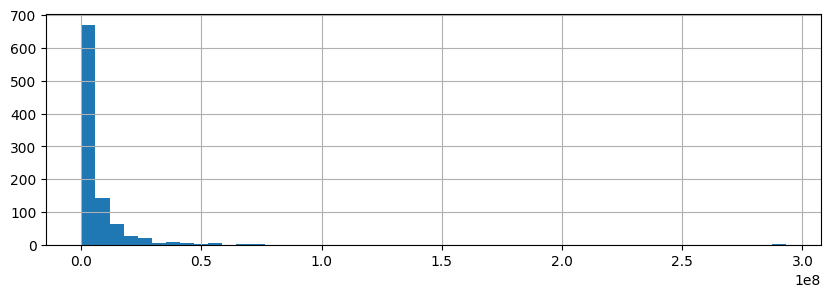

In [7]:
# Visualisaiton de la distribution des valeurs de la variable cible
plt.figure(figsize=(10,3))
Data_ml[Variable_cible].hist(bins=50)

In [8]:
# Visualisation des 10 plus fortes valeurs de la variable cible
Data_ml.sort_values(Variable_cible, ascending=False).head(10)

,PrimaryPropertyType,Neighborhood,NumberofFloors,PropertyGFAParking,ENERGYSTARScore,SiteEnergyUse(kBtu),StreetType,Electricity_prop,SteamUse_prop,GFAbyfloor,MoreThanOneBuilding,AgeBuilding,nUseType
78,Hospital,East,8,0,29.0,293090784.0,Avenue,0.575534,0.418215,144836.375000,True,16,2
404,Hospital,East,14,0,54.0,291614432.0,other,0.477874,0.462746,126140.714286,True,22,2
359,Other,Downtown,33,0,98.0,274682208.0,Avenue,0.999455,0.000000,13012.272727,False,35,2
63,Hospital,Northeast,10,0,10.0,253832464.0,Way,0.455581,0.000000,87900.000000,True,63,1
962,Hospital,East,8,0,74.0,163945984.0,Street,0.549330,0.450670,46808.250000,False,96,1
76,Hospital,Central,5,0,34.0,143423024.0,Avenue,0.409662,0.000000,119503.800000,True,26,2
667,Medical Office,East,3,0,60.0,102673696.0,Avenue,0.467523,0.000000,197327.000000,False,52,4
665,Hospital,Northwest,1,0,85.0,98960776.0,other,0.433143,0.000000,415632.000000,True,50,2
360,Administratif,Downtown,76,319400,86.0,92937640.0,Avenue,0.945278,0.000000,21484.473684,False,31,2
27,Logement,Downtown,34,146694,63.0,80469216.0,Avenue,0.565999,0.144138,24927.000000,False,34,3


**Stratégie de découpage précédemment testées**

In [9]:
#Data_ml['Target_cat'] =(Data_ml[Variable_cible]>10000000).astype('int')
#Data_ml =  is_outliers_iqr(Data_ml, Variable_cible)
#Data_ml = Data_ml[Data_ml[Variable_cible]< 50000000]

**Stratégie de découpage conservée pour cette variable**

In [10]:
# Construction d'une variable catétorielle pour classer les propriétés par quantile 
Data_ml['Target_cat'] =  pd.qcut(Data_ml[Variable_cible], 10, labels=[f'Quantile{i+1}' for i in range(10)])

# Définition d'un random state
rdm_stt = 0

# Séparation du jeu de données 
trainset, testset = train_test_split(Data_ml, test_size=0.2, random_state=rdm_stt, stratify=Data_ml['Target_cat'])

# Stockage du nom de la stratégie
Strategy = '2_cat_quantile10'

# Définition de la variable de stratification qui sera utilisée en validation croisée
Stratified_feature = trainset['Target_cat']

# Visualisation des valeurs de quantiles utilisées
Data_ml[Variable_cible].quantile([0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9])

0.1    7.360120e+05
0.2    1.089332e+06
0.3    1.470971e+06
0.4    1.993832e+06
0.5    2.804534e+06
0.6    4.116491e+06
0.7    6.363176e+06
0.8    9.462641e+06
0.9    1.746251e+07
Name: SiteEnergyUse(kBtu), dtype: float64

# Feature engineering

Lors de la phase création de nouvelles features, nous avons créée des variables représentant la proportion d'éléctricité utilisée, de vapeur d'eau utilisée et d'éléctricité utilisée. Ces données calculées à partir du relevé ne seront peut être pas disponibles pour les nouveaux bâtiments. Nous allons donc les utiliser pour calculer des valeurs moyenne par catégorie de propriété sur le jeu de données d'entrainement qui seront ensuite imputée sur le jeu de données test avec une méthode fit et transform afin de pouvoir intégrer cette étape dans une pipeline. 

In [11]:
class GroupMeanEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, var,  group1, group2=None,  new_col_names=None):
        
        # Initialisation du transformeur
        self.group1 = group1
        self.group2 = group2
        self.var = var
        self.new_col_names = new_col_names 

    def fit(self, X, y=None):
        
        # Calcul des moyennes par groupes d'une première variable catégorielle
        self.group1_means_ = {
            v: X.groupby(self.group1)[v].mean()
            for v in self.var
        }
        
        # Si deuxième variable renseignée -> Calcul des moyennes par groupes de cette variable
        if self.group2:
            self.group2_means_ = {
                v: X.groupby(self.group2)[v].mean()
                for v in self.var
            }
        else:
            self.group2_means_ = {}
        
        return self

    def transform(self, X):
        X = X.copy()
        for v, new_col in zip(self.var, self.new_col_names):
            
            # Extraction des moyennes pour le groupe 1
            group1_mean_series = self.group1_means_[v]
            X[new_col] = X[self.group1].map(group1_mean_series)
        
            # Remplissage du reste des observations si une deuxième variable a été renseignée
            if self.group2:
                group2_mean_series = self.group2_means_[v]
                group2_vals = X[self.group2].map(group2_mean_series)
                X[new_col] = X[new_col].fillna(group2_vals)
          
        return X
 
    def fit_transform(self, X, y=None):
        return self.fit(X, y).transform(X)


In [12]:
# Appel de la fonction et sauvegarde du transformeur personnalisé
group_encoder = GroupMeanEncoder(
    group1='PrimaryPropertyType',
    var = ['Electricity_prop', 'SteamUse_prop'],
    new_col_names=['Electricity_prop', 'SteamUse_prop']
)

# Fonctions d'évaluation de la performance du modèle

Les performances de chacun des modèles qui va être testé sera évaluée par validation croisée. Le jeu d'entrainement sera alors de nouveau subdivisé en k portions. A chaque itération, une portion serivra de jeu de validation, c'est à dire qu'elle ne sera pas vu par le modèle pendant l'entrainement, tandis que les k-1 portions restantes seront utilisées pour entrainer le modèle. Ce processus sera répété k fois, de manière à ce que chaque portion soit utilisée une fois comme jeu de validation. 

Afin d'évaluer la performance des différents modèles qui vont être testés, nous allons définir différentes fonctions.
- une fonction qui permettra de calculer les scores brutes et le score moyen obtenus après validation croisés, ainsi que les scores obtenus sur le jeu d'entrainement et sur le jeu de test. Cette fonction affichera également la distribution des scores obtenus après validation croisée
- une fonction permettant de visualiser les erreurs de prédiction par deux représentations graphiques
- une fonction montrant la capacité d'apprentissage des modèles en fonction de différents paramètre telles que la taille des jeux de données.

In [13]:
def evaluation_model(Coltransf, model, Xtrain, Ytrain, Xtest, Ytest, n_split, scoring, scoring_name, strat_col=Stratified_feature,
                     feat_extr='passthrough', feature_eng = group_encoder, target_transformer=FunctionTransformer(), 
                    affichage=True):
    
    """
    Entraîne et évalue un modèle de machine learning à l'aide d'une pipeline complète
    incluant ingénierie de variables, prétraitement, sélection de features et
    transformation de la variable cible, avec validation croisée.

    La fonction réalise :
    - une validation croisée (KFold ou StratifiedKFold),
    - un entraînement final du modèle sur l'ensemble d'entraînement,
    - une évaluation sur les jeux d'entraînement, de validation et de test,
    - un affichage optionnel des résultats et de la distribution des scores.
    
     Paramètres:
     - Coltransf (sklearn.compose.ColumnTransformer): Transformer appliqué aux colonnes (encodage, scaling, etc.).
     - model (estimator sklearn): Modèle de prédiction (régression) compatible scikit-learn.
     - Xtrain (pandas.DataFrame or array-like): Données d'entraînement (features).
     - Ytrain (pandas.Series or array-like): Variable cible associée aux données d'entraînement.
     - Xtest (pandas.DataFrame or array-like): Données de test.
     - Ytest (pandas.Series or array-like): Variable cible associée aux données de test.
     - n_split (int): Nombre de folds pour la validation croisée.
     - scoring (callable): Fonction de scoring utilisée pour évaluer les performances 
     (ex. `mean_absolute_error`, `r2_score`, etc.).
     - scoring_name (str): Nom du score, utilisé pour l'affichage et le reporting.
     - strat_col (array-like or None, default=Stratified_feature): Variable utilisée pour la stratification lors de la validation croisée.
        Si None, une validation croisée classique (KFold) est utilisée.
     - feat_extr (estimator or 'passthrough', default='passthrough'): Étape de sélection ou d'extraction de features.
     - feature_eng (estimator, default=group_encoder): Transformer appliqué pour l'ingénierie de variables avant le prétraitement.
     - target_transformer (transformer, default=FunctionTransformer()) : Transformation appliquée à la variable cible via
     `TransformedTargetRegressor`.
     - affichage (bool, default=True): 
        Si True, affiche les scores détaillés et un boxplot des scores de validation.
        Si False, retourne uniquement les résultats sous forme structurée.

    Sortie
     - pandas.DataFrame or list of dict
        - Si `affichage=True` : DataFrame contenant les scores d'entraînement,
          de validation (moyenne et écart-type) et de test.
        - Si `affichage=False` : liste de dictionnaires avec les mêmes informations.
    """   
    
    # Initialisation de la liste stockant les résultats
    res=[]
    
    # Choix du type de KFold
    if strat_col is not None:
        skf = StratifiedKFold(n_splits=n_split, shuffle=True, random_state=rdm_stt)
        cv = list(skf.split(Xtrain, strat_col))
        if affichage==True:
            print(f"✅ Stratification")
    else:
        kf = KFold(n_splits=n_split, shuffle=True, random_state=rdm_stt)
        cv = list(kf.split(Xtrain))
        if affichage==True:
            print("ℹ️ Aucune stratification demandée.")
            
            
    # Application d'une transformation sur la variable cible avec TransformedTargetRegressor
    model_t = TransformedTargetRegressor(regressor=model, transformer=target_transformer)
       
         
    # Pipeline
    pipeline = Pipeline([
        ('feature_engineering', feature_eng),
        ('Coltransf', Coltransf), 
       ('feature_selection', feat_extr),
        ('model', model_t) 
    ])
    
    # Adaptation de la fonction de scoring
    scorer = make_scorer(scoring)
     
    # Cross-validation
    val_score = cross_val_score(pipeline, Xtrain, Ytrain, cv=cv, scoring=scorer, error_score='raise', n_jobs=-1)

    # Entraînement du modèle sur le jeu d'entrainement
    pipeline.fit(Xtrain, Ytrain)
    
    # Prédiction des résultats sur le jeu d'entrainement et de test
    test_predictions = pipeline.predict(Xtest)
    train_predictions = pipeline.predict(Xtrain)
    
    # Calcul des scores 
    test_score = scoring(Ytest, test_predictions)
    train_score = scoring(Ytrain, train_predictions)

    # Reformatage des scores
    train_score =(train_score).round(2)
    val_score = (val_score).round(2)
    val_score_mean = (val_score).mean().round(2)
    val_score_std  = val_score.std().round(2)
    test_score = (test_score).round(2)
    
    if  scoring_name == 'MAE' or scoring_name=='RMSE':
        train_score = (train_score / 1000000).round(2)
        val_score = (val_score / 1000000).round(2)
        val_score_mean = (val_score_mean / 1000000).round(2)
        val_score_std = (val_score_std / 1000000).round(2)
        test_score = (test_score / 1000000).round(2)
    
    # Stockage des scores
    row = {
        "model": model.__class__.__name__, 
        "scoring": scoring_name,
        "train_score": train_score,
        "val_score mean": val_score.mean().round(2),
        "val_score std": val_score.std().round(2),
        "test_score": test_score
        }
    
    if affichage==True:
    # Afficher les résultats
        if  scoring_name == 'MAE' or scoring_name=='RMSE':
            print('Les scores ont été divisés par 1 000 000')
        
        print(scoring_name, "sur les validation sets:", val_score) 
        print(scoring_name, "moyen sur les validation sets:", val_score_mean)
        print(scoring_name, "ecart type sur les validation sets:", val_score_std)
        print(scoring_name, "sur le train set:", train_score)
        print(scoring_name, "sur le test set:", test_score)

        # Stockage des résultats dans une datadrame
        res = pd.DataFrame([row])
    
        # Nom du modèle
        model_name = model.__class__.__name__

        # Construction du graphique
        plt.figure(figsize=(12,2))
        sns.boxplot(x=val_score)
        plt.title(f'Disctribution des scores de {scoring_name} obtenus en validation croisée')
        plt.savefig(f'../Output/Modélisation/Score de validation croisée/Consommations/Distribution du score de {scoring_name} obtenu en validation croisée (émissions - {model_name}).png', format='png')

        
    else: 
        res.append(row)
    
    return res


In [14]:
def graph_erreur(Coltransf, model, Xtrain, Ytrain, Xtest, Ytest,
                 feat_extr='passthrough', feature_eng = group_encoder, target_transformer=FunctionTransformer(),
                Xlim=None, Ylim=None, Savefig=True, Optimisation=""):
    
    """
    Entraîne un modèle de régression sur les données d'entraînement et génère deux graphiques pour évaluer les erreurs de prédiction sur un jeu de test.

    Paramètres
     - Coltransf (transformer ou pipeline): Transformateur ou pipeline appliqué aux variables explicatives dans le pipeline global.
     - model (estimator scikit-learn): Modèle de régression à entraîner.
     - Xtrain (DataFrame ou array-like): Données d'entraînement (features).
     - Ytrain (Series ou array-like): Cibles d'entraînement.
     - Xtest (DataFrame ou array-like): Données de test (features).
     - Ytest (Series ou array-like): Cibles de test.
     - feat_extr (transformer ou 'passthrough', optionnel (par défaut 'passthrough')): Transformateur pour la sélection/extraction de caractéristiques dans le pipeline.
     - feature_eng (transformer, optionnel (par défaut group_encoder)): Transformateur pour l'ingénierie des variables dans le pipeline.
     - target_transformer (transformer, optionnel (par défaut FunctionTransformer())): Transformateur appliqué à la variable cible via TransformedTargetRegressor.
     - Xlim (float ou None, optionnel (par défaut None)): Limite maximale de l'axe x du nuage de points (valeurs réelles). Si None, pas de limite fixée.
     - Ylim (float ou None, optionnel (par défaut None)): Limite maximale de l'axe y du nuage de points (valeurs prédites). Si None, pas de limite fixée.
     - Savefig (bool, par défaut True): Indique si la figure doit être sauvegardée
     - Optimisation (str, par défaut ""): Indique dans le nom de sauvegarde si le modèle a été optimmisé
    """

    # Application d'une transformation sur la variable cible avec TransformedTargetRegressor
    model_t = TransformedTargetRegressor(regressor=model, transformer=target_transformer)

    # Pipeline
    pipeline = Pipeline([
        ('feature_engineering', feature_eng),
        ('Coltransf', Coltransf), 
       ('feature_selection', feat_extr),
        ('model', model_t) 
    ])
    
    # Entraînement du modèle sur le jeu d'entrainement
    pipeline.fit(Xtrain, Ytrain)

    # Prédiction des résultats sur le jeu de test
    test_predictions = pipeline.predict(Xtest)
    
    # Calcul des erreurs de prédiction
    err_hist = Ytest- test_predictions
    
    # Calcul de la moyenne des valeurs réelles
    mean_val = Ytest.mean()

    # Construction des graphiques
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))

    # Premier graphique (Histogramme avec les effectifs)
    counts, bins, patches = ax[0].hist(err_hist, bins=50)

    # Ajout des effectifs au-dessus de chaque barre
    for count, bin_left, bin_right in zip(counts, bins[:-1], bins[1:]):
        bin_center = (bin_left + bin_right) / 2
        ax[0].text(bin_center, count, str(int(count)), ha='center', va='bottom', fontsize=9)

    ax[0].set_xlabel("Erreur")
    ax[0].set_ylabel("Effectif")
    ax[0].set_title("Histogramme des erreurs")

    # Deuxième graphique (Nuage de points)
    ax[1].scatter(Ytest, test_predictions)
    ax[1].axvline(mean_val, color='blue', linestyle='--', label=f'Moyenne: {mean_val/100000000:.2f} .10⁸')
    ax[1].set_xlabel("Valeur réelles")
    ax[1].set_ylabel("Valeur prédites")
    ax[1].set_title(f"{Variable_cible} prédites en fonction de {Variable_cible} réelles")
    
    # Adatation des limites du deuxième graphique si spécifiés en arguments
    if Xlim is not None : 
        ax[1].set_xlim(0, Xlim)
    if Xlim is not None : 
        ax[1].set_ylim(0, Ylim)
   
    # Ajout de la droite y = x
    x_values = ax[1].get_xlim()  
    ax[1].plot(x_values, x_values, 'r--', label="y = x")  
    
    # Ajout d'une légende
    ax[1].legend()

    # Ajustement des graphiques
    plt.tight_layout()
    
    # Sauvegarde des graphiques
    model_name = model.__class__.__name__ 
    if Optimisation == "":
        plt.savefig(f'../Output/Modélisation/Analyse des erreurs/Consommations/Représentation des erreurs de modélisation (émissions - {model_name}).png', format='png')
    else:
        plt.savefig(f'../Output/Modélisation/Analyse des erreurs/Consommations/Représentation des erreurs de modélisation (émissions - {model_name} - optimisé).png', format='png')

    # Affichage des graphiques
    plt.show()

In [15]:
def graph_erreur_var(Coltransf, model, Xtrain, Ytrain, Xtest, Ytest, var, 
                 feat_extr='passthrough', feature_eng = group_encoder, target_transformer=FunctionTransformer()):

    """
    Entraîne un modèle de régression et affiche un nuage de points représentant les erreurs de prédiction en fonction d'une variable explicative spécifique.

    Paramètres
     - Coltransf (transformer ou pipeline): Transformateur ou pipeline appliqué aux variables explicatives dans le pipeline global.
     - model (estimator scikit-learn): Modèle de régression à entraîner.
     - Xtrain (DataFrame ou array-like): Données d'entraînement (features).
     - Ytrain (Series ou array-like): Cibles d'entraînement.
     - Xtest (DataFrame ou array-like): Données de test (features).
     - Ytest (Series ou array-like): Cibles de test.
     - var (str): Nom de la variable explicative selon laquelle représenter les erreurs.
     - feat_extr (transformer ou 'passthrough', optionnel (par défaut 'passthrough')): Transformateur pour la sélection/extraction de caractéristiques dans le pipeline.
     - feature_eng (transformer, optionnel (par défaut group_encoder)): Transformateur pour l'ingénierie des variables dans le pipeline.
     - target_transformer (transformer, optionnel (par défaut FunctionTransformer())): Transformateur appliqué à la variable cible via TransformedTargetRegressor.

    """
    
    # Application d'une transformation sur la variable cible avec TransformedTargetRegressor
    model_t = TransformedTargetRegressor(regressor=model, transformer=target_transformer)

    # Extraction du nom du modèle
    model_name = model.__class__.__name__ 

    # Pipeline
    pipeline = Pipeline([
        ('feature_engineering', feature_eng),
        ('Coltransf', Coltransf), 
       ('feature_selection', feat_extr),
        ('model', model_t) 
    ])
    
    # Entraînement du modèle sur le jeu d'entrainement
    pipeline.fit(Xtrain, Ytrain)

    # Prédicrion des résultats sur le jeu de test
    test_predictions = pipeline.predict(Xtest)

    # Calcul des erreurs de prédictions
    err_hist = Ytest- test_predictions

    # Construction du graphique
    plt.scatter(err_hist, Xtest[var])
    plt.title(f'Représentation des erreurs en fonction de la variable {var}')
    plt.tight_layout()
    plt.savefig(f'../Output/Modélisation/Analyse des erreurs/Consommations/Représentation des erreurs de modélisation en fonction de la variable {var} (Consommations - {model_name} - optimisé).png', format='png')
    plt.show()

In [16]:
def learning_curve_plot(Coltransf, model, X, Y, n_split, strat_col=Stratified_feature,
                        feat_extr='passthrough', feature_eng = group_encoder):

    """
    Trace la courbe d'apprentissage d'un modèle de machine learning en utilisant une validation croisée stratifiée ou non.

    Paramètres
     - Coltransf (transformer ou pipeline): Transformateur ou pipeline appliqué aux variables explicatives dans le pipeline global.
     - model (estimator scikit-learn): Modèle à entraîner.
     - X (DataFrame ou array-like): Variables explicatives.
     - Y (Series ou array-like): Variable cible.
     - n_split (int): Nombre de plis pour la validation croisée.
     - strat_col (array-like ou None, optionnel (par défaut Stratified_feature)): Variable de stratification pour la validation croisée stratifiée. Si None, stratification désactivée.
     - feat_extr (transformer ou 'passthrough', optionnel (par défaut 'passthrough')): Transformateur pour la sélection/extraction de caractéristiques dans le pipeline.
     - feature_eng (transformer, optionnel (par défaut group_encoder)): Transformateur pour l'ingénierie des variables dans le pipeline.
    """
    
    # Choix du type de KFold
    if strat_col is not None:
        strat_labels = strat_col
        skf = StratifiedKFold(n_splits=n_split, shuffle=True, random_state=rdm_stt)
        cv = list(skf.split(X, strat_labels))
        print(f"✅ Stratification")
    else:
        kf = KFold(n_splits=n_split, shuffle=True, random_state=rdm_stt)
        cv = list(kf.split(X))
        print("ℹ️ Aucune stratification demandée.")
                 
    # Pipeline
    pipeline = Pipeline([
        ('feature_engineering', feature_eng),
        ('Coltransf', Coltransf), 
       ('feature_selection', feat_extr),
        ('model', model) 
    ])
    
    # kearning curve
    N, train_score, val_score = learning_curve(pipeline, X, Y, 
                                           train_sizes=np.linspace(0.7,1,10), cv=cv, random_state=rdm_stt)
    
    # Construction du graphique
    plt.plot(N, train_score.mean(axis=1), label='train')
    plt.plot(N, val_score.mean(axis=1), label='validation')
    plt.title("Courbe d'apprentissage")
    plt.xlabel('train_sizes')
    plt.legend()

# Préprocessing

Différentes séquences de préprocessing vont être testées au fur et a mesure. Une première séquence sera la normalisation des features numériques ainsi que l'encodage des variables catégorielles. Les séquences de préprocessing seront ajoutées une a une dans la sections ci dessous au fur et a mesure des différents tests qui seront effectués. 

A noter que certains préprocessing peuvent différer selon le modèle. Par exemple, le paramétrage de l'encodage de type OneHotEncoder sera différent selon si le modèle est à base de regression linéaire ou à de relations non linéaires. En effet, pour une regression linéaire il sera préférable de retirer une des variables créées pour éviter d'introduire de la multicolinéarité dans le modèle tandis que pour les modèles non linéaires cela ne sera pas nécéssaire, ces derniers étant moins sensibles. On distinguera donc les préprocessing appliqués à ces différents types de modèles. 

In [17]:
# Préprocessing pour les méthodes linéaires
######################################################################################################""""""

# Coltransf_1_linéaire
Coltransf_1_lin = ColumnTransformer(
    transformers=[
        ('num1', RobustScaler(), num_cols) ,
        ('num2', RobustScaler(), log_cols) ,
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),       
    ])

# Coltransf_2_linéaire
Coltransf_2_lin = ColumnTransformer(
    transformers=[
       ('num1', Pipeline([
            ('log_transform', FunctionTransformer(func=np.log1p, inverse_func=np.expm1, validate=False)),
            ('scaler', RobustScaler())
        ]), log_cols),
        ('num2', RobustScaler(), num_cols),
        ('cat', TargetEncoder(random_state=rdm_stt), cat_cols),
    ])

# Préprocessing pour les méthodes non linéaires
######################################################################################################""""""

# Coltransf_1_non_linéaire
Coltransf_1_no_lin = ColumnTransformer(
    transformers=[
        ('num1', RobustScaler(), num_cols) ,
        ('num2', RobustScaler(), log_cols) ,
        ('cat', OneHotEncoder( handle_unknown='ignore'), cat_cols),       
    ])

# Coltransf_2_non_linéaire
Coltransf_2_no_lin = ColumnTransformer(
    transformers=[
       ('num1', Pipeline([
            ('log_transform', FunctionTransformer(func=np.log1p, inverse_func=np.expm1, validate=False)),
            ('scaler', RobustScaler())
        ]), log_cols),
        ('num2', RobustScaler(), num_cols),
        ('cat', TargetEncoder(random_state=rdm_stt), cat_cols),
    ])


# Premier modele : LinearRegression

Un premier modèle qui sera testé sera la régression linéaire. Les résultats vont être stockés dans un tableau de manière à pouvoir comparer les performances de chacun des modèles qui sera testés. 

## Entrainement et évaluation du modèle 

In [18]:
# Initiationlisation de la table résultats
resultat_step_1_var = ['model', 'scoring', 'train_score', 'val_score', 'test_score']
resultat_step_1 = pd.DataFrame(columns=resultat_step_1_var)

In [19]:
# Définition du premier modèle et du préprocessing
model = LinearRegression()
Coltransf= Coltransf_1_lin

✅ Stratification
R² sur les validation sets: [ 0.52  0.25  0.63 -1.26  0.69]
R² moyen sur les validation sets: 0.17
R² ecart type sur les validation sets: 0.73
R² sur le train set: 0.66
R² sur le test set: 0.35


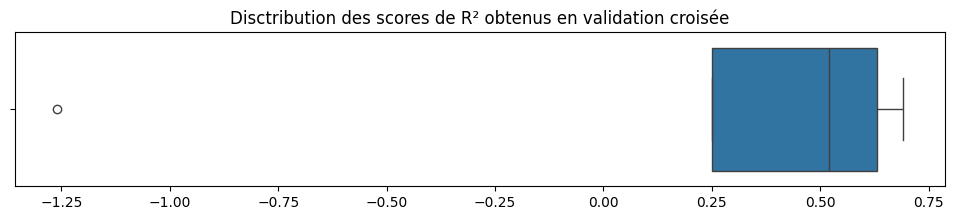

In [20]:
# Evaluation du R² du premier modèle
RES_1_a = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

- **val score** : les score obtenus sur la validation croisée sont très variables. On remarque qu'on a des folds où le modèle a bien su généraliser et d'autres pour lesquels le modèle n'a pas su bien généraliser voire a fait pire que la moyenne. Le modèle n'est pas stable selon les découpages. 
- **train score** : le score obtenu sur le jeu d'entrainement est correcte mais pas très élevé ce qui indique que le modèle n'a pas peut être pas suffisament réussi a tirer des relations entre les variables prédictives et la variable cible. Il y a deplus un grand écart entre le score moyen obtenu après validation et le score obtenu sur le jeu d'entrainement ce qui pourrait suggérer de l'overfit. Toutefois, si on exclu le 4ieme score, on retrouve un score moyen comparable au score d'entrainement. 
 
 Ces résultats nous amène à plusieurs pistes d'améliorations
 - tester l'introduction d'une forme de régularisation pour réduire l'overfit
 - tester des méthodes d'ensemble comme le bagging pour réduire la variance 
 - tester d'autres méthodologies de préprocessing
 - tester un modèle non linéaire
 - tester une autre stratégie de découpage

Afin de pouvoir comparer les différents modèles on va s'intéresser à d'autres scores comme la MAE qui mesure l'erreur absolue moyenne et la RMSE qui mesure l'erreur quadratique moyenne. On peut également analyser plus finement les erreurs en visualisant un histogramme des erreurs ou alors en visualisant les valeurs prédites en fonction des valeurs réelles.

✅ Stratification
Les scores ont été divisés par 1 000 000
MAE sur les validation sets: [6.41 5.41 6.97 6.02 7.17]
MAE moyen sur les validation sets: 6.39
MAE ecart type sur les validation sets: 0.64
MAE sur le train set: 5.5
MAE sur le test set: 5.07


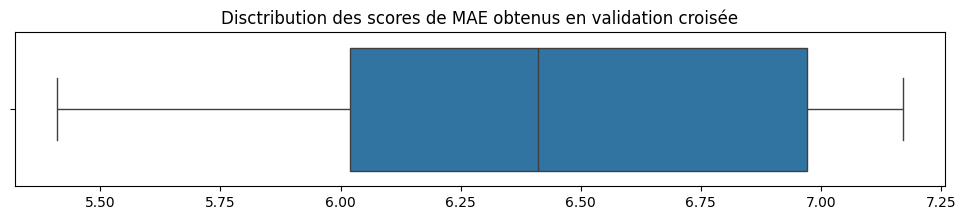

In [21]:
# Evaluation de la MAE du premier modèle
RES_1_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
Les scores ont été divisés par 1 000 000
RMSE sur les validation sets: [22.75  8.57 14.45 16.28 16.85]
RMSE moyen sur les validation sets: 15.78
RMSE ecart type sur les validation sets: 4.56
RMSE sur le train set: 13.79
RMSE sur le test set: 10.93


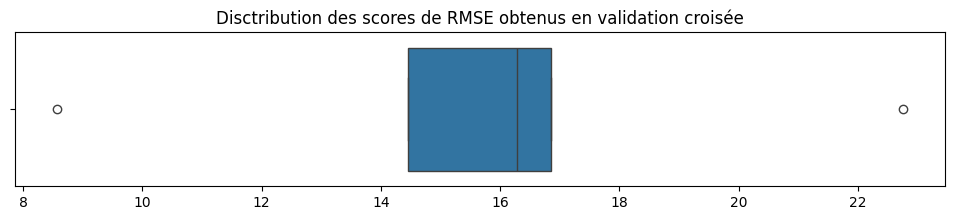

In [22]:
# Evaluation de la RMSE du premier modèle
RES_1_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

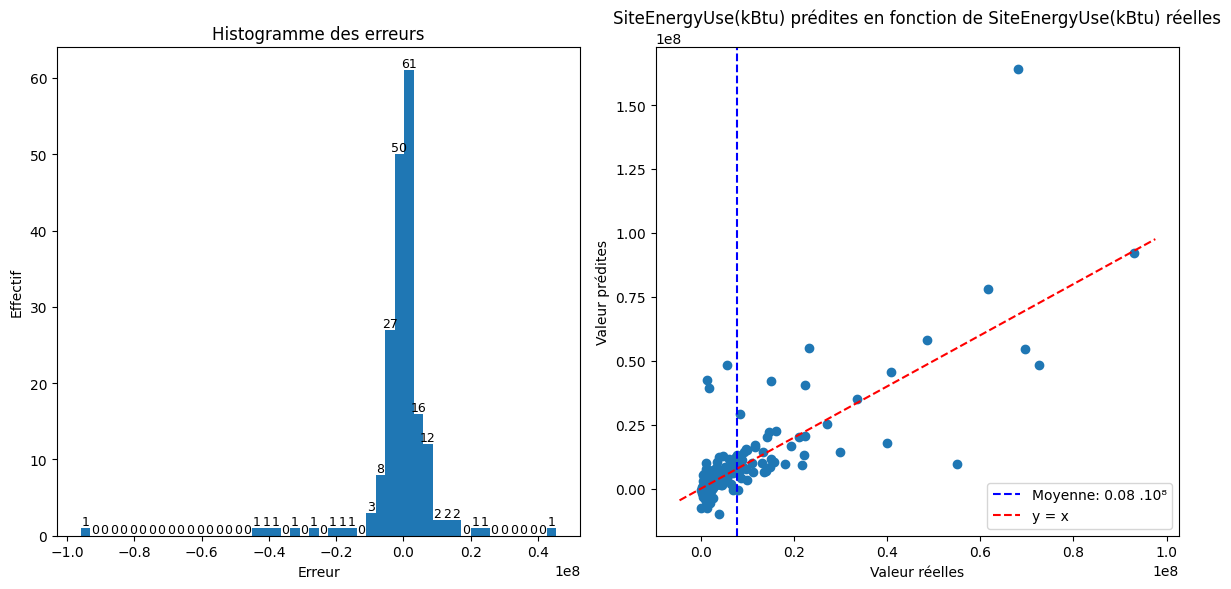

In [23]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

Les erreurs représentées dans l'histogramme correspondent à la différence entre la valeur réelle et la valeur prédite par le modèle. On remarque que le modèle fait beaucoup d'erreurs et à tendance à plutôt sur estimer les consommations. On remarque des erreurs très importantes. La plupart de ces grandes erreurs sont observées pour des propriétées dont la consommation réelle est supérieure à la consommation réelle moyenne, mais certaines sont aussi observée pour des propriétés dont la consommation énergétique réelle est plus basse.

✅ Stratification


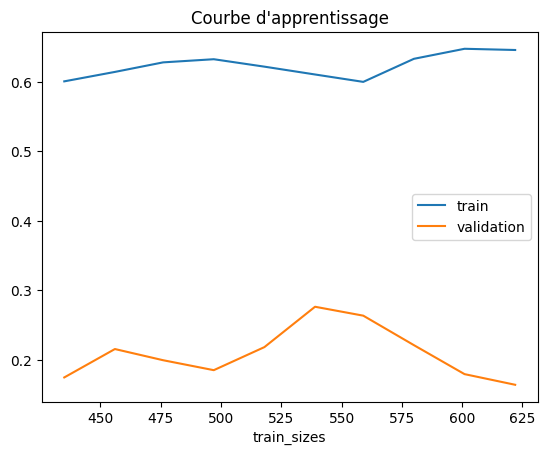

In [24]:
# Visulisation de la courbe d'apprentissage
learning_curve_plot(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 5)

La courbe d'apprentissage ne permet pas de penser qu'il faudrait augmenter les données pour améliorer les performances du modèle. 

In [25]:
resultat_step_1 = pd.concat([RES_1_a, RES_1_b, RES_1_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.66,0.17,0.73,0.35
0,LinearRegression,MAE,5.50,6.40,0.64,5.07
0,LinearRegression,RMSE,13.79,15.78,4.55,10.93


## Régularisation avec ElasticNet

Pour compenser un overfit d'un modèle linéaire on peut utiliser des techniques de régularisation telle que Ridge qui va pénaliser certains coéfficients de la regression linéaire en réduisant leur ampleur ou telle que Lasso qui va ajouter une pénalité qui elle va forcer certains coéfficients à 0 entrainant ainsi une séléction de variables. Le modèle ElasticNet est un modèle prenant en compte les deux pénalités. Ce modèle permet d'équilibrer les avantages des deux modèles Ridge et Lasso. Les paramètres à considérer sont:
- le coéfficient de régularisation globale alpha qui contrôle à quel point on pénalise les grands coéfficients du modèle. Quand il est égal a 0, cela signigie qu'uil n'y a pas de régularisation. 
- le l1 ratio correspondant au ratio entre la pénalité de Ridge et la pénalité ajouté par Lasso. Quand il est égal a 0 cela implique que seul la pénalité Ridge est appliquée.
- le nombre d'itération maximum de l'algorithme d'optimisation avant qu'il ne s'arrête.

In [26]:
# Définition du deuxième modèle et du préprocessing
Coltransf= Coltransf_1_lin
model = ElasticNet(
    alpha=0.1,       
    l1_ratio=0.5,    
    max_iter=10000,
    random_state=rdm_stt
)

✅ Stratification
R² sur les validation sets: [ 0.33 -0.19  0.57  0.03  0.5 ]
R² moyen sur les validation sets: 0.25
R² ecart type sur les validation sets: 0.29
R² sur le train set: 0.51
R² sur le test set: 0.6


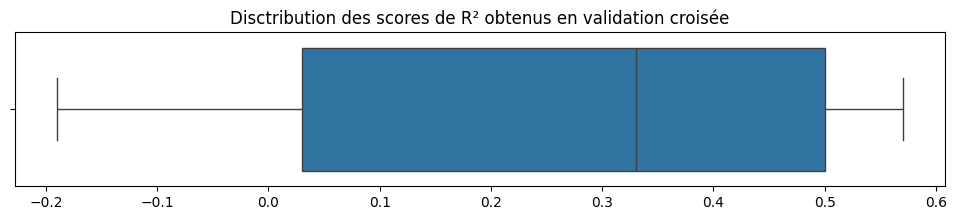

In [27]:
# Evaluation du R² du deuxième modèle
RES_2_a = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
Les scores ont été divisés par 1 000 000
MAE sur les validation sets: [7.47 5.86 6.5  5.78 7.24]
MAE moyen sur les validation sets: 6.57
MAE ecart type sur les validation sets: 0.69
MAE sur le train set: 6.22
MAE sur le test set: 5.03


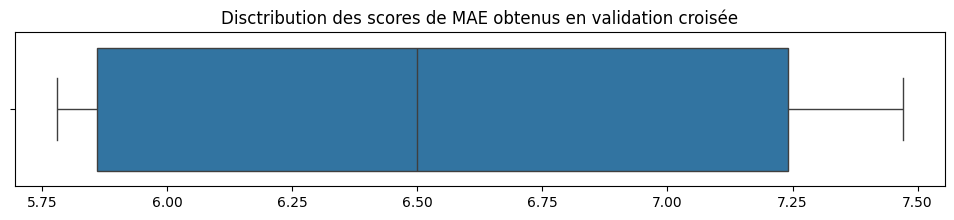

In [28]:
# Evaluation de la MAE du deuxième modèle
RES_2_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
Les scores ont été divisés par 1 000 000
RMSE sur les validation sets: [26.96 10.76 15.53 10.64 21.36]
RMSE moyen sur les validation sets: 17.05
RMSE ecart type sur les validation sets: 6.32
RMSE sur le train set: 16.44
RMSE sur le test set: 8.64


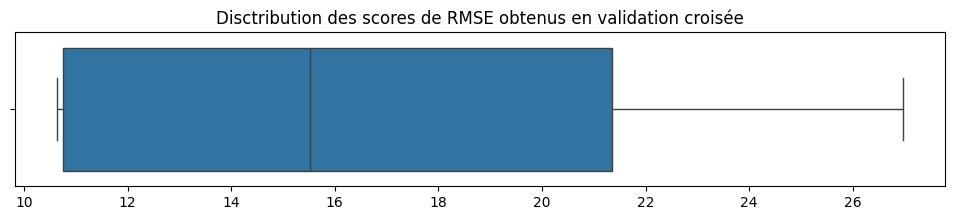

In [29]:
# Evaluation de la RMSE du deuxième modèle
RES_2_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

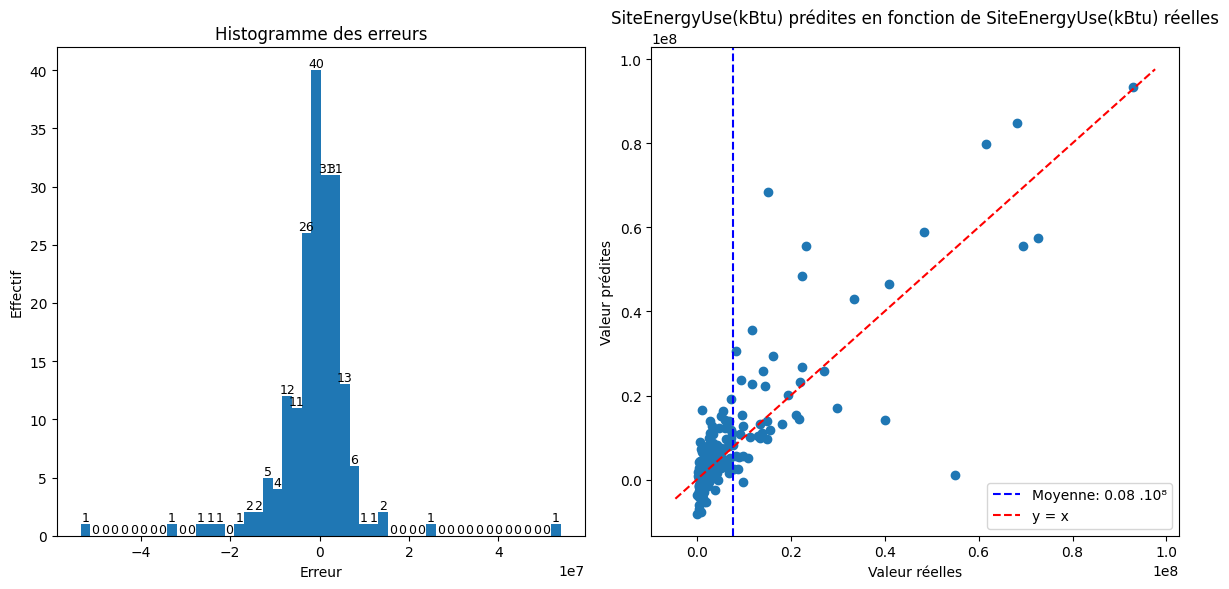

In [30]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [31]:
# Concaténation et visualisation de la table de résultats
resultat_step_1 = pd.concat([resultat_step_1, RES_2_a, RES_2_b, RES_2_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.66,0.17,0.73,0.35
0,LinearRegression,MAE,5.50,6.40,0.64,5.07
0,LinearRegression,RMSE,13.79,15.78,4.55,10.93
0,ElasticNet,R²,0.51,0.25,0.29,0.60
0,ElasticNet,MAE,6.22,6.57,0.69,5.03
0,ElasticNet,RMSE,16.44,17.05,6.32,8.64


L'ElasticNet a permis de réduire l'overfit de la régression linéaire et de réduire la variabilité des scores. On observe un meilleur score de R² en validation croisée mais celui ci reste encore bas. Les MAE et RMSE en validation croisée sont similaires à celles obtenues en régression linéaire non régularisée. Ce modèle comprend différents paramètres qu'il est possible d'optimiser. Il serait intéressant de voir si l'optimisation de certains de ces paramètres permettent une amélioration des performances de ce modèle. 

## Bagging

Le Bagging est une méthode d'ensemble qui consiste à entrainer plusieurs modèles en parrallèles chacun sur un échantillon différent des données d'entraînement, obtenu par bootstrap (échantillonnage aléatoire avec remise). Dans le cas d’un problème de régression, la prédiction finale est obtenue en faisant la moyenne des prédictions de tous les modèles. Pour ce type de modèle on peut configurer
- le nombre de modèles à entrainer en parallèles, 
- le nombre ou la proportion d'observations à utiliser pour chaque arbre
- le nombre ou la proportion de variables a considérer pour chaque arbre
- la méthode bootstrap

In [32]:
# Définition du troisième modèle et du préprocessing
Coltransf= Coltransf_1_lin
model = BaggingRegressor(
    estimator=LinearRegression(),
    n_estimators=100,          
    max_samples=0.8,         
    max_features=1.0,        
    bootstrap=True,          
    random_state=rdm_stt)

✅ Stratification
R² sur les validation sets: [ 0.52  0.23  0.71 -1.4   0.71]
R² moyen sur les validation sets: 0.15
R² ecart type sur les validation sets: 0.8
R² sur le train set: 0.66
R² sur le test set: 0.33


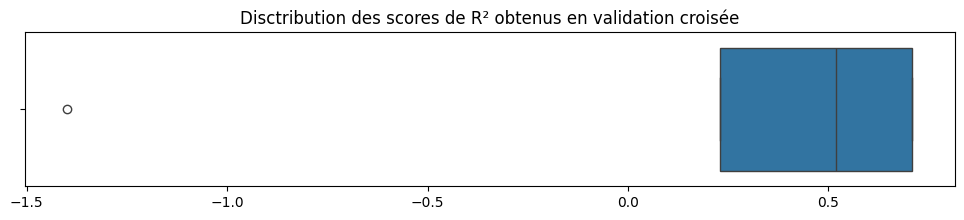

In [33]:
# Evaluation du R² du troisème modèle
RES_3_a = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
Les scores ont été divisés par 1 000 000
MAE sur les validation sets: [6.26 5.23 5.75 5.89 6.76]
MAE moyen sur les validation sets: 5.98
MAE ecart type sur les validation sets: 0.51
MAE sur le train set: 5.47
MAE sur le test set: 5.07


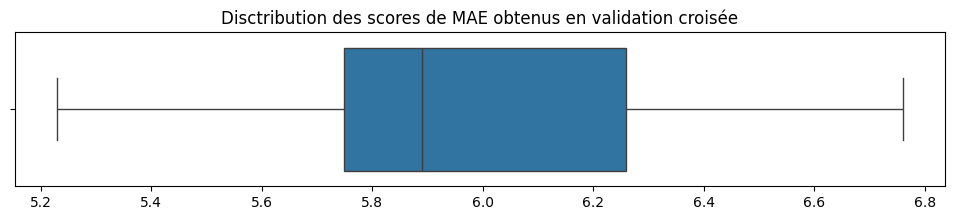

In [34]:
# Evaluation de la MAE du troisème modèle
RES_3_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
Les scores ont été divisés par 1 000 000
RMSE sur les validation sets: [22.88  8.65 12.75 16.77 16.35]
RMSE moyen sur les validation sets: 15.48
RMSE ecart type sur les validation sets: 4.72
RMSE sur le train set: 13.82
RMSE sur le test set: 11.12


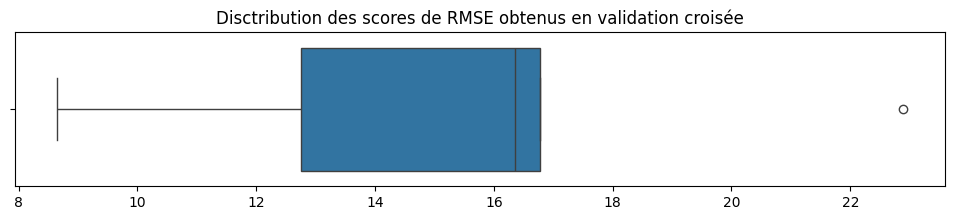

In [35]:
# Evaluation de la RMSE du troisème modèle
RES_3_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

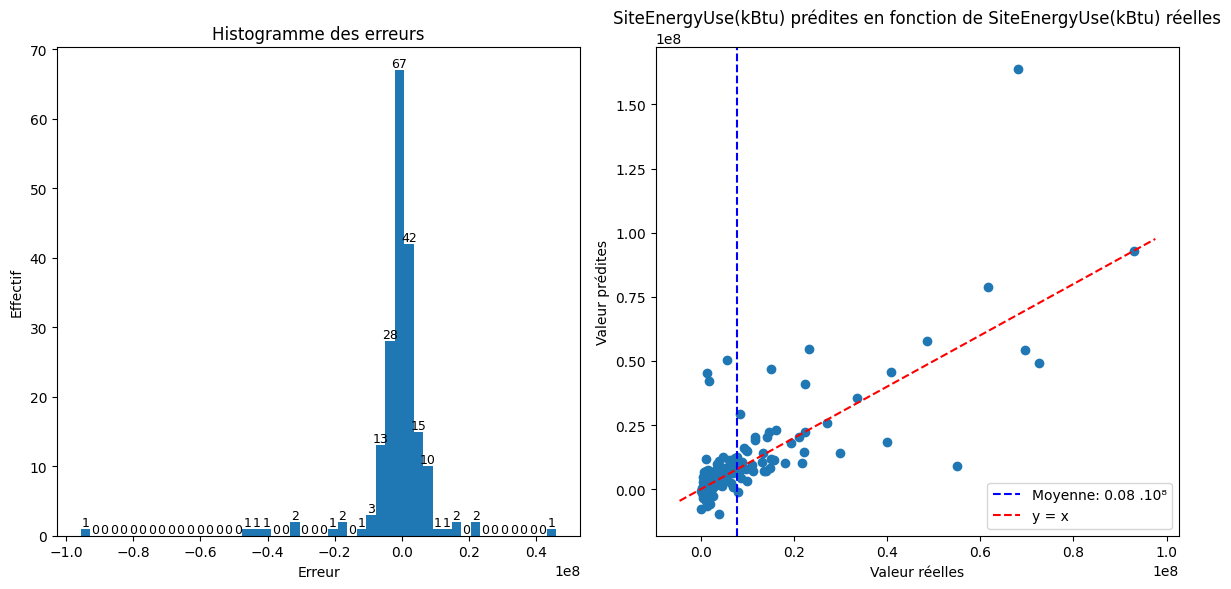

In [36]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [37]:
# Concaténation et visualisation de la table de résultats
resultat_step_1 = pd.concat([resultat_step_1, RES_3_a, RES_3_b, RES_3_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.66,0.17,0.73,0.35
0,LinearRegression,MAE,5.50,6.40,0.64,5.07
0,LinearRegression,RMSE,13.79,15.78,4.55,10.93
0,ElasticNet,R²,0.51,0.25,0.29,0.60
0,ElasticNet,MAE,6.22,6.57,0.69,5.03
0,ElasticNet,RMSE,16.44,17.05,6.32,8.64
0,BaggingRegressor,R²,0.66,0.15,0.80,0.33
0,BaggingRegressor,MAE,5.47,5.98,0.51,5.07
0,BaggingRegressor,RMSE,13.82,15.48,4.72,11.12


Après introduction d'une approche de bagging appliquée sur la régression linéaire, les scores et leur distributions après validation croisée sont similaires à ceux obtenus avec la régression linéaire simple. L'introduction d'une approche de bagging n'a pas permis d'améliorer les problèmes d'instabilité du modèle. Les mauvais scores moyens observés en validation croisés sont de nouveau dû à un découpage ayant obtenus des scores particulièrement mauvais. Ici, les paramètres n'ont pas été optimisés. Une optimisation des paramètres de ce modèle pourrait permettre d'améliorer un peu plus les performance du modèle. Cela pourra être fait dans une étape ultérieure.

# Autres modèles non linéaires

## SVR

Les modèles SVR correspondent à une alternatives de modèle de régression lorsque le problème n'est pas linéaire (il existe aussi une approche linéaire intégrée aux modèle SVR). Les modèles SVR cherchent à prédire en utilisant une fonction f(x) aussi plate que possible (c'est à dire qui va chercher a suivre la tendance générale des observations plutôt que de s'ajuster à chaque observation) et qui tolère une erreur qu'on appelle epsilon autour des valeurs de la variable à prédire tout en limitant les erreurs au dela de ce seuil. Les différents paramètres à configurer pour ce type de modèles sont:
- le kernel qui permet de choisir le noyau le plus adapté à la problématique (linéaire, polynomiale, sigmoïde..)
- le cout de pénalisation des erreurs C. Il s'agit de trouver un équilibre entre l'amplitude des erreurs et la platitude de la fonction. Plus C est grand plus le modèle va punir fortement les erreurs.
- la marge d'erreur dans laquelle les erreurs ne sont pas pénalisées
- le paramètre gamma qui contrôle l'influence d'un seul exemple. Un petit gamma aura tendance à lisser les prédiction, tandis qu'un grand gamma aura tendance a entrainer de l'overfit. 

Les modèles SVR sont très sensibles à l'échelle des variables et de la cible. Il faut donc ajouter ici une étape pour transformer la variable cible qui a une distribution asymétrique avec une présence de valeurs extrèmes. On peut effectuer dans un premier temps une transformation logarithmique. 

In [38]:
# Définition du quatrième modèle et du préprocessing
Coltransf= Coltransf_1_no_lin
model = TransformedTargetRegressor(regressor=SVR(kernel='rbf', C=100, epsilon=0.01, gamma='scale'),
                                   func=np.log1p,
                                   inverse_func=np.expm1)

✅ Stratification
R² sur les validation sets: [0.61 0.24 0.01 0.72 0.45]
R² moyen sur les validation sets: 0.41
R² ecart type sur les validation sets: 0.26
R² sur le train set: 0.91
R² sur le test set: 0.51


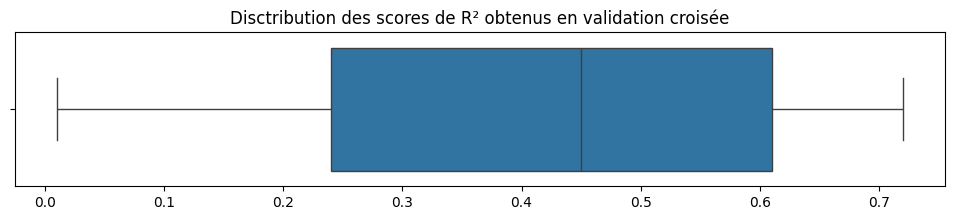

In [39]:
# Evaluation du R² du quatrième modèle
RES_4_a = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
Les scores ont été divisés par 1 000 000
MAE sur les validation sets: [4.65 4.33 6.48 2.63 5.35]
MAE moyen sur les validation sets: 4.69
MAE ecart type sur les validation sets: 1.27
MAE sur le train set: 1.38
MAE sur le test set: 3.28


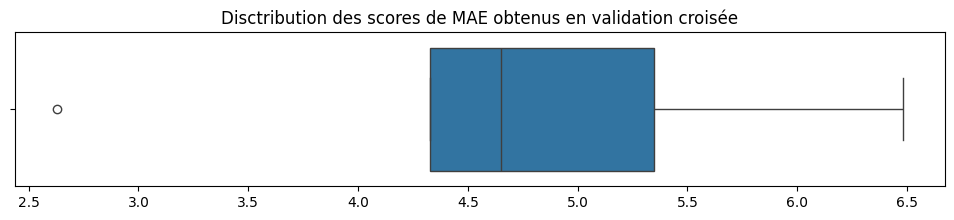

In [40]:
# Evaluation de la MAE du quatrième modèle et du préprocessing
RES_4_b = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
Les scores ont été divisés par 1 000 000
RMSE sur les validation sets: [20.53  8.63 23.51  5.73 22.28]
RMSE moyen sur les validation sets: 16.14
RMSE ecart type sur les validation sets: 7.43
RMSE sur le train set: 7.09
RMSE sur le test set: 9.54


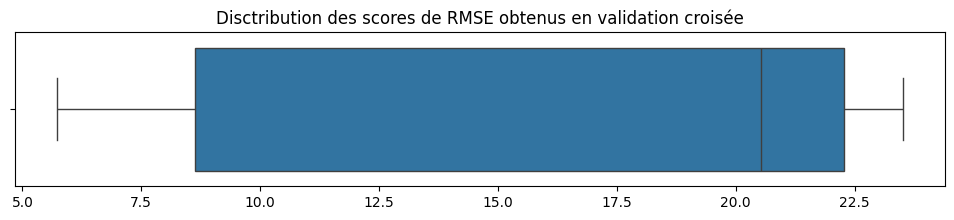

In [41]:
# Evaluation de la RMSE du quatrième modèle
RES_4_c = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

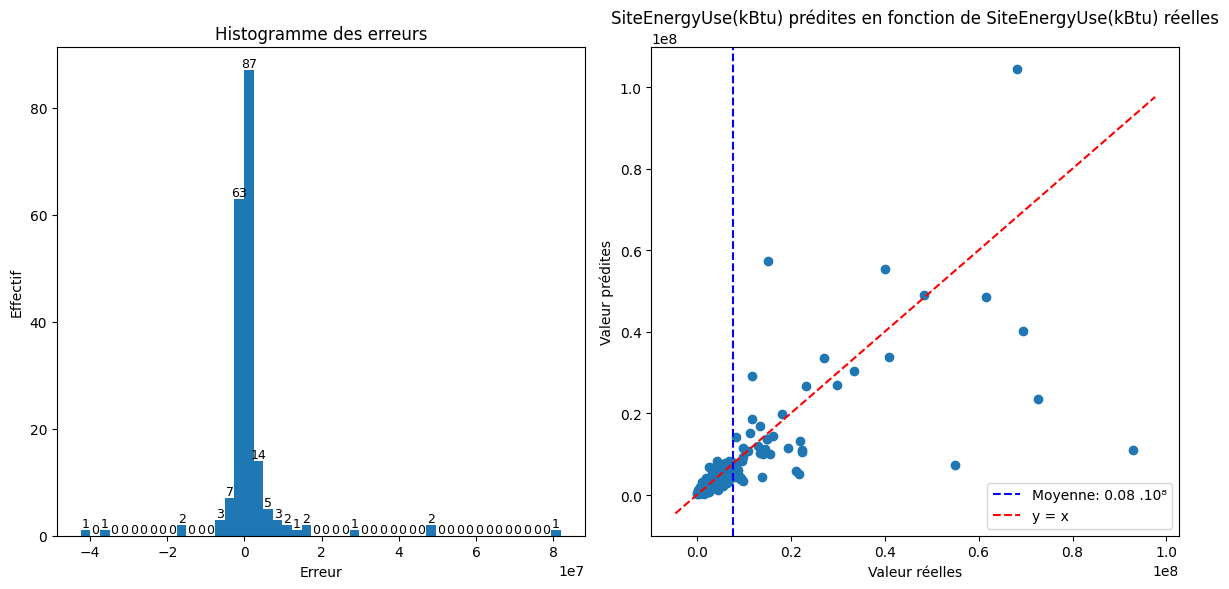

In [42]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [43]:
# Concaténation et visualisation de la table de résultats
resultat_step_1 = pd.concat([resultat_step_1, RES_4_a, RES_4_b, RES_4_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.66,0.17,0.73,0.35
0,LinearRegression,MAE,5.50,6.40,0.64,5.07
0,LinearRegression,RMSE,13.79,15.78,4.55,10.93
0,ElasticNet,R²,0.51,0.25,0.29,0.60
0,ElasticNet,MAE,6.22,6.57,0.69,5.03
0,ElasticNet,RMSE,16.44,17.05,6.32,8.64
0,BaggingRegressor,R²,0.66,0.15,0.80,0.33
0,BaggingRegressor,MAE,5.47,5.98,0.51,5.07
0,BaggingRegressor,RMSE,13.82,15.48,4.72,11.12
0,TransformedTargetRegressor,R²,0.91,0.41,0.26,0.51


On observe une amélioration des score moyens après validation croisée du R² et de la MAE avec le modèle SVR mais bien qu'elle ait été réduite, il reste encore une grande variabilité entre les différents folds. La RMSE moyenne est quant à elle moins bonne que celle obtenue avec la régression linéaire simple et la régression linéaire avec bagging. Les scores obtenus sont en accord avec les représentations graphiques qui montrent l'existence d'erreurs plus élevées des prédictions. On note également un fort overfit du modèle comme l'indique l'écart entre les scores obtenus sur les données d'entrainement et les scores obtenus sur les données de validation croisées. Une optimisation des paramètres pourrait également améliorer les performances du modèle.

## Abres de décision 

Les arbres de décisions correspondent à des modèles non linéaires. Ils vont établir leur prédiction en différentes étapes correspondant à une série de décisions binaires. A chacune des étapes qu'on appelle noeud, le modèle va considérer une variable et une valeur seuil pour diviser le jeu de données en deux sous groupes, le but étant à chaque étape de minimiser l'erreur de prédiction. A la suite des différentes étapes, la prédiction correspond à la moyenne des valeurs de la variable à prédire dans chacun des sous groupes obtenus. Les sous-groupes obtenus à la dernière étape correspondent aux feuilles de l'arbre. Pour ce modèle, les principaux paramètres à configurer sont:
- La profondeur de l'arbre (nombre d'étape où des décisions seront prises par le modèle)
- Le nombre ou la prorportion d'observations requis pour diviser un noeud
- Le nombre ou la proportion d'observations minimum dans une feuille
- Le nombre maximum de features testés à chaque étape de division

### Modèle de base

In [44]:
# Définition du cinquième modèle et du préprocessing
model = DecisionTreeRegressor(max_depth=10, 
                              min_samples_leaf=5,
                              max_features='sqrt', 
                              min_samples_split=20,
                             random_state=rdm_stt)
Coltransf= Coltransf_1_no_lin

✅ Stratification
R² sur les validation sets: [ 0.36  0.2   0.59 -2.56  0.41]
R² moyen sur les validation sets: -0.2
R² ecart type sur les validation sets: 1.19
R² sur le train set: 0.56
R² sur le test set: 0.24


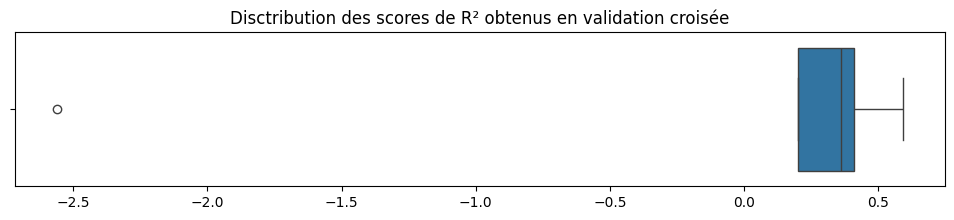

In [45]:
# Evaluation du R² du cinquième modèle
RES_5_a = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
Les scores ont été divisés par 1 000 000
MAE sur les validation sets: [7.63 5.3  5.62 7.   7.83]
MAE moyen sur les validation sets: 6.68
MAE ecart type sur les validation sets: 1.03
MAE sur le train set: 5.07
MAE sur le test set: 5.84


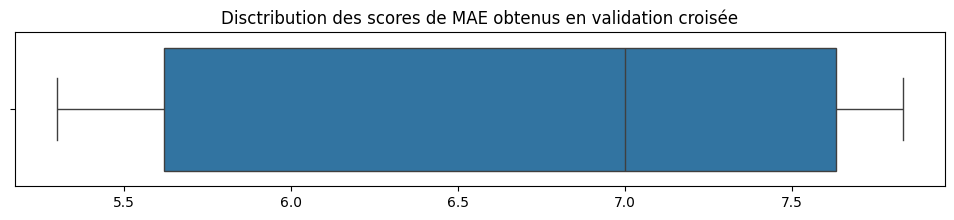

In [46]:
# Evaluation de la RMSE du cinquième modèle
RES_5_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
Les scores ont été divisés par 1 000 000
RMSE sur les validation sets: [26.44  8.85 15.05 20.42 23.12]
RMSE moyen sur les validation sets: 18.78
RMSE ecart type sur les validation sets: 6.21
RMSE sur le train set: 15.71
RMSE sur le test set: 11.81


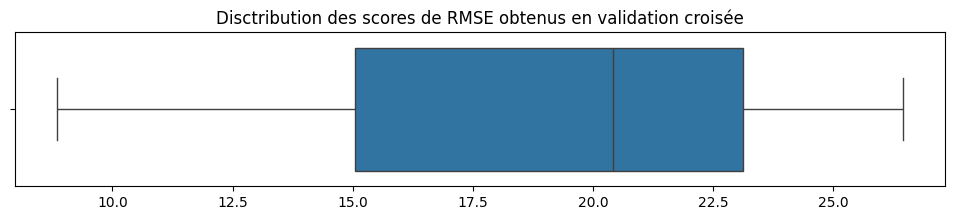

In [47]:
# Evaluation de la MAE du cinquième modèle
RES_5_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

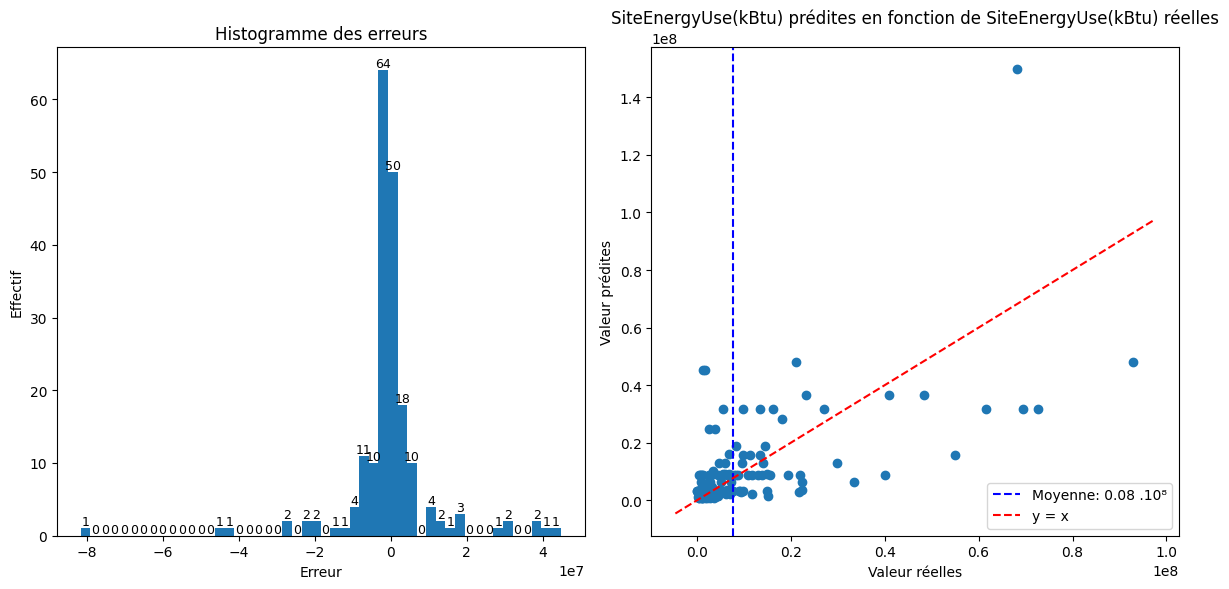

In [48]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [49]:
# Concaténation et visualisation de la table de résultats
resultat_step_1 = pd.concat([resultat_step_1, RES_5_a, RES_5_b, RES_5_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.66,0.17,0.73,0.35
0,LinearRegression,MAE,5.50,6.40,0.64,5.07
0,LinearRegression,RMSE,13.79,15.78,4.55,10.93
0,ElasticNet,R²,0.51,0.25,0.29,0.60
0,ElasticNet,MAE,6.22,6.57,0.69,5.03
0,ElasticNet,RMSE,16.44,17.05,6.32,8.64
0,BaggingRegressor,R²,0.66,0.15,0.80,0.33
0,BaggingRegressor,MAE,5.47,5.98,0.51,5.07
0,BaggingRegressor,RMSE,13.82,15.48,4.72,11.12
0,TransformedTargetRegressor,R²,0.91,0.41,0.26,0.51


Ici on observe les moins bons score observés pour chacune des métriques avec toujours une grande variabilité des scores en validation croisée. Encore une fois, les paramètres pourraient être optimisés pour améliorer les performances de ce modèles. On peut aussi envisager des méthodes d'ensemble en appliquant par exemple du boosting pour améliorer l'apprentissage du modèle ou du bagging pour réduire la variance.

### Bagging

Les arbres de décisions ont une méthode de bagging qui leur est spécifique et qu'on appelle RandomForest. Le principe est le même que celui détaillé pour le bagging regressor. Plusieurs arbres sont entrainés en parallèles et la prédiciton finale correspondara à la moyenne de celles obtenues pour chaque arbre. 

In [50]:
# Définition du sixième modèle et du préprocessing
Coltransf= Coltransf_1_no_lin
model = RandomForestRegressor(
    n_estimators=100,        
    max_depth=4,             
    min_samples_leaf=5,      
    max_features='sqrt',     
    random_state=rdm_stt)

✅ Stratification
R² sur les validation sets: [0.28 0.47 0.43 0.43 0.24]
R² moyen sur les validation sets: 0.37
R² ecart type sur les validation sets: 0.09
R² sur le train set: 0.54
R² sur le test set: 0.49


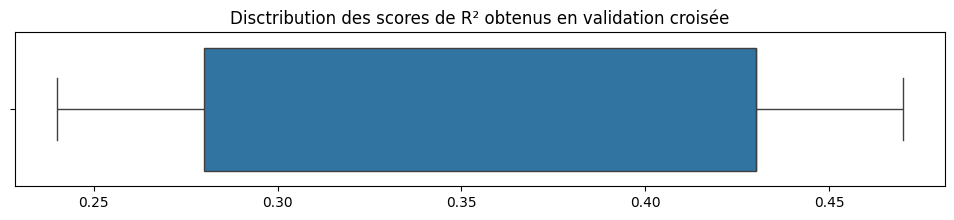

In [51]:
# Evaluation du R² du sixième modèle
RES_6_a = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
Les scores ont été divisés par 1 000 000
MAE sur les validation sets: [7.61 4.81 6.54 5.31 7.87]
MAE moyen sur les validation sets: 6.43
MAE ecart type sur les validation sets: 1.21
MAE sur le train set: 5.86
MAE sur le test set: 5.31


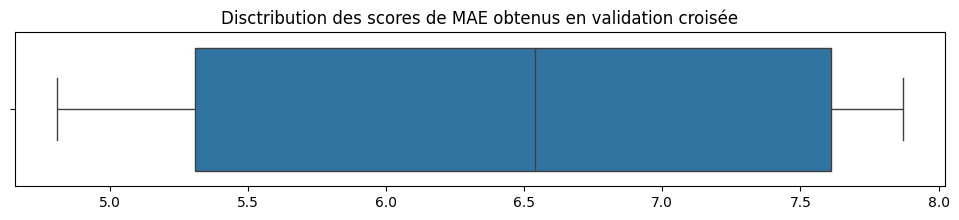

In [52]:
# Evaluation de la MAE du sixième modèle
RES_6_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
Les scores ont été divisés par 1 000 000
RMSE sur les validation sets: [27.92  7.16 17.89  8.15 26.23]
RMSE moyen sur les validation sets: 17.47
RMSE ecart type sur les validation sets: 8.71
RMSE sur le train set: 16.02
RMSE sur le test set: 9.72


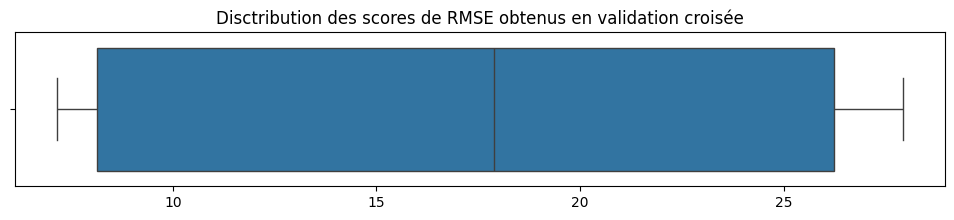

In [53]:
# Evaluation de la RMSE du sixième modèle
RES_6_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

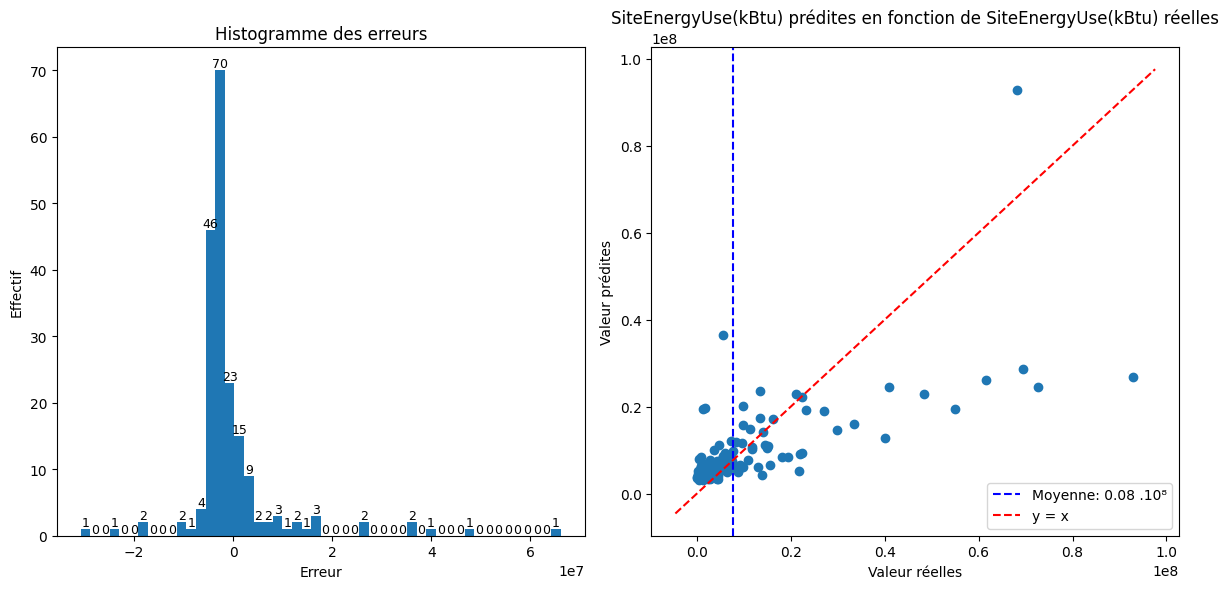

In [54]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [55]:
# Concaténation et visualisation de la table de résultats
resultat_step_1 = pd.concat([resultat_step_1, RES_6_a, RES_6_b, RES_6_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.66,0.17,0.73,0.35
0,LinearRegression,MAE,5.50,6.40,0.64,5.07
0,LinearRegression,RMSE,13.79,15.78,4.55,10.93
0,ElasticNet,R²,0.51,0.25,0.29,0.60
0,ElasticNet,MAE,6.22,6.57,0.69,5.03
0,ElasticNet,RMSE,16.44,17.05,6.32,8.64
0,BaggingRegressor,R²,0.66,0.15,0.80,0.33
0,BaggingRegressor,MAE,5.47,5.98,0.51,5.07
0,BaggingRegressor,RMSE,13.82,15.48,4.72,11.12
0,TransformedTargetRegressor,R²,0.91,0.41,0.26,0.51


Après l'utilisation d'une méthode de bagging avec RandomForest on observe une meilleure généralisation sur des données non vues comme l'indiquent les scores obtenus en validation croisée par rapport aux autres modèles (Regression linéaire simple, ElasticNet, Regression linéaire avec bagging, arbres de décision) et une réduction importante de la variance du R². La RMSE indique que le modèle à fait moins de grosse erreur que le modèle d'arbre de décisions sur les données non vues par le momdèle mais il en a fait plus que les modèles de regressions linéaires et que le modèle SVR. Bien qu'une amélioration des scores en validation croisée ait été observée par rapport à certains modèles, ces derniers restent encore assez faibles. Là encore on peut jouer sur différents paramètres pour améliorer les performances de ce modèle. 

### Boosting : XGboost

Le boosting consiste à construire des modèles de façon séquentielle où chaque modèle essaie de corriger les erreurs du précédent modèle en pondérant les prédictions des modèles successifs pour converger vers la meilleure prédiction globale. Il existe plusieurs algorithme de boosting. XGBoost est basé sur la méthode de descente de gradient pour corriger les erreurs. Ici les principaux paramètres à configurer sont:
- le booster pour choisir le type de modèle à entrainer
- le nombre de modèle à entrainer séquentiellement
- le taux d'apprentissage
- la profondeur de l'abre lorsque booster est fixé a gbtree
- le nombre de poids minimum d'observation dans une feuille (-> le nombre minimum d'observation dans une feuille quand aucun poids n'est fixé)
- le nombre ou la proportion d'observations à inclure dans chaque modèle
- le nombre ou la proportion de feature à inclure dans chaque modèle
- le gain minimum requis pour faire un split

In [56]:
# Définition du septième modèle et du préprocessing
Coltransf= Coltransf_1_no_lin
model =xgb = XGBRegressor(
    booster='gbtree',
    n_estimators=100,        
    learning_rate=0.1,      
    max_depth=3,              
    subsample=0.8,           
    random_state=rdm_stt)

✅ Stratification
R² sur les validation sets: [ 0.63  0.69  0.78 -0.68  0.5 ]
R² moyen sur les validation sets: 0.38
R² ecart type sur les validation sets: 0.54
R² sur le train set: 0.98
R² sur le test set: 0.37


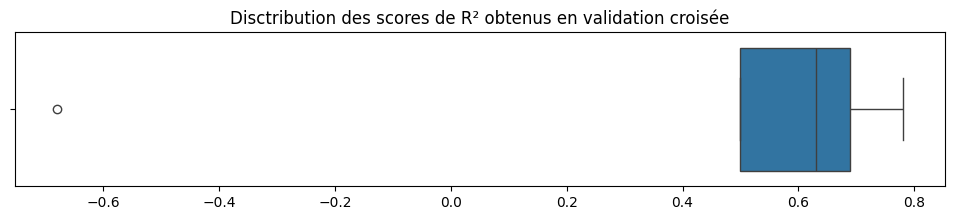

In [57]:
# Evaluation du R² du septième modèle
RES_7_a = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
Les scores ont été divisés par 1 000 000
MAE sur les validation sets: [4.79 2.66 4.04 5.12 5.61]
MAE moyen sur les validation sets: 4.44
MAE ecart type sur les validation sets: 1.03
MAE sur le train set: 1.83
MAE sur le test set: 3.82


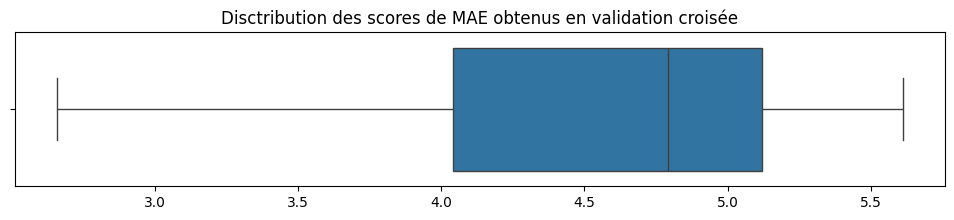

In [58]:
# Evaluation de la MAE du septième modèle
RES_7_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
Les scores ont été divisés par 1 000 000
RMSE sur les validation sets: [20.04  5.52 11.05 14.01 21.41]
RMSE moyen sur les validation sets: 14.41
RMSE ecart type sur les validation sets: 5.85
RMSE sur le train set: 3.06
RMSE sur le test set: 10.8


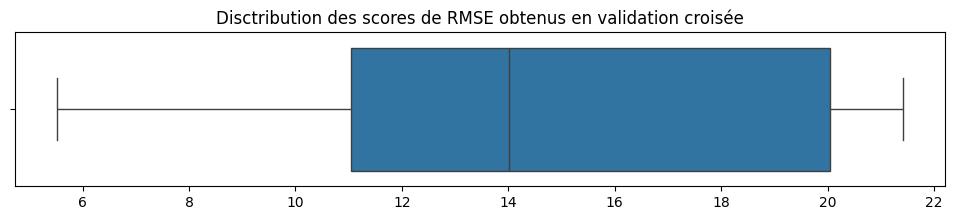

In [59]:
# Evaluation de la RMSE du septième modèle
RES_7_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

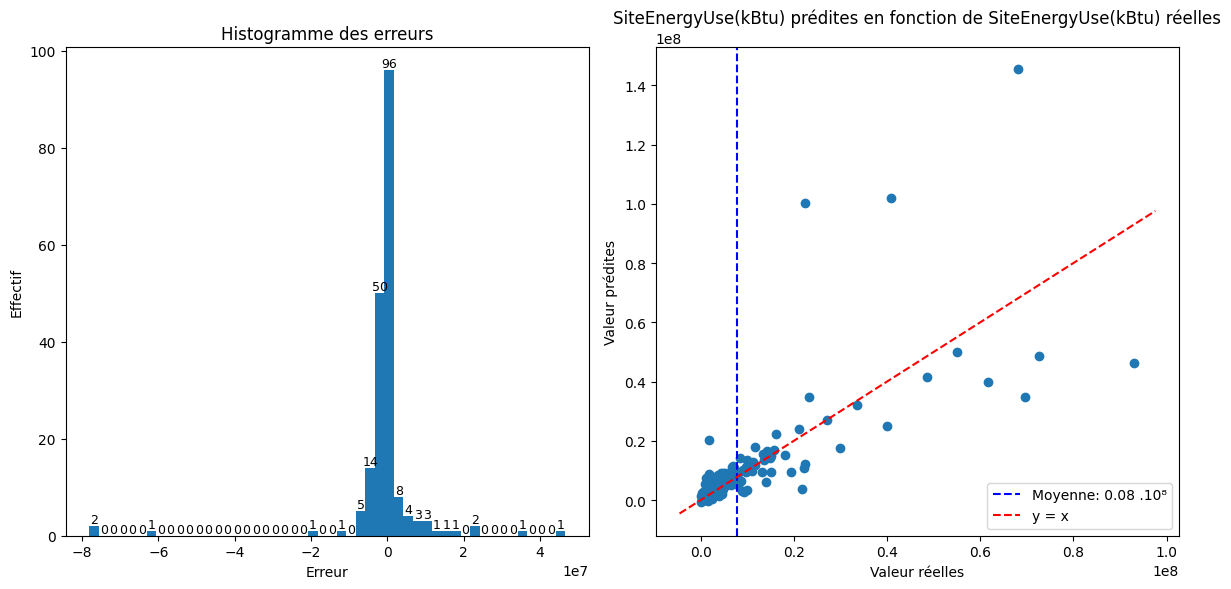

In [60]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [61]:
# Concaténation et visualisation de la table de résultats
resultat_step_1 = pd.concat([resultat_step_1, RES_7_a, RES_7_b, RES_7_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.66,0.17,0.73,0.35
0,LinearRegression,MAE,5.50,6.40,0.64,5.07
0,LinearRegression,RMSE,13.79,15.78,4.55,10.93
0,ElasticNet,R²,0.51,0.25,0.29,0.60
0,ElasticNet,MAE,6.22,6.57,0.69,5.03
0,ElasticNet,RMSE,16.44,17.05,6.32,8.64
0,BaggingRegressor,R²,0.66,0.15,0.80,0.33
0,BaggingRegressor,MAE,5.47,5.98,0.51,5.07
0,BaggingRegressor,RMSE,13.82,15.48,4.72,11.12
0,TransformedTargetRegressor,R²,0.91,0.41,0.26,0.51


Après l'utilisation d'une méthode de boosting avec XBGregressor on observe un overfit du modèle et à nouveau une grande variance des scores de R². Les scores obtenus sont comparables à ceux obtenus pour le RandomForest et le SVR. Là encore on peut jouer sur différents paramètres pour réduire l'overfit et la variance tout en augmentant les performances en validation croisée. 

# Modification du préprocessing

Lors de la phase d'exploration, il avait été observé que certaines variables, en particulier celles correspondant à des surfaces, avaient une distribution asymétrique avec une forte quantité de propriété avec des surface faibles, et peu de proriété dans les valeurs plus élevées. Il pourrait être inéterssant de transformer ces variables avec une fonction logarithmique pour obtenir une distribution plus normal.

Une autre modification du préprocessing concerne l'encodage des variables catégorielles qui peuvent etre encodées avec un encodeur de type OneHot comme jusqu'à maintenant mais également avec un encodeur de type Target, qui consiste à remplacer les valeurs de chaque catégorie par un estimateur calculé grâce à la target. 

Enfin, la méthode de normalisation des données peut également impacter la performance d'un modèle. Au lieu de faire une normalisation avec un Robust Scaler, on pourrait opter pour un MinMax scaler ou un Standard scaler.

Dans le test qui va suivre, la normalisation n'a pas été modifiée, mais une étape de transformation par une fonction logarithmique des variables liées à la surface et un encodage avec un encodeur de type Target ont été appliqués. 

In [62]:
# Définition du modèle et du préprocessing
Coltransf= Coltransf_2_no_lin
model = TransformedTargetRegressor(regressor=SVR(kernel='rbf', C=100, epsilon=0.01, gamma='scale'),
                                   func=np.log1p,
                                   inverse_func=np.expm1)

✅ Stratification
R² sur les validation sets: [ 0.06  0.   -0.   -0.08 -0.68]
R² moyen sur les validation sets: -0.14
R² ecart type sur les validation sets: 0.27
R² sur le train set: 0.22
R² sur le test set: -0.04


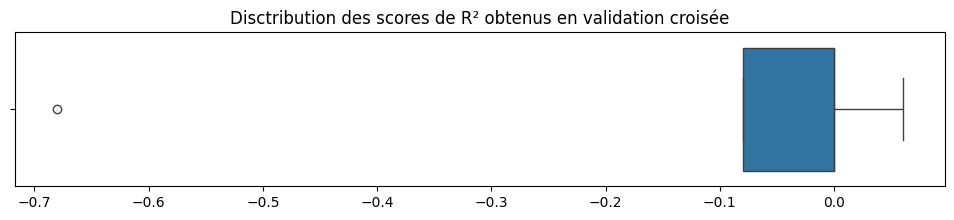

In [63]:
# Evaluation du R² du huitième modèle
RES_8_a = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
Les scores ont été divisés par 1 000 000
MAE sur les validation sets: [ 8.3   4.78  7.37  5.69 10.42]
MAE moyen sur les validation sets: 7.31
MAE ecart type sur les validation sets: 1.98
MAE sur le train set: 6.37
MAE sur le test set: 6.02


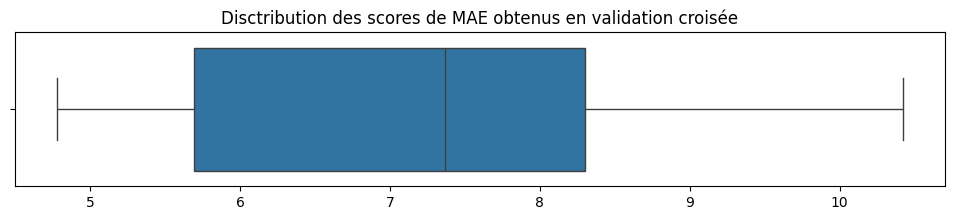

In [64]:
# Evaluation de la MAE du huitième modèle
RES_8_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
Les scores ont été divisés par 1 000 000
RMSE sur les validation sets: [31.97  9.86 23.65 11.24 39.07]
RMSE moyen sur les validation sets: 23.16
RMSE ecart type sur les validation sets: 11.4
RMSE sur le train set: 20.77
RMSE sur le test set: 13.84


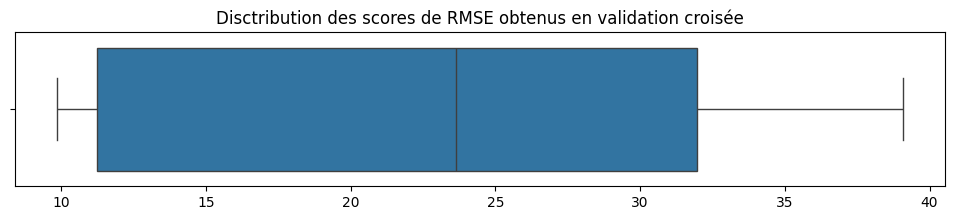

In [65]:
# Evaluation de la RMSE du huitième modèle
RES_8_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

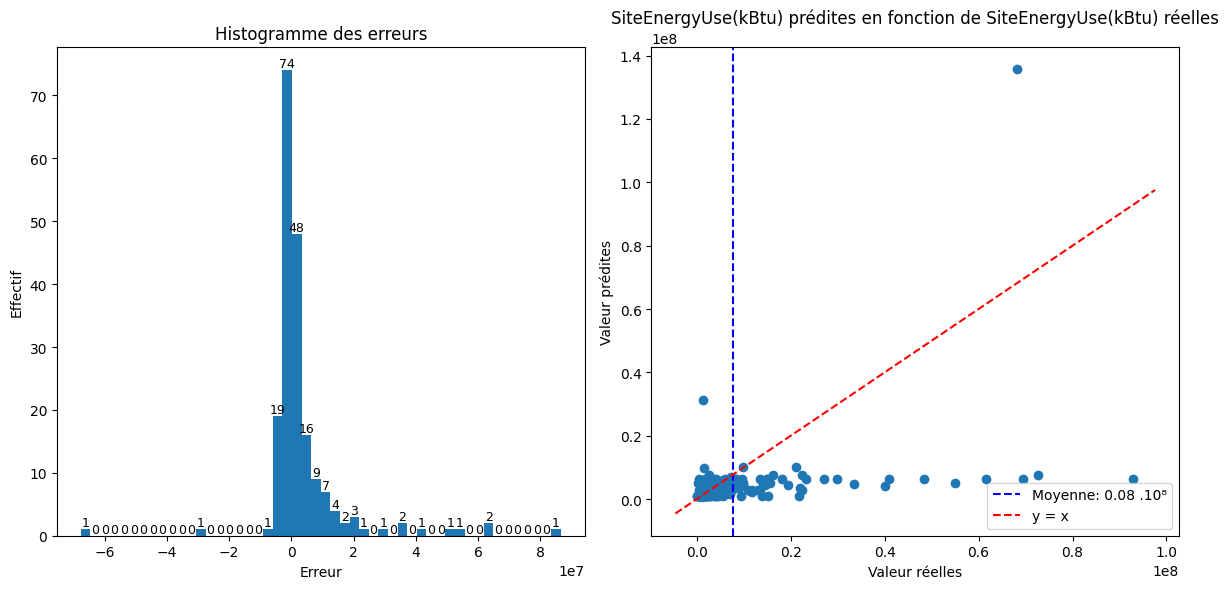

In [66]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [67]:
# Concaténation et visualisation de la table de résultats
resultat_step_2 = pd.concat([RES_3_a, RES_3_b, RES_3_c, RES_8_a, RES_8_b, RES_8_c])
resultat_step_2

,model,scoring,train_score,val_score mean,val_score std,test_score
0,BaggingRegressor,R²,0.66,0.15,0.80,0.33
0,BaggingRegressor,MAE,5.47,5.98,0.51,5.07
0,BaggingRegressor,RMSE,13.82,15.48,4.72,11.12
0,TransformedTargetRegressor,R²,0.22,-0.14,0.27,-0.04
0,TransformedTargetRegressor,MAE,6.37,7.31,1.98,6.02
0,TransformedTargetRegressor,RMSE,20.77,23.16,11.40,13.84


Dans le cas du SVR, la modificiation du preprocessing entraine une baisse importante des performances du modèle pour les trois métriques d'évaluation. La variabilité est également encore importante. Les scores sont moins bons que ce soit sur les données d'entrainement ou après validation croisée. 
Ici on a modifié deux étapes à la fois, et il serait intéressant de tester les différentes combinaisons possibles de preprocessing. Cela peut être fait dans une étape de gridSearch qui sera appliquée dans la section suivante. 

# Optimisations

Afin d'optimiser et d'évaluer les résulats de cette optimisation, une fonction va être utilisée de façon à garantir une méthodologie identique pour chaque modèle. Une représentation graphique sera également générée par une fonction de manière à pouvoir comparer plus facilement les résulats obtenus sur les différents modèles. Enfin une dernière fonction sera mise en place pour évaluer le temps d'execution de chacun des modèle optimisés. 

Dans une première étape les modèles vont être optimisés sur un intervalle de valeur large pour pouvoir selectionner le ou les mmodèles les plus prometteurs qui seront optmisés de façon plus fine autour des meilleurs paramètres identifiés lors de la première phase.

## Fonction d'optimisation

In [68]:
def optimiser_models(models, Xtrain, Ytrain, Xtest, Ytest, n_split, scoring_list,
                     strat_col=Stratified_feature,  feat_extr='passthrough',
                     feature_eng=group_encoder):
        
    """
    Effectue une optimisation hyperparamétrique (GridSearchCV) pour plusieurs modèles en utilisant une validation croisée stratifiée ou non,
    et retourne un résumé des performances ainsi que les meilleurs estimateurs et résultats des recherches.

    Paramètres
     - models (dict): Dictionnaire contenant les modèles à optimiser et leurs grilles de paramètres associées.
     Chaque entrée doit être sous la forme : {'nom_du_modele': (estimator, param_grid)},
     où param_grid inclut notamment une clé 'Coltransfs_named' (mapping noms -> transformateurs) et 'Coltransfs' (liste des transformateurs).
     - Xtrain (DataFrame ou array-like): Données d'entraînement (features).
     - Ytrain (Series ou array-like): Cibles d'entraînement.
     - Xtest (DataFrame ou array-like): Données de test (features).
     - Ytest (Series ou array-like): Cibles de test.
    - n_split (int): Nombre de plis pour la validation croisée.
     - scoring_list (list de fonctions): Liste des fonctions de scoring à appliquer (ex: [r2_score, mean_absolute_error]).
     - strat_col (array-like ou None, optionnel (par défaut Stratified_feature)): Variable de stratification pour la validation croisée stratifiée. Si None, stratification désactivée.
     - feat_extr (transformer ou 'passthrough', optionnel (par défaut 'passthrough')): Transformateur pour la sélection/extraction de caractéristiques dans le pipeline.
     - feature_eng (transformer, optionnel (par défaut group_encoder)): Transformateur pour l'ingénierie des variables dans le pipeline.

    Sortie
     - resultats (pandas.DataFrame): DataFrame récapitulant les scores d'entraînement, validation (moyenne et écart-type) et test pour chaque modèle et métrique.
     - best_estimators (dict): Dictionnaire des meilleurs estimateurs obtenus pour chaque modèle après optimisation.
     - gs_results (dict): Dictionnaire des objets GridSearchCV complets pour chaque modèle (permettant un accès détaillé aux résultats).

    """
    
    # Initialisation des variables de sortie scotkant les résultats
    resultats = []
    best_estimators = {}
    gs_results = {}

    # Choix du type de KFold
    if strat_col is not None:
        strat_labels = strat_col
        skf = StratifiedKFold(n_splits=n_split, shuffle=True, random_state=rdm_stt)
        cv = list(skf.split(Xtrain, strat_labels))
        print(f"✅ Stratification")
    else:
        kf = KFold(n_splits=n_split, shuffle=True, random_state=rdm_stt)
        cv = list(kf.split(Xtrain))
        print("ℹ️ Aucune stratification demandée.")
        
    # Boucle sur les différents modèles    
    for model_name, (model, param_grid) in models.items():
        print(f"Optimisation du modèle : {model_name}")
                 
        # Extraction des noms associés aux différentes transformations
        coltransfs_named = param_grid['Coltransfs_named']
        reverse_named = {v: k for k, v in coltransfs_named.items()}
        
        # Définition d'une transformation par défaut pour initialiser la pipeline
        default_coltransf =  param_grid['Coltransfs'][0]
        
        # Application d'une transformation sur la variable cible avec TransformedTargetRegressor
        model = TransformedTargetRegressor(regressor=model)
        
        # Pipeline
        pipeline = Pipeline([
            ('feature_engineering', feature_eng),
            ('Coltransfs', default_coltransf),
            ('feature_selection', feat_extr),
            ('model', model)
        ])
        
        # Construction d'une nouvelle grille de paramètre sans l'item correspondant aux noms
        param_grid_2 = param_grid.copy()
        param_grid_2.pop('Coltransfs_named', None)

        # Déinition d'un dictionnaire indiquant si le score doit être élevé (True) ou bas (False) lors de l'optimisation
        score_directions = {
            'r2_score': True,
            'mean_absolute_error': False,
            'root_mean_squared_error': False,
            }
        
        # Adapation de la fonction de scoring
        scoring_dict = {score.__name__: make_scorer(score, greater_is_better=score_directions.get(score.__name__, False)) for score in scoring_list}

        # Gridsearch
        gs = GridSearchCV(
            pipeline,
            param_grid=param_grid_2,
            scoring=scoring_dict,
            refit=scoring_list[0].__name__,
            cv=cv,
            n_jobs=-1)

        # Entrainement de la GridSearch
        gs.fit(Xtrain, Ytrain)
        
        # Stockage de la GridSearch
        gs_results[model_name] = gs
        
        # Stockage des meilleurs estimateurs obtenus après la GridSearch
        best_model = gs.best_estimator_
        best_estimators[model_name] = gs.best_estimator_
    
        # Extraction de la meilleure combinaison de transformation
        best_params = gs.best_params_
        best_coltransf_obj = best_params['Coltransfs']
        best_coltransf_name = reverse_named.get(best_coltransf_obj, str(best_coltransf_obj))

        # Extraction des meilleurs paramètres 
        model_params = {
            key.replace('model__', ''): val
            for key, val in best_params.items()
            if key.startswith('model__')}
        
        # Prédiction des valeurs du jeu de données test avec le meilleur modèle
        Ytrain_pred = best_model.predict(Xtrain)
        Ytest_pred = best_model.predict(Xtest)
        
        # Extraction des différents scores associés au meilleur modèle
        for score_func in scoring_list:
            score_name = score_func.__name__
            
            # Calcul des scores
            score_train = score_func(Ytrain, Ytrain_pred)
            score_val_mean = gs.cv_results_[f'mean_test_{score_name}'][gs.best_index_]
            score_val_std = gs.cv_results_[f'std_test_{score_name}'][gs.best_index_]
            score_test = score_func(Ytest, Ytest_pred)

            # Formatage des scores
            score_train =(score_train).round(2)
            score_val_mean = (score_val_mean).round(2)
            score_val_std =(score_val_std).round(2)
            score_test = (score_test).round(2)
            
            if  score_name == 'mean_absolute_error' or score_name=='root_mean_squared_error':
                score_train = (score_train / 1000000).round(2)
                score_val_mean = (score_val_mean / 1000000).round(2)
                score_val_std = (score_val_std / 1000000).round(2)
                score_test = (score_test / 1000000).round(2)
                score_val_mean = - score_val_mean
            
            # Création d'une ligne avec tosu les résultats
            row = {
                'model': model_name,
                'scoring': score_name,
                'train_score': score_train,
                'val_score mean': score_val_mean,
                'val_score std': score_val_std,
                'test_score': score_test,
                'best_coltransf': best_coltransf_name,
                'best_model_params': model_params
            }
            
            # Ajout des résultats dans la liste
            resultats.append(row)

    return pd.DataFrame(resultats), best_estimators, gs_results


In [69]:
def opt_graph(df_res, option=None):

    """
    Génère un graphique comparatif des performances de modèles à partir d'un DataFrame de résultats, 
    avec possibilité de grouper par une option spécifique (ex : hyperparamètre).

    Paramètres
     - df_res (pandas.DataFrame):  DataFrame contenant les résultats des modèles, avec au minimum les colonnes :
        - 'model' : nom du modèle
        - 'scoring' : nom de la métrique de performance (ex: r2_score, mean_absolute_error, etc.)
        - 'val_score mean' : moyenne du score en validation croisée
        - 'val_score std' : écart-type du score en validation croisée
        - 'train_score' : score sur l'ensemble d'entraînement
         - Optionnellement une colonne correspondant à `option` pour grouper les résultats.
     - option (str ou None, optionnel (par défaut None)): Nom d'une colonne de `df_res` selon laquelle grouper les résultats (ex : nom d'un hyperparamètre).
     Si None, le graphique compare uniquement les modèles.

    Sortie
     - plotnine.ggplot: Objet graphique plotnine représentant un barplot des scores de modèles, avec barres d'erreur sur la validation croisée.
     Les scores affichés sont la moyenne en validation croisée et le score sur le train set, séparés par facettes.
    """
    
    # Simplification des noms de scores
    anciennes_valeurs = ['r2_score', 'mean_absolute_error', 'root_mean_squared_error']
    nouvelles_valeurs = ['R²', 'MAE', 'RMSE']
    df_res['scoring'] = df_res['scoring'].replace(dict(zip(anciennes_valeurs, nouvelles_valeurs)))

    # Choix des variables d'identification pour l'étape de melt suivante
    id_vars = ['model', 'scoring']
    if option is not None:
        id_vars.append(option)

    # Reformatage de la dataframe
    resultats_pivot = pd.melt(
        df_res,
        id_vars=id_vars,
        value_vars=['val_score mean', 'train_score'],
        var_name='Score',
        value_name='Value'
    )

    # Extraction de la colonne de std
    std_pivot = df_res[['model', 'scoring', 'val_score std'] + ([option] if option else [])].copy()
    std_pivot = std_pivot.rename(columns={'val_score std': 'Std'})
    std_pivot['Score'] = 'val_score mean'


    # Jointure
    resultats_plot = resultats_pivot.merge(std_pivot, how='left', on=id_vars + ['Score']) 
    if option is not None:
        resultats_plot[option] = resultats_plot[option].astype(str)
        categories_ordonnees = sorted(resultats_plot['k'].unique(), key=lambda x: int(x))
        resultats_plot['k'] = pd.Categorical(resultats_plot['k'], categories=categories_ordonnees, ordered=True)
        resultats_plot = resultats_plot[resultats_plot['Score']=='val_score mean']

    # Dictionnaire de couleurs
    color_mapping = {
        'DummyRegressor': 'grey',
        'LinearRegression': 'bisque',
        'BaggingLinearRegression': 'wheat',
        'ElasticNet' : 'darkgoldenrod',
        'SVR': 'lightcoral',
        'RandomForest': 'lightgreen',
        'DecisionTree': 'darkgreen',
        'XGBregressor': 'green',
        'XGBRegressor': 'green'

    }

    # Définition de l'axe des x
    x_axis = option if option is not None else 'model'

    # Construction du graphique
    p = (ggplot(resultats_plot, aes(x=x_axis, y='Value', fill='model')) +
         geom_bar(stat='identity', position='dodge') +
         geom_errorbar(
             aes(ymin='Value - Std', ymax='Value + Std'),
             width=0.2,
             data=resultats_plot[resultats_plot['Score'] == 'val_score mean']
         ) +
         scale_fill_manual(values=color_mapping) +
         facet_grid('scoring ~ Score', scales='free_y') +
         theme(
             figure_size=(10, 7),
             axis_text_x=element_text(angle=45, ha='right', size=13),
             axis_text_y=element_text(size=13),
             axis_title_x=element_text(size=14, weight='bold'),
             axis_title_y=element_text(size=14, weight='bold'),
             strip_text_x=element_text(size=14, weight='bold'),
             strip_text_y=element_text(size=14, weight='bold'),
             legend_position='none'
         ) +
         labs(x='Modèle' if option is None else option, y='Score')
    )

    # Sauvegarde du graphique
    if option is not None:
        p.save(f"../Output/Modélisation/Optimisation/Consommations/Comparaison_models.png", dpi=300)
    else:
        p.save(f"../Output/Modélisation/Optimisation/Consommations/Comparaison_n_features.png", dpi=300)
        
    return p


In [70]:
def execution_time_calculation(best_estimators, Xtrain, Ytrain, Xtest):
    """
    Mesure et visualise les temps d'entraînement et de prédiction des modèles fournis.

    Pour chaque modèle dans le dictionnaire `best_estimators`, la fonction :
    - entraîne le modèle sur les données d'entraînement,
    - mesure le temps d'entraînement,
    - réalise une prédiction sur les données de test,
    - mesure le temps de prédiction,
    - calcule le temps total (entraînement + prédiction),
    - stocke ces mesures dans un DataFrame.

    Ensuite, elle génère un graphique comparatif des temps pour chaque modèle, 
    avec des barres distinctes pour le temps d'entraînement, le temps de prédiction et le temps total.

    Paramètres
     - best_estimators (dict): Dictionnaire contenant les modèles à évaluer sous la forme {nom_du_modèle : instance_du_modèle}.
     - Xtrain (array-like ou DataFrame): Données d'entrée pour l'entraînement.
     - Ytrain (array-like ou Series): Cible associée aux données d'entraînement.
     - Xtest (array-like ou DataFrame): Données d'entrée pour la prédiction.

    Sortie
     - df_resultats_temps (pandas.DataFrame): DataFrame contenant les temps mesurés pour chaque modèle et chaque type de temps (entraînement, prédiction, total).
        Colonnes : ['model', 'Time', 'Value']
     - p (plotnine.ggplot): Objet graphique représentant un barplot comparant les temps d'entraînement, de prédiction et total par modèle.
    """
    
    # Initialisation de la liste de résultats
    resultats_temps = []

    for model_name, model in best_estimators.items():

        # Mesure du temps d'entraînement
        start_train = time.time()
        model.fit(Xtrain, Ytrain)
        end_train = time.time()
        training_time = end_train - start_train

        # Mesure du temps de prédiction
        start_pred = time.time()
        _ = model.predict(Xtest)
        end_pred = time.time()
        prediction_time = end_pred - start_pred

        # Temps total
        total_time = training_time + prediction_time

        # Ajout des résultats
        resultats_temps.extend([
            {'model': model_name, 'Time': 'training_time', 'Value': training_time},
            {'model': model_name, 'Time': 'prediction_time', 'Value': prediction_time},
            {'model': model_name, 'Time': 'total_time', 'Value': total_time},
        ])
        
    df_resultats_temps = pd.DataFrame(resultats_temps)
    
    # Choix des variables d'identification
    id_vars = ['model']


    # Dictionnaire de couleurs
    color_mapping = {
        'DummyRegressor': 'grey',
        'LinearRegression': 'bisque',
        'BaggingLinearRegression': 'wheat',
        'ElasticNet' : 'darkgoldenrod',
        'SVR': 'lightcoral',
        'RandomForest': 'lightgreen',
        'DecisionTree': 'darkgreen',
        'XGBregressor': 'green',
        'XGBRegressor': 'green'

    }
    
    # Définition de l'axe des x
    x_axis = 'model'

    # Construction du graphique
    p = (ggplot(df_resultats_temps, aes(x=x_axis, y='Value', fill='model')) +
         geom_bar(stat='identity', position='dodge') +
         scale_fill_manual(values=color_mapping) +
         facet_grid(' Time~ ', scales='free_y') +
         theme(
             figure_size=(10, 7),
             axis_text_x=element_text(angle=45, ha='right', size=10),
             strip_text_x=element_text(size=10, weight='bold'),
             strip_text_y=element_text(size=10, weight='bold'),
             legend_position='none'
         ) +
         labs(x='Modèle', 
             title='Temps de calcul des différents modèles')
    )
    
    return df_resultats_temps, p
    

## Création de différentes combinaisons de transformation

Comme évoqué précédemment on va tester pendant l'optimisation des différents modèles, différentes combinaisons de transformation des features pour identifier la meilleure association de normalisation et d'encodage adaptée aux différents modèles.   

On va également tester différentes statégie de transformation de la variable cible.

In [71]:
def combined_ct(num_cols, log_cols, cat_cols, cat_drop):
    
    """
    Génère une liste de tuples (nom, ColumnTransformer) combinant différentes stratégies de prétraitement
    pour les colonnes numériques, logarithmiques et catégorielles.

    Paramètres
     - num_cols (list de str): Liste des noms de colonnes numériques à normaliser.
     - log_cols (list de str): Liste des noms de colonnes numériques devant subir une transformation logarithmique suivie d'une normalisation.
     - cat_cols (list de str): Liste des noms de colonnes catégorielles à encoder.
     - cat_drop (str ou None): Stratégie de suppression pour l'encodage OneHotEncoder (par exemple 'first' pour éviter la multicolinéarité).

    Sortie
     - list de tuples (str, ColumnTransformer): Liste des combinaisons de transformateurs, où chaque tuple contient un nom unique et un `ColumnTransformer`
     appliquant une combinaison de transformations numériques (RobustScaler, MinMaxScaler, StandardScaler),
     logarithmiques (passthrough ou log1p + scaler),
     et catégorielles (OneHotEncoder ou TargetEncoder avec normalisation).

    """ 
    
    # Normalisations 
    Normalisation = [
        ('robust', RobustScaler()),
        ('minmax', MinMaxScaler()),
        ('Standard', StandardScaler())
    ]

    # Passage au log ou non
    Passage_Log = [
        ('none', 'passthrough'),
        ('log', FunctionTransformer(func=np.log1p, inverse_func=np.expm1, validate=False))
    ]

    # Transformations catégorielles
    cat_transforms = [
        ('onehot', OneHotEncoder(drop=cat_drop, handle_unknown='ignore')),
        ('target', TargetEncoder(random_state=rdm_stt))
    ]

    # Pour chaque combinaison
    transformers = []
    idx = 0
    for (norm_name, norm_transform) in Normalisation:
        for (log_name, log_transform) in Passage_Log:
            for (cat_name, cat_transform) in cat_transforms:
                log_pipeline = Pipeline([
                    ('log', log_transform),
                    ('scaler', norm_transform)
                ])
                log_label = f'{log_name}_{norm_name}'

                # Si TargetEncoder → Ajout d'une normalisation 
                if cat_name == 'target':
                    cat_pipeline = Pipeline([
                        ('target', cat_transform),
                        ('scaler',norm_transform)
                    ])
                else:
                    cat_pipeline = cat_transform  

                # Création du ColumnTransformer
                ct = ColumnTransformer(transformers=[
                    (f'num_{norm_name}', norm_transform, num_cols),
                    (f'log_{log_label}', log_pipeline, log_cols),
                    (f'cat_{cat_name}', cat_pipeline, cat_cols)
                ])

                # Ajout d'un nom à chacune des combinaisons
                name = f'ct_{idx}_{norm_name}_{log_label}_{cat_name}'
                transformers.append((name, ct))
                idx += 1

    return transformers


In [72]:
# Création des différentes combinaisons de préprocessing adaptées aux modèles linéaires
Coltransfs_lin_named = combined_ct(num_cols, log_cols, cat_cols, 'first')
Coltransfs_lin = [x[1] for x in Coltransfs_lin_named]
Coltransfs_lin_named = dict(Coltransfs_lin_named)
print(f'Au total, {len(Coltransfs_lin)} combinaisons de transformations adaptées aux modèles linéaires seront testées')

# Création des différentes combinaisons de préprocessing adaptées aux modèles non linéaires
Coltransfs_no_lin_named = combined_ct(num_cols, log_cols, cat_cols, None)
Coltransfs_no_lin = [x[1] for x in Coltransfs_no_lin_named]
Coltransfs_no_lin_named = dict(Coltransfs_no_lin_named)
print(f'Au total, {len(Coltransfs_no_lin)} combinaisons de transformations adaptées aux modèles non linéaires seront testées')


Au total, 12 combinaisons de transformations adaptées aux modèles linéaires seront testées
Au total, 12 combinaisons de transformations adaptées aux modèles non linéaires seront testées


In [73]:
# Création d'une liste contenant les différentes transformations de la variable cible à tester en GridSearch
Target_Transforer = [PowerTransformer(), FunctionTransformer(np.log1p, inverse_func=np.expm1), FunctionTransformer()]

## Optimisation larges des modèles retenus

Les modèles vont être optimisés sur:
- les étapes de préprocessing
- les paramètres du modèle
- la transformation de la variable cible

L'optimisation des modèles peut se faire via l'évaluation des différents score de performance. Après avoir observé la présence d'erreurs élevées et des MAE également élevées suite à une optimisation par l'utlisation du R², les modèles vont être optimisés en utilisant la RMSE afin de minimiser les grosses erreurs de prédictions. L'optimisation en utilisant la RMSE s'accompagne de R² sattisfaisants comme observés dans les résultats qui vont suivre. 

In [74]:
warnings.simplefilter(action='ignore', category=UserWarning)

# Création du dictionnaire des hyperparamètres
models = {
'DummyRegressor': (
    DummyRegressor(),
    {
        'Coltransfs': Coltransfs_no_lin,
        'Coltransfs_named': Coltransfs_no_lin_named,
        'model__regressor__strategy': ['mean'],
        'model__transformer':Target_Transforer
    }) ,
    
    'LinearRegression' : (
    LinearRegression(), 
    {
        'Coltransfs': Coltransfs_no_lin,
        'Coltransfs_named': Coltransfs_no_lin_named,
        'model__transformer':Target_Transforer
    }),
    
    'BaggingLinearRegression': (
    BaggingRegressor(LinearRegression(), random_state=rdm_stt),
        {
        'Coltransfs': Coltransfs_no_lin,
        'Coltransfs_named': Coltransfs_no_lin_named,
        'model__regressor__n_estimators': [100, 500],
        'model__regressor__max_samples':[0.8, 1],
        'model__regressor__max_features':[0.8, 1],
        'model__transformer' : Target_Transforer         
        }),
    
 'ElasticNet': (ElasticNet(random_state=rdm_stt),
     {
        'Coltransfs': Coltransfs_no_lin,
        'Coltransfs_named': Coltransfs_no_lin_named,
        'model__regressor__alpha': [0.001,0.1,1],
        'model__regressor__l1_ratio':[0.2,0.5,0.8],
        'model__transformer' : Target_Transforer  
     }),    
    
        'SVR': (SVR(),
    {
        'Coltransfs': Coltransfs_no_lin,
        'Coltransfs_named': Coltransfs_no_lin_named,
        'model__regressor__C':[1,100],
        'model__regressor__epsilon':[0.1, 0.5],
        'model__regressor__gamma':['scale', 0.01, 0.1],
        'model__transformer':Target_Transforer
    }),
    
         'DecisionTree': (
        DecisionTreeRegressor(random_state=rdm_stt),
        {
            'Coltransfs': Coltransfs_no_lin,
            'Coltransfs_named': Coltransfs_no_lin_named,
            'model__regressor__max_depth': [10,20,None],
            'model__regressor__max_features': [0.8, 1],
            'model__regressor__min_samples_leaf': [1, 5],
            'model__transformer':Target_Transforer
        }),  
    
     'RandomForest': (
        RandomForestRegressor(random_state=rdm_stt),
        {
            'Coltransfs': Coltransfs_no_lin,
            'Coltransfs_named': Coltransfs_no_lin_named,
            'model__regressor__n_estimators': [100, 500],
            'model__regressor__max_depth': [3,6,10],
            'model__regressor__min_samples_leaf': [1, 5],
            'model__transformer':Target_Transforer
        }),  

    'XGBregressor': (
        XGBRegressor(booster='gbtree', random_state=rdm_stt),
        {
            'Coltransfs': Coltransfs_no_lin,
            'Coltransfs_named': Coltransfs_no_lin_named,
            'model__regressor__n_estimators': [100, 500],
            'model__regressor__max_depth': [3,6,10],
            'model__regressor__subsample' : [0.8,1],
            'model__transformer':Target_Transforer
        })}


# Liste des scores à calculer
scoring_list = [root_mean_squared_error, mean_absolute_error, r2_score]

# Appel de la fonction
resultats, best_models,  gs_models = optimiser_models(
    models, 
    trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features], testset[Variable_cible],
    n_split=5, 
    scoring_list=scoring_list)

# Sauvegarde de la dataframe de résultats
resultats.to_csv(f'../Output/Modélisation/Optimisation/Consommations/Res_gridSearch_{Strategy}.csv')


✅ Stratification
Optimisation du modèle : DummyRegressor
Optimisation du modèle : LinearRegression
Optimisation du modèle : BaggingLinearRegression
Optimisation du modèle : ElasticNet
Optimisation du modèle : SVR
Optimisation du modèle : DecisionTree
Optimisation du modèle : RandomForest
Optimisation du modèle : XGBregressor


In [75]:
# Chargement de la dataframe de résultat
resultats = pd.read_csv(f'../Output/Modélisation/Optimisation/Consommations/Res_gridSearch_{Strategy}.csv')

# Visualisation des résutats
resultats

,Unnamed: 0,model,scoring,train_score,val_score mean,val_score std,test_score,best_coltransf,best_model_params
0,0,DummyRegressor,root_mean_squared_error,23.58,21.62,9.49,13.62,ct_0_robust_none_robust_onehot,"{'regressor__strategy': 'mean', 'transformer':..."
1,1,DummyRegressor,mean_absolute_error,9.25,9.26,1.31,8.31,ct_0_robust_none_robust_onehot,"{'regressor__strategy': 'mean', 'transformer':..."
2,2,DummyRegressor,r2_score,0.00,-0.02,0.03,-0.00,ct_0_robust_none_robust_onehot,"{'regressor__strategy': 'mean', 'transformer':..."
3,3,LinearRegression,root_mean_squared_error,13.54,14.91,4.95,10.73,ct_6_minmax_log_minmax_onehot,{'transformer': FunctionTransformer()}
4,4,LinearRegression,mean_absolute_error,5.63,5.98,0.76,5.13,ct_6_minmax_log_minmax_onehot,{'transformer': FunctionTransformer()}
5,5,LinearRegression,r2_score,0.67,0.25,0.70,0.38,ct_6_minmax_log_minmax_onehot,{'transformer': FunctionTransformer()}
6,6,BaggingLinearRegression,root_mean_squared_error,14.72,16.37,5.56,9.14,ct_11_Standard_log_Standard_target,"{'regressor__max_features': 0.8, 'regressor__m..."
7,7,BaggingLinearRegression,mean_absolute_error,6.07,6.40,0.65,5.44,ct_11_Standard_log_Standard_target,"{'regressor__max_features': 0.8, 'regressor__m..."
8,8,BaggingLinearRegression,r2_score,0.61,0.19,0.61,0.55,ct_11_Standard_log_Standard_target,"{'regressor__max_features': 0.8, 'regressor__m..."
9,9,ElasticNet,root_mean_squared_error,13.52,14.69,5.05,10.42,ct_6_minmax_log_minmax_onehot,"{'regressor__alpha': 0.001, 'regressor__l1_rat..."


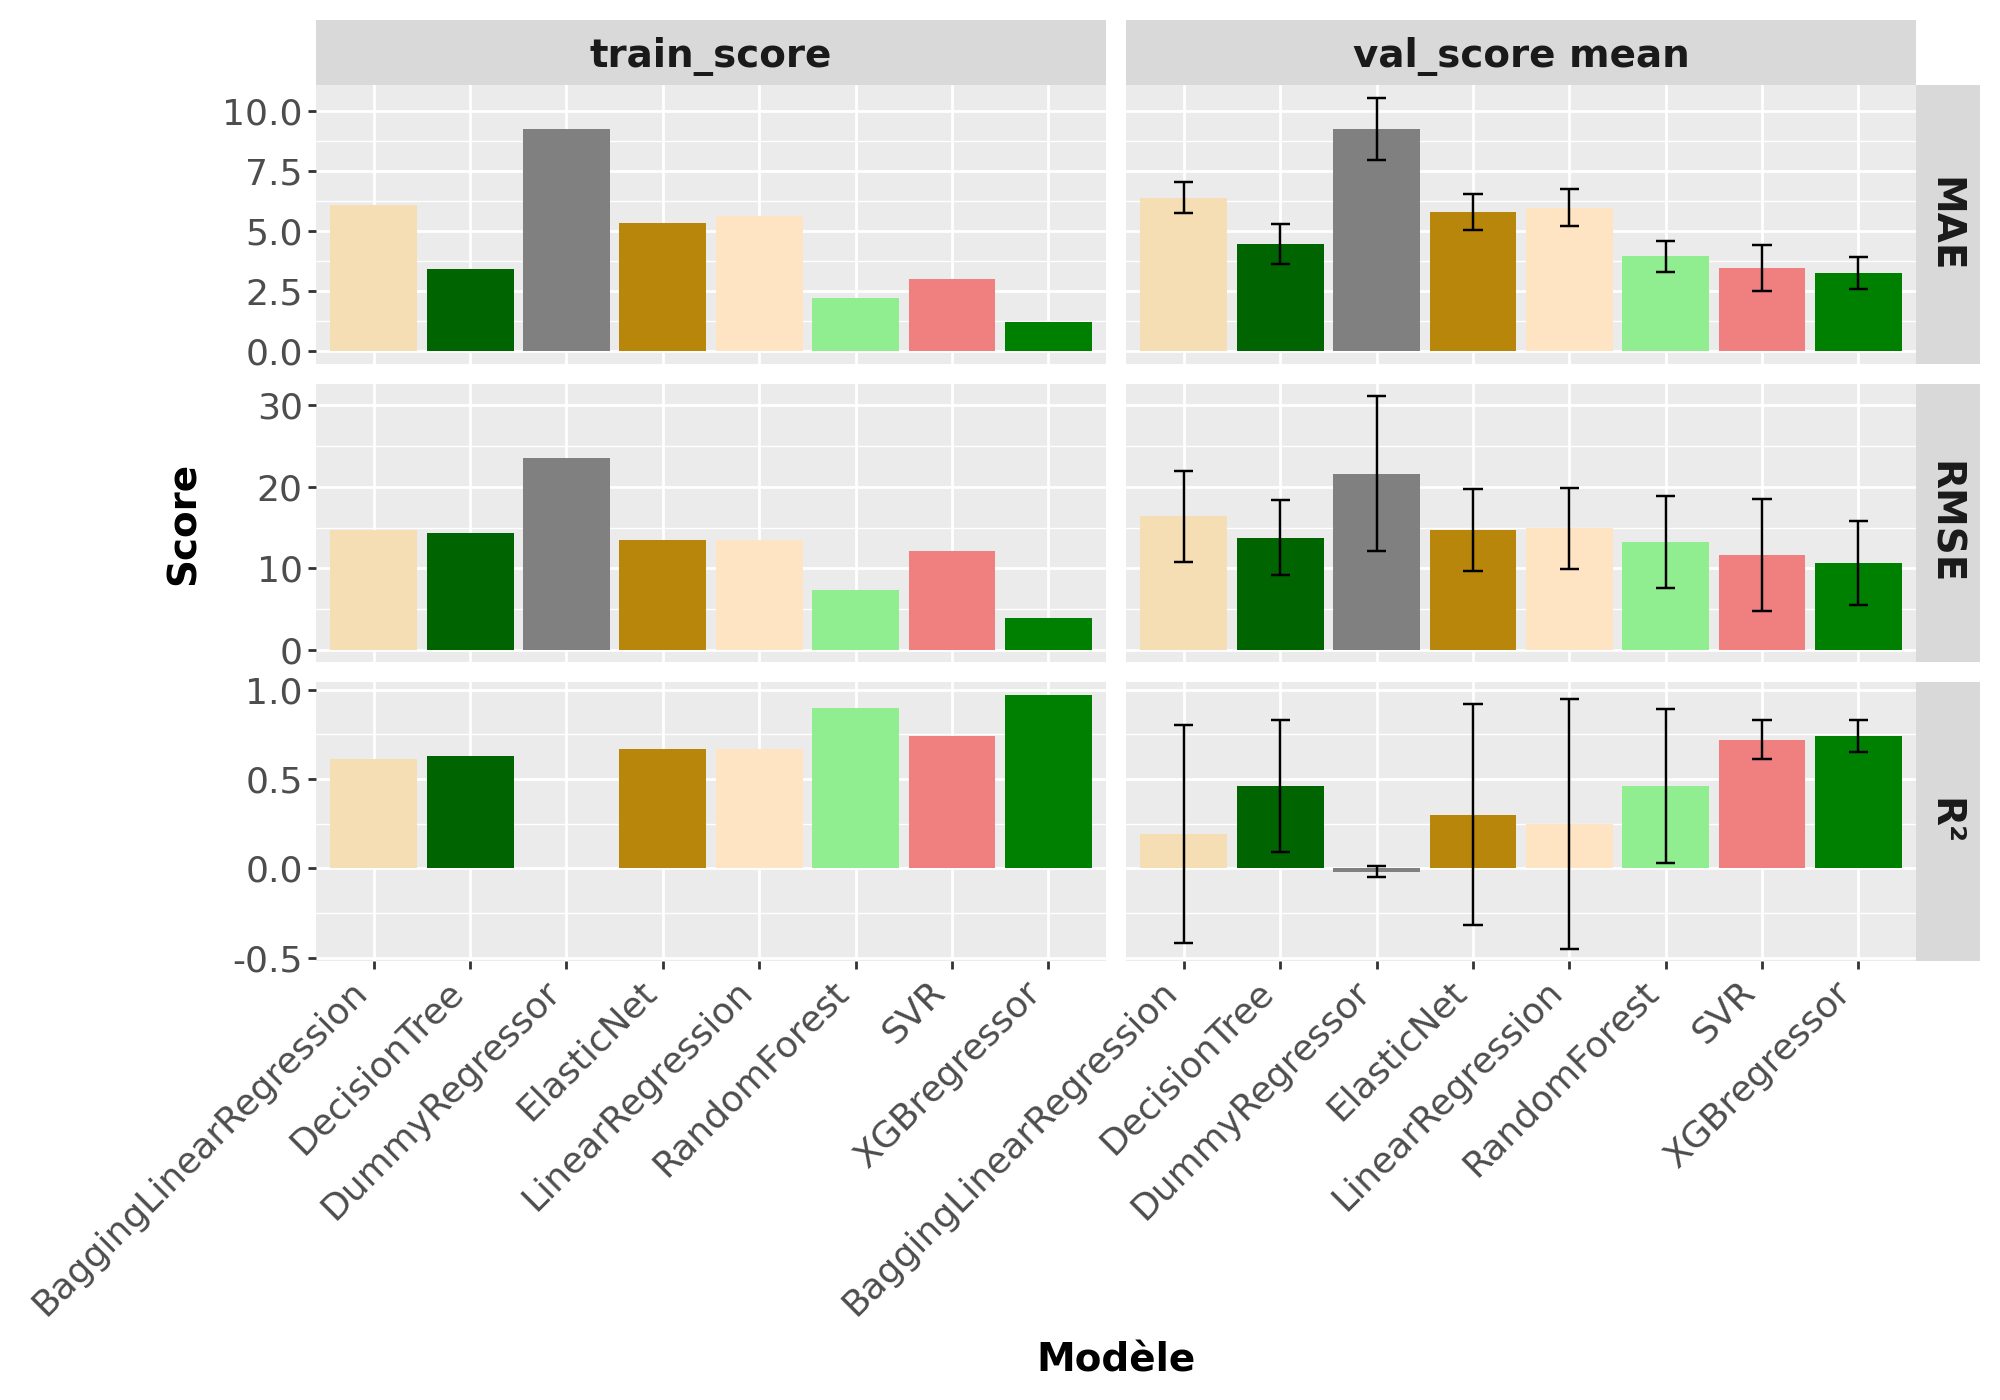

In [76]:
# Affichage du graphique présentant les résultats de la première optimisation
opt_graph(resultats)

Bien que leurs trois scores de performances analysés en validation croisée soient que ceux obtenus par modèle naif, les modèles linéaires ont globalement de moins bonnes performances que les autres modèles testés. L'utilisation d'une approche de bagging n'améliore pas les scores de MAE et de RMSE mais conduit à une prédiction global moins bonne que la régression linéaire simple. La variabilité des scores obtenues en validation croisée sont également tout aussi variable que sans bagging. Un constat similaire peut être fait lorsqu'on introduit et teste une forme de régularisation de la régression linéaire via un modèle de type ElasticNet. 

L'optimisation du modèle de la famille des arbres de décision permet d'obtenir de meilleurs résultats que les modèles linéaires mais on observe des résultats tout aussi variables. Lorsqu'on utilise une approche de bagging sur l'arbre de décision, l'optimisation du RandomForest permet d'obtenir de meilleurs scores sur les trois métriques analysés en validation croisée mais n'a pas permis de réduire les problème de variaiblité.

Finalement, parmi tous les modèles testés, on remarque que deux modèles sortent du lot. Il s'agit du modèle de la famille SVR et du modèle de la famille XGBregressor. Ils ont de meilleurs scores en validation croisée que l'ensemble des autres modèles. Le modèle XGBregressor est légèrement plus stable que le SVR mais a plus tendance à overfiter. On va essayer d'optimiser de manière un peu plus fine ces deux modèles avant de s'arrêter sur l'un ou l'autre.

Enfin, au-delà des performances prédictives, un autre critère possible pour orienter le choix final du modèle correspond au temps d'exécution. Ce critère pourrait s’avérer décisif si les performances des deux modèles restent proches après l’optimisation finale.

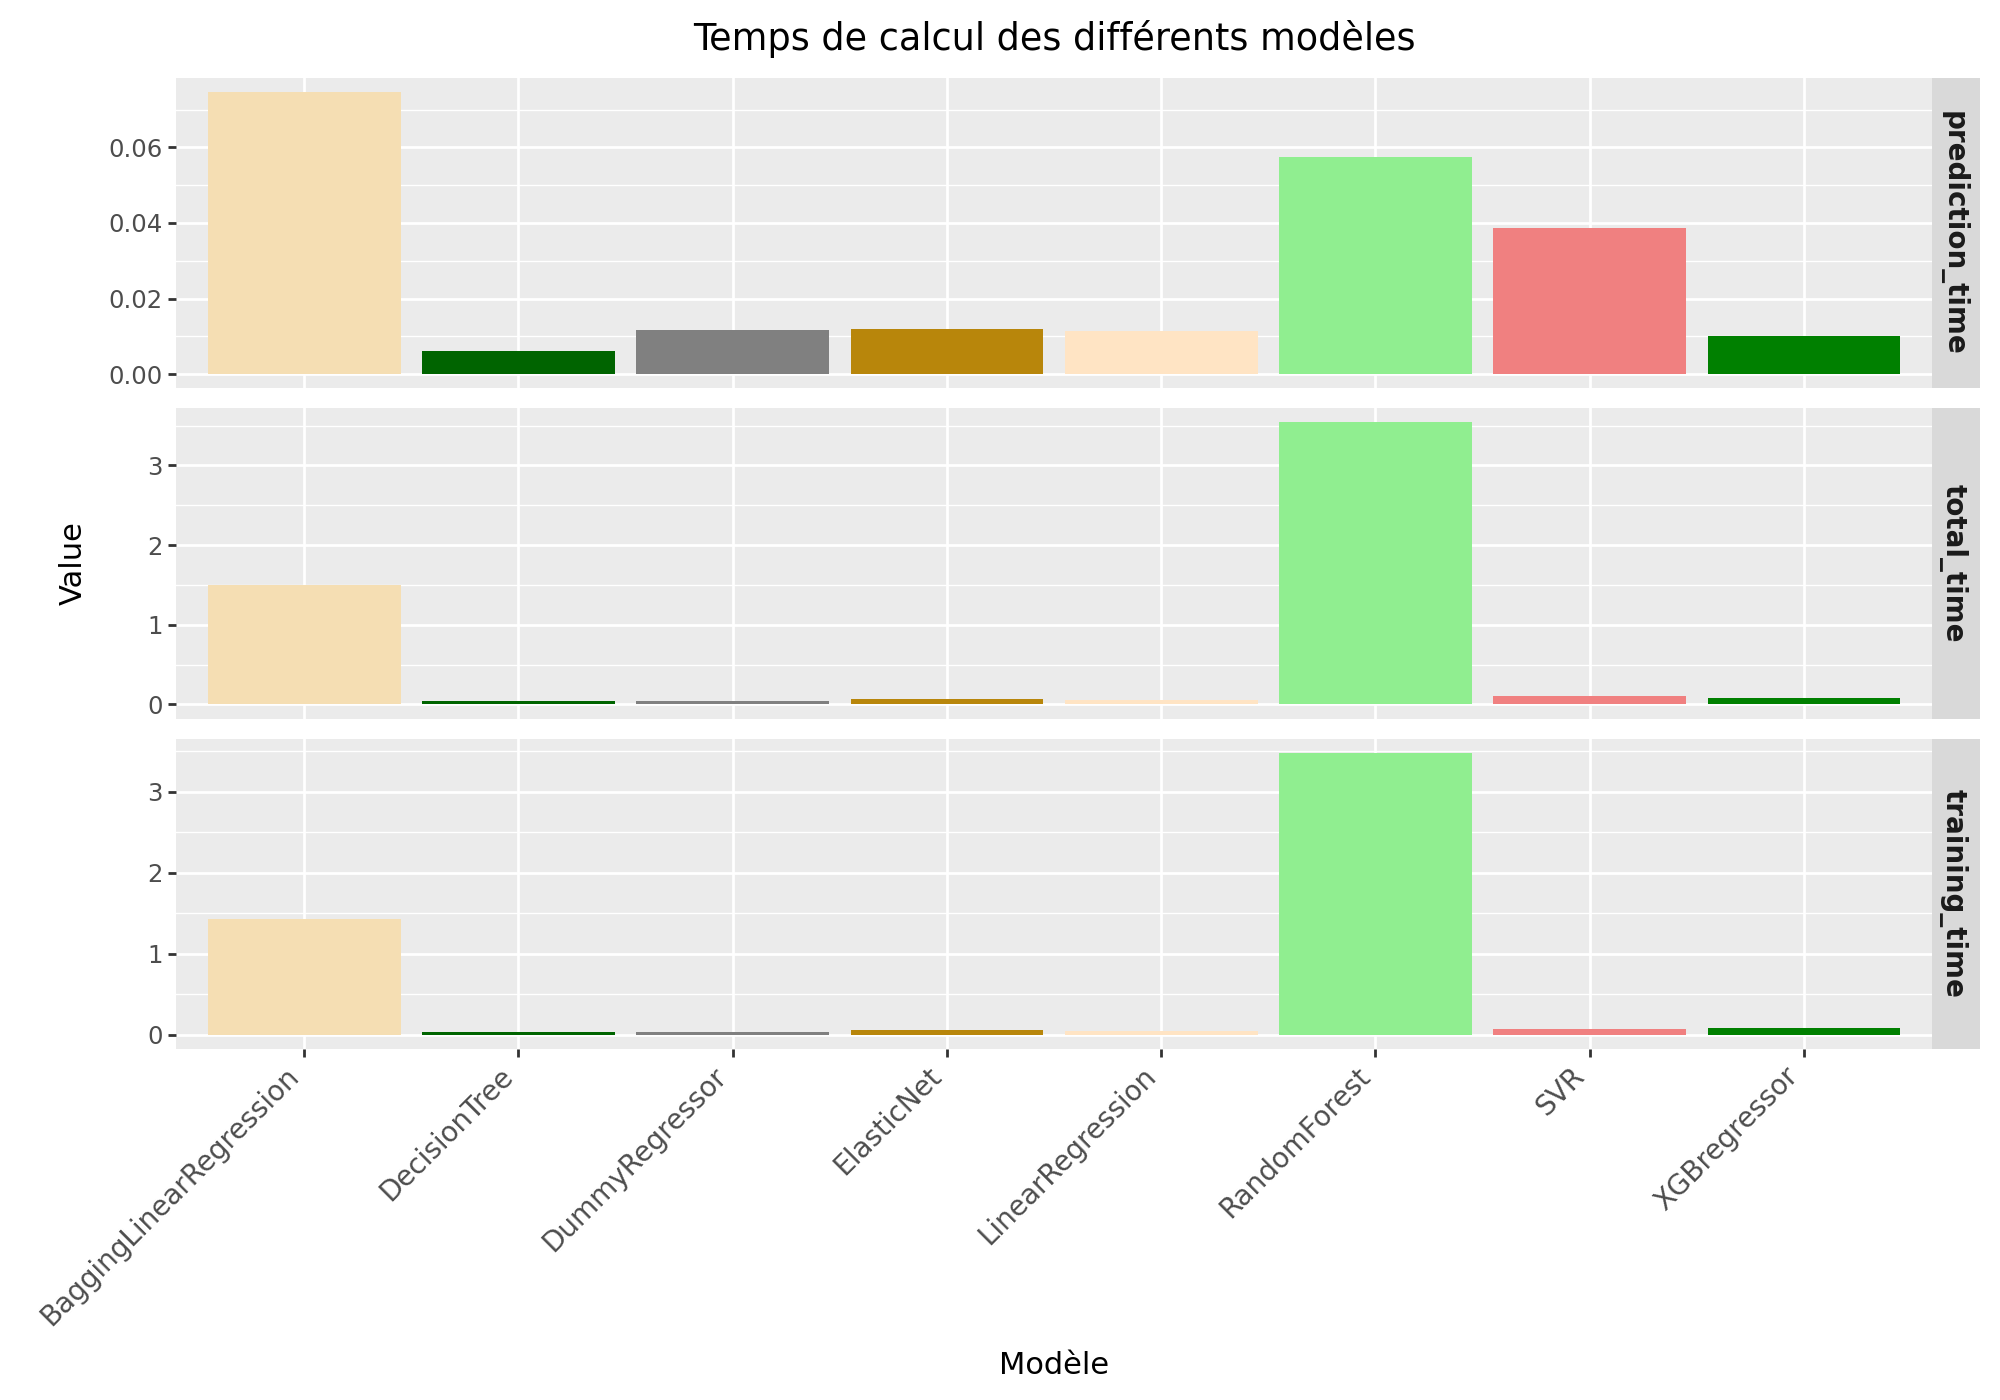

In [77]:
# Calcul du temps de calculs des différents modèle
df_temps, p = execution_time_calculation(best_models,  trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features])

# Affichage du graphique
p

Le graphique ci dessus représente le temps d'exécution de la phase d'entrainement, de prédiction et de l'ensemble de ces deux étapes du modèle optimisé ayant atteint les meilleures performance en termes de RMSE en validation croisée. Globalement, on constate que l'ensemble des modèles testés présentent des temps d'exécution relativement courts. On remarque que les deux modèle utilisant une approche de bagging sont celles qui ont mis le plus de temps à s'éxécuter. Le modèle SVR quant à lui présente un temps de prédiction  a un temps de prédiction supérieur à celui obtenu pour le XGBregressor bien qu'il reste modéré et tout à fait acceptable dans le cadre d'une utilisation pratique. Cela permet de le considérer dans l'étape d'optimisation suivante.

## Optimisation plus fine des modèles retenus

### XGBregressor

In [78]:
# Affichage des paramètres du modèle retenu afin de cibler la plage de valeur à inclure dans la prochaine optimisation
resultats[resultats['model']=='XGBregressor']['best_model_params'].values

array(["{'regressor__max_depth': 3, 'regressor__n_estimators': 100, 'regressor__subsample': 1, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}",
       "{'regressor__max_depth': 3, 'regressor__n_estimators': 100, 'regressor__subsample': 1, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}",
       "{'regressor__max_depth': 3, 'regressor__n_estimators': 100, 'regressor__subsample': 1, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}"],
      dtype=object)

Lors de la première étape d'optimisation il a été testé:
- 100 et 500 estimateurs. le meilleur modèle a été obtenu pour 100 qu'on va garder dans la grille tout en testant d'autres valeurs comprises autour de 100 et entre 100 et 500
- une profondeur de 3, 6 et 10. Le meilleur modèle a été obtenu pour 3 qu'on va garder dans la grille tout en testant d'autres valeurs comprise entre 3 et 6. 
- une proportion d'échantillon de 0.8 et 1. Le meilleur modèle a été obtenu pour 1 qu'on va garder tout en testant d'autres valerus comprises entre 0.8 et 1.

Un autre paramètre important à tester pour un modèle de la famille XGBregresor correspond au taux d'apprentissage qu'on va inclure dans la grille de recherche qui suit.

In [79]:
# Dictionnaire des paramètres à tester pour le XGBRegressor
models_XGB = {
    'XGBregressor': (
        XGBRegressor(booster='gbtree', random_state=rdm_stt),
        {
            'Coltransfs': Coltransfs_no_lin,
            'Coltransfs_named': Coltransfs_no_lin_named,
            'model__regressor__n_estimators': [50, 100, 200,400],
            'model__regressor__max_depth': [3,4,5],
            'model__regressor__subsample' : [0.9, 1],
            'model__regressor__learning_rate' : [0.1,0.3],
            'model__transformer':Target_Transforer
        })}


# Liste des scores à calculer
scoring_list = [root_mean_squared_error, mean_absolute_error, r2_score]

# Appel de la fonction d'optimisation et stockage des résultats
resultats_XGB, best_XGB, gs_XGB = optimiser_models(
    models_XGB, 
    trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features], testset[Variable_cible],
    n_split=5,
    scoring_list=scoring_list,  feature_eng= group_encoder)

✅ Stratification
Optimisation du modèle : XGBregressor


In [80]:
# Affichage des résultats
resultats_XGB

,model,scoring,train_score,val_score mean,val_score std,test_score,best_coltransf,best_model_params
0,XGBregressor,root_mean_squared_error,2.48,10.25,5.51,6.52,ct_0_robust_none_robust_onehot,"{'regressor__learning_rate': 0.1, 'regressor__..."
1,XGBregressor,mean_absolute_error,0.95,3.02,0.75,2.79,ct_0_robust_none_robust_onehot,"{'regressor__learning_rate': 0.1, 'regressor__..."
2,XGBregressor,r2_score,0.99,0.78,0.06,0.77,ct_0_robust_none_robust_onehot,"{'regressor__learning_rate': 0.1, 'regressor__..."


In [81]:
# Affichage des paramètres du meilleur modèle
resultats_XGB[resultats_XGB['model']=='XGBregressor']['best_model_params'].values

array([{'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__n_estimators': 400, 'regressor__subsample': 1, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__n_estimators': 400, 'regressor__subsample': 1, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__n_estimators': 400, 'regressor__subsample': 1, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}],
      dtype=object)

Ici les valeurs optimales obtenues sont :
- 0.1 pour le learning rate : on va tester d'autres valeurs autour de 0.1
- 3 pour la profondeur : on va tester d'autres valeurs autour de 3
- 400 pour le nombre d'estimateurs : on va tester d'autres valeurs autour de 400
- 1 pour la proportion d'observation : on va tester une autre valeur autour de 1

In [82]:
# Dictionnaire des paramètres à tester pour le XGBRegressor
models_XGB = {
    'XGBregressor': (
        XGBRegressor(booster='gbtree', random_state=rdm_stt),
        {
            'Coltransfs': Coltransfs_no_lin,
            'Coltransfs_named': Coltransfs_no_lin_named,
            'model__regressor__n_estimators': [350,400,450],
            'model__regressor__max_depth': [1,2,3,4],
            'model__regressor__subsample' : [0.95, 1],
            'model__regressor__learning_rate' : [0.05,0.1,0.2],
            'model__transformer':Target_Transforer
        })}

# Liste des scores à calculer
scoring_list = [root_mean_squared_error, mean_absolute_error, r2_score]

# Appel de la fonction d'optimisation et stockage des résultats
resultats_XGB, best_XGB, gs_XGB = optimiser_models(
    models_XGB, 
    trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features], testset[Variable_cible],
    n_split=5,
    scoring_list=scoring_list,  feature_eng= group_encoder)

✅ Stratification
Optimisation du modèle : XGBregressor


In [83]:
# Affichage des résultats
resultats_XGB

,model,scoring,train_score,val_score mean,val_score std,test_score,best_coltransf,best_model_params
0,XGBregressor,root_mean_squared_error,6.91,8.81,3.11,5.80,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.1, 'regressor__..."
1,XGBregressor,mean_absolute_error,2.08,2.98,0.51,2.48,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.1, 'regressor__..."
2,XGBregressor,r2_score,0.91,0.80,0.08,0.82,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.1, 'regressor__..."


In [84]:
# Affichage des paramètres du meilleur modèle
resultats_XGB[resultats_XGB['model']=='XGBregressor']['best_model_params'].values

array([{'regressor__learning_rate': 0.1, 'regressor__max_depth': 2, 'regressor__n_estimators': 400, 'regressor__subsample': 0.95, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__learning_rate': 0.1, 'regressor__max_depth': 2, 'regressor__n_estimators': 400, 'regressor__subsample': 0.95, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__learning_rate': 0.1, 'regressor__max_depth': 2, 'regressor__n_estimators': 400, 'regressor__subsample': 0.95, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}],
      dtype=object)

Ici les valeurs optimales obtenues sont :
- 0.1 pour le learning rate : on va se fixer sur cette valeur
- 2 pour la profondeur : on va se fixer sur cette valeur
- 400 pour le nombre d'estimateurs : on va se fixer sur cette valeur
- 0.9 pour la proportion d'observation : on va se fixer sur cette valeur

Deux autres paramètres peuvent être testés pour un modèle de la famille XGBregresor. Il s'agit des paramètres de régularisation reg lambda et reg alpha. Différentes valeurs classiques pour ces paramètres vont être testées.

In [85]:
models_XGB = {
    'XGBregressor': (
        XGBRegressor(booster='gbtree', random_state=rdm_stt),
        {
            'Coltransfs': Coltransfs_no_lin,
            'Coltransfs_named': Coltransfs_no_lin_named,
            'model__regressor__n_estimators': [400],
            'model__regressor__max_depth': [2],
            'model__regressor__subsample' : [0.9],
            'model__regressor__reg_alpha':[0, 0.1, 0.5, 1],
            'model__regressor__reg_lambda':[1,5,10],
            'model__regressor__learning_rate' : [0.1],
            'model__transformer':Target_Transforer
        })}


scoring_list = [root_mean_squared_error, mean_absolute_error, r2_score]

resultats_XGB, best_XGB, gs_XGB = optimiser_models(
    models_XGB, 
    trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features], testset[Variable_cible],
    n_split=5,
    scoring_list=scoring_list,  feature_eng= group_encoder)

✅ Stratification
Optimisation du modèle : XGBregressor


In [86]:
resultats_XGB

,model,scoring,train_score,val_score mean,val_score std,test_score,best_coltransf,best_model_params
0,XGBregressor,root_mean_squared_error,9.20,9.16,4.63,6.04,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.1, 'regressor__..."
1,XGBregressor,mean_absolute_error,2.36,3.13,0.82,2.43,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.1, 'regressor__..."
2,XGBregressor,r2_score,0.85,0.79,0.09,0.80,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.1, 'regressor__..."


In [87]:
resultats_XGB[resultats_XGB['model']=='XGBregressor']['best_model_params'].values

array([{'regressor__learning_rate': 0.1, 'regressor__max_depth': 2, 'regressor__n_estimators': 400, 'regressor__reg_alpha': 0.1, 'regressor__reg_lambda': 1, 'regressor__subsample': 0.9, 'transformer': PowerTransformer()},
       {'regressor__learning_rate': 0.1, 'regressor__max_depth': 2, 'regressor__n_estimators': 400, 'regressor__reg_alpha': 0.1, 'regressor__reg_lambda': 1, 'regressor__subsample': 0.9, 'transformer': PowerTransformer()},
       {'regressor__learning_rate': 0.1, 'regressor__max_depth': 2, 'regressor__n_estimators': 400, 'regressor__reg_alpha': 0.1, 'regressor__reg_lambda': 1, 'regressor__subsample': 0.9, 'transformer': PowerTransformer()}],
      dtype=object)

## SVR 

In [88]:
# Affichage des meilleurs paramètres du modèle retenu afin de cibler la plage de valeur à inclure dans la prochaine optimisation
resultats[resultats['model']=='SVR']['best_model_params'].values

array(["{'regressor__C': 1, 'regressor__epsilon': 0.1, 'regressor__gamma': 0.01, 'transformer': PowerTransformer()}",
       "{'regressor__C': 1, 'regressor__epsilon': 0.1, 'regressor__gamma': 0.01, 'transformer': PowerTransformer()}",
       "{'regressor__C': 1, 'regressor__epsilon': 0.1, 'regressor__gamma': 0.01, 'transformer': PowerTransformer()}"],
      dtype=object)

La même approche va être utilisée pour le modèle SVR. On va tester plusieurs valeurs de paramètres soit entre les différentes valeurs testées lorsque l'intervalle était large soit autour de la valeurs optimal lorsque l'intervalle était déjà fin. 

Lors de la première étape d'optimisation il a été testé:
- 10 et 100 pour le paramètre C. le meilleur modèle a été obtenu pour 1 qu'on va garder dans la grille tout en testant d'autres valeurs comprises entre 1 et 100
- 0.1 et 0.5 pour le paramètre epsilon. Le meilleur modèle a été obtenu pour 0.1 qu'on va garder dans la grille tout en testant d'autres valeurs comprises entre 0.1 et 0.5. 
- 0.001, 0.01 et 0.1 pour le paramètre gamma. Le meilleur modèle a été obtenu pour 0.01 qu'on va garder tout en testant d'autres valeurs  autour de 0.01

In [89]:
# Dictionnaire des paramètres à tester pour le SVR
models_SVR = {
    'SVR': (SVR(),
    {
        'Coltransfs': Coltransfs_no_lin,
        'Coltransfs_named': Coltransfs_no_lin_named,
        'model__regressor__C':[1, 10,20,50,80],
        'model__regressor__epsilon':[0.01, 0.1, 0.2, 0.4],
        'model__regressor__gamma':[0.005, 0.01, 0.05],
        'model__transformer':Target_Transforer

    })}

# Liste des scores à calculer
scoring_list = [root_mean_squared_error, mean_absolute_error, r2_score]

# Appel de la fonction d'optimisation et stockage des résultats
resultats_SVR, best_SVR, gs_SVR = optimiser_models(
    models_SVR, 
    trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features], testset[Variable_cible],
    n_split=5,
    scoring_list=scoring_list,  feature_eng= group_encoder)

✅ Stratification
Optimisation du modèle : SVR


In [90]:
# Affichage des résultats
resultats_SVR

,model,scoring,train_score,val_score mean,val_score std,test_score,best_coltransf,best_model_params
0,SVR,root_mean_squared_error,10.88,10.44,6.70,7.11,ct_2_robust_log_robust_onehot,"{'regressor__C': 10, 'regressor__epsilon': 0.2..."
1,SVR,mean_absolute_error,2.54,2.98,0.81,2.38,ct_2_robust_log_robust_onehot,"{'regressor__C': 10, 'regressor__epsilon': 0.2..."
2,SVR,r2_score,0.79,0.77,0.12,0.73,ct_2_robust_log_robust_onehot,"{'regressor__C': 10, 'regressor__epsilon': 0.2..."


In [91]:
# Affichage des paramètres du meilleur modèle
resultats_SVR[resultats_SVR['model']=='SVR']['best_model_params'].values

array([{'regressor__C': 10, 'regressor__epsilon': 0.2, 'regressor__gamma': 0.01, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__C': 10, 'regressor__epsilon': 0.2, 'regressor__gamma': 0.01, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__C': 10, 'regressor__epsilon': 0.2, 'regressor__gamma': 0.01, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}],
      dtype=object)

Ici les meilleurs paramètres sont
- 10 pour le paramètre C qu'on va garder dans la grille tout en testant d'autres valeurs comprises autour de 10
- 0.2 pour le paramètre epsilon qu'on va garder dans la grille tout en testant d'autres valeurs comprises entre 0.1 et 0.5. 
- 0.01  pour le paramètre gamma. qu'on va garder tout en testant d'autres valeurs en dessous de 0.01

In [92]:
# Dictionnaire des paramètres à tester pour le SVR
models_SVR = {
    'SVR': (SVR(),
    {
        'Coltransfs': Coltransfs_no_lin,
        'Coltransfs_named': Coltransfs_no_lin_named,
        'model__regressor__C':[5, 10, 15],
        'model__regressor__epsilon':[0.15, 0.2, 0.25],
        'model__regressor__gamma':[0.005, 0.01],
        'model__transformer':Target_Transforer

    })}

# Liste des scores à calculer
scoring_list = [root_mean_squared_error, mean_absolute_error, r2_score]

# Appel de la fonction d'optimisation et stockage des résultats
resultats_SVR, best_SVR, gs_SVR = optimiser_models(
    models_SVR, 
    trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features], testset[Variable_cible],
    n_split=5,
    scoring_list=scoring_list,  feature_eng= group_encoder)

✅ Stratification
Optimisation du modèle : SVR


In [93]:
# Affichage des résultats
resultats_SVR

,model,scoring,train_score,val_score mean,val_score std,test_score,best_coltransf,best_model_params
0,SVR,root_mean_squared_error,11.35,10.40,6.52,7.50,ct_2_robust_log_robust_onehot,"{'regressor__C': 5, 'regressor__epsilon': 0.2,..."
1,SVR,mean_absolute_error,2.65,3.03,0.81,2.56,ct_2_robust_log_robust_onehot,"{'regressor__C': 5, 'regressor__epsilon': 0.2,..."
2,SVR,r2_score,0.77,0.77,0.12,0.70,ct_2_robust_log_robust_onehot,"{'regressor__C': 5, 'regressor__epsilon': 0.2,..."


In [94]:
# Affichage des paramètres du meilleur modèle
resultats_SVR[resultats_SVR['model']=='SVR']['best_model_params'].values

array([{'regressor__C': 5, 'regressor__epsilon': 0.2, 'regressor__gamma': 0.01, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__C': 5, 'regressor__epsilon': 0.2, 'regressor__gamma': 0.01, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__C': 5, 'regressor__epsilon': 0.2, 'regressor__gamma': 0.01, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}],
      dtype=object)

Ici les meilleurs paramètres sont
- 5 pour le paramètre C qu'on va garder dans la grille tout en testant d'autres valeurs autour de 5
- 0.2 pour le paramètre epsilon qu'on fixer
- 0.01  pour le paramètre gamma. qu'on va fixer

In [95]:
# Dictionnaire des paramètres à tester pour le SVR
models_SVR = {
    'SVR': (SVR(),
    {
        'Coltransfs': Coltransfs_no_lin,
        'Coltransfs_named': Coltransfs_no_lin_named,
        'model__regressor__C':[3, 5, 7],
        'model__regressor__epsilon':[ 0.2],
        'model__regressor__gamma':[0.01],
        'model__transformer':Target_Transforer

    })}

# Liste des scores à calculer
scoring_list = [root_mean_squared_error, mean_absolute_error, r2_score]

# Appel de la fonction d'optimisation et stockage des résultats
resultats_SVR, best_SVR, gs_SVR = optimiser_models(
    models_SVR, 
    trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features], testset[Variable_cible],
    n_split=5,
    scoring_list=scoring_list,  feature_eng= group_encoder)

✅ Stratification
Optimisation du modèle : SVR


In [96]:
# Affichage des résultats
resultats_SVR

,model,scoring,train_score,val_score mean,val_score std,test_score,best_coltransf,best_model_params
0,SVR,root_mean_squared_error,11.13,10.33,6.58,7.59,ct_2_robust_log_robust_onehot,"{'regressor__C': 7, 'regressor__epsilon': 0.2,..."
1,SVR,mean_absolute_error,2.56,2.98,0.81,2.56,ct_2_robust_log_robust_onehot,"{'regressor__C': 7, 'regressor__epsilon': 0.2,..."
2,SVR,r2_score,0.78,0.77,0.12,0.69,ct_2_robust_log_robust_onehot,"{'regressor__C': 7, 'regressor__epsilon': 0.2,..."


## Choix final

In [97]:
# Concaténation des résultats
pd.concat([resultats_SVR, resultats_XGB])

,model,scoring,train_score,val_score mean,val_score std,test_score,best_coltransf,best_model_params
0,SVR,root_mean_squared_error,11.13,10.33,6.58,7.59,ct_2_robust_log_robust_onehot,"{'regressor__C': 7, 'regressor__epsilon': 0.2,..."
1,SVR,mean_absolute_error,2.56,2.98,0.81,2.56,ct_2_robust_log_robust_onehot,"{'regressor__C': 7, 'regressor__epsilon': 0.2,..."
2,SVR,r2_score,0.78,0.77,0.12,0.69,ct_2_robust_log_robust_onehot,"{'regressor__C': 7, 'regressor__epsilon': 0.2,..."
0,XGBregressor,root_mean_squared_error,9.20,9.16,4.63,6.04,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.1, 'regressor__..."
1,XGBregressor,mean_absolute_error,2.36,3.13,0.82,2.43,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.1, 'regressor__..."
2,XGBregressor,r2_score,0.85,0.79,0.09,0.80,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.1, 'regressor__..."


Suite à cette optimisation un peu plus fine, XGBregressor semble être le modèle le plus intéressant à retenir. En effet, c'est celui qui obtient les meilleurs scores sur le R² et la RMSE. Il est également plus stable que le SVR sur chacune d'entre elles. Malgrès un petit overfit, ses performances obtenues en validation croisée font que ce modèle est le plus promotteur parmi les deux. On peut observe également une amélioration notable de ses performances comparativement à celles observées suite à la première phase d'optimisation. En effet, le R² est passée de 0.74 à 0.79, la MAE est passé de 3.25.10⁶ à 3.13.10⁶ KBtu et la RMSE est passée de 10.66.10⁶ à 9.16.10⁶ KBtu.

In [98]:
# Calcul du temps de calculs des différents modèle
df_temps_XGB, p_XGB = execution_time_calculation(best_XGB,  trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features])

# Calcul du temps de calculs des différents modèle
df_temps_SVR, p_SVR = execution_time_calculation(best_SVR,  trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features])

# Affichage du graphique
pd.concat([df_temps_SVR, df_temps_XGB])

,model,Time,Value
0,SVR,training_time,0.098330
1,SVR,prediction_time,0.036268
2,SVR,total_time,0.134597
0,XGBregressor,training_time,0.238115
1,XGBregressor,prediction_time,0.015999
2,XGBregressor,total_time,0.254114


On peut essayer d'améliorer davantage les performances du modèle retenu en utilisant une méthode de selection de variables. Pour cela, on peut utiliser une approche conssitant à selection,er les k meilleures variables selon leur importance estimée par le modèle déjà entrainé. Plusieurs valeurs de k seront testées afin d'identifier celle qui permet d'obtenir les meilleurs scores de performance.

## Selection de variables

In [99]:
# Extraction des résultats GridSearch du modèle optimisé
gs = gs_XGB['XGBregressor']  
best_params = gs.best_params_
model_name = model.__class__.__name__

# Extraction de la meilleure combinaison de transformation de features
coltransfs_named = models_XGB['XGBregressor'][1]['Coltransfs_named']
reverse_named = {v: k for k, v in coltransfs_named.items()}
Coltransf = best_params['Coltransfs']

# Extraction des hyperparamètres optimisés du modèle
model_params = {
    key.replace('model__regressor__', ''): val
    for key, val in best_params.items()
    if key.startswith('model__regressor__')
}

# Définition des paramètres fixés en dehors des paramètres à optimiser
default_params = {
    'random_state': rdm_stt,
    'booster': 'gbtree'
}

# Concaténation des paramètres optimisés et des paramètres fixés en dehors de la grille de recherche
full_model_params = {**default_params, **model_params}

# Reconstruction du modèle 
model = XGBRegressor()
model.set_params(**full_model_params)

# Extraction du transformer de la target
target_transformer = gs.best_params_['model__transformer']

In [100]:
# Initiatiolisation d'une liste pour stocker les résultats
resultats_list = []  

# Calcul du nombre de features présentes dans le jeu de données après préprocessing des features
output_n_col = Coltransf.fit_transform(trainset[Selected_features], trainset[Variable_cible]).shape[1]

for k in range(1, output_n_col + 1):
    Feat_extr = SelectFromModel(estimator=model, threshold=-np.inf, max_features=k)

    # Évaluation avec R²
    RES_a = evaluation_model(
        Coltransf, model, 
        trainset[Selected_features], trainset[Variable_cible], 
        testset[Selected_features], testset[Variable_cible],
        5, r2_score, 'R²', feat_extr=Feat_extr, target_transformer=target_transformer,
        affichage=False)

    # Évaluation avec MAE
    RES_b = evaluation_model(
        Coltransf, model, 
        trainset[Selected_features], trainset[Variable_cible], 
        testset[Selected_features], testset[Variable_cible],
        5, mean_absolute_error, 'MAE', feat_extr=Feat_extr, target_transformer=target_transformer,
        affichage=False)

    # Évaluation avec RMSE
    RES_c = evaluation_model(
        Coltransf, model, 
        trainset[Selected_features], trainset[Variable_cible], 
        testset[Selected_features], testset[Variable_cible],
        5, root_mean_squared_error, 'RMSE', feat_extr=Feat_extr, target_transformer=target_transformer,
         affichage=False)

    # Ajout de la valeur de k à chaque ligne de résultat
    for res in RES_a + RES_b + RES_c:
        res['k'] = k
        resultats_list.append(res)

# Création de la DataFrame 
resultats_feat_ext = pd.DataFrame(resultats_list)


In [101]:
# Affichage du classement des meilleurs score de MAE
resultats_feat_ext[resultats_feat_ext['scoring']=='MAE'].sort_values('val_score mean', ascending=True).head(10)

,model,scoring,train_score,val_score mean,val_score std,test_score,k
34,XGBRegressor,MAE,2.36,3.13,0.82,2.43,12
31,XGBRegressor,MAE,2.65,3.34,1.06,2.55,11
19,XGBRegressor,MAE,2.19,3.36,0.91,2.64,7
25,XGBRegressor,MAE,2.43,3.46,0.84,2.56,9
28,XGBRegressor,MAE,2.63,3.55,1.25,2.66,10
22,XGBRegressor,MAE,2.41,3.74,1.25,2.64,8
13,XGBRegressor,MAE,2.73,3.99,0.65,3.34,5
16,XGBRegressor,MAE,2.77,4.13,0.80,3.39,6
10,XGBRegressor,MAE,2.66,4.29,0.64,3.39,4
7,XGBRegressor,MAE,3.03,5.87,1.12,3.81,3


In [102]:
# Affichage du classement des meilleurs score de R²
resultats_feat_ext[resultats_feat_ext['scoring']=='R²'].sort_values('val_score mean', ascending=False).head(10)

,model,scoring,train_score,val_score mean,val_score std,test_score,k
33,XGBRegressor,R²,0.85,0.79,0.09,0.80,12
24,XGBRegressor,R²,0.87,0.76,0.03,0.78,9
18,XGBRegressor,R²,0.92,0.74,0.14,0.76,7
30,XGBRegressor,R²,0.67,0.73,0.13,0.79,11
27,XGBRegressor,R²,0.73,0.72,0.13,0.78,10
15,XGBRegressor,R²,0.86,0.66,0.10,0.66,6
21,XGBRegressor,R²,0.88,0.64,0.18,0.76,8
12,XGBRegressor,R²,0.84,0.60,0.25,0.63,5
9,XGBRegressor,R²,0.88,0.59,0.15,0.63,4
6,XGBRegressor,R²,0.81,0.13,0.63,0.59,3


In [103]:
# Affichage du classement des meilleurs score de RMSE
resultats_feat_ext[resultats_feat_ext['scoring']=='RMSE'].sort_values('val_score mean', ascending=True).head(10)

,model,scoring,train_score,val_score mean,val_score std,test_score,k
35,XGBRegressor,RMSE,9.20,9.16,4.63,6.04,12
32,XGBRegressor,RMSE,13.50,10.43,5.46,6.19,11
20,XGBRegressor,RMSE,6.76,10.50,6.59,6.62,7
26,XGBRegressor,RMSE,8.49,10.51,4.85,6.39,9
29,XGBRegressor,RMSE,12.18,11.24,6.62,6.39,10
14,XGBRegressor,RMSE,9.30,12.22,5.22,8.23,5
17,XGBRegressor,RMSE,8.75,12.26,6.18,7.96,6
11,XGBRegressor,RMSE,8.29,12.72,5.01,8.28,4
23,XGBRegressor,RMSE,8.08,12.81,7.02,6.69,8
5,XGBRegressor,RMSE,13.57,17.26,5.15,8.77,2


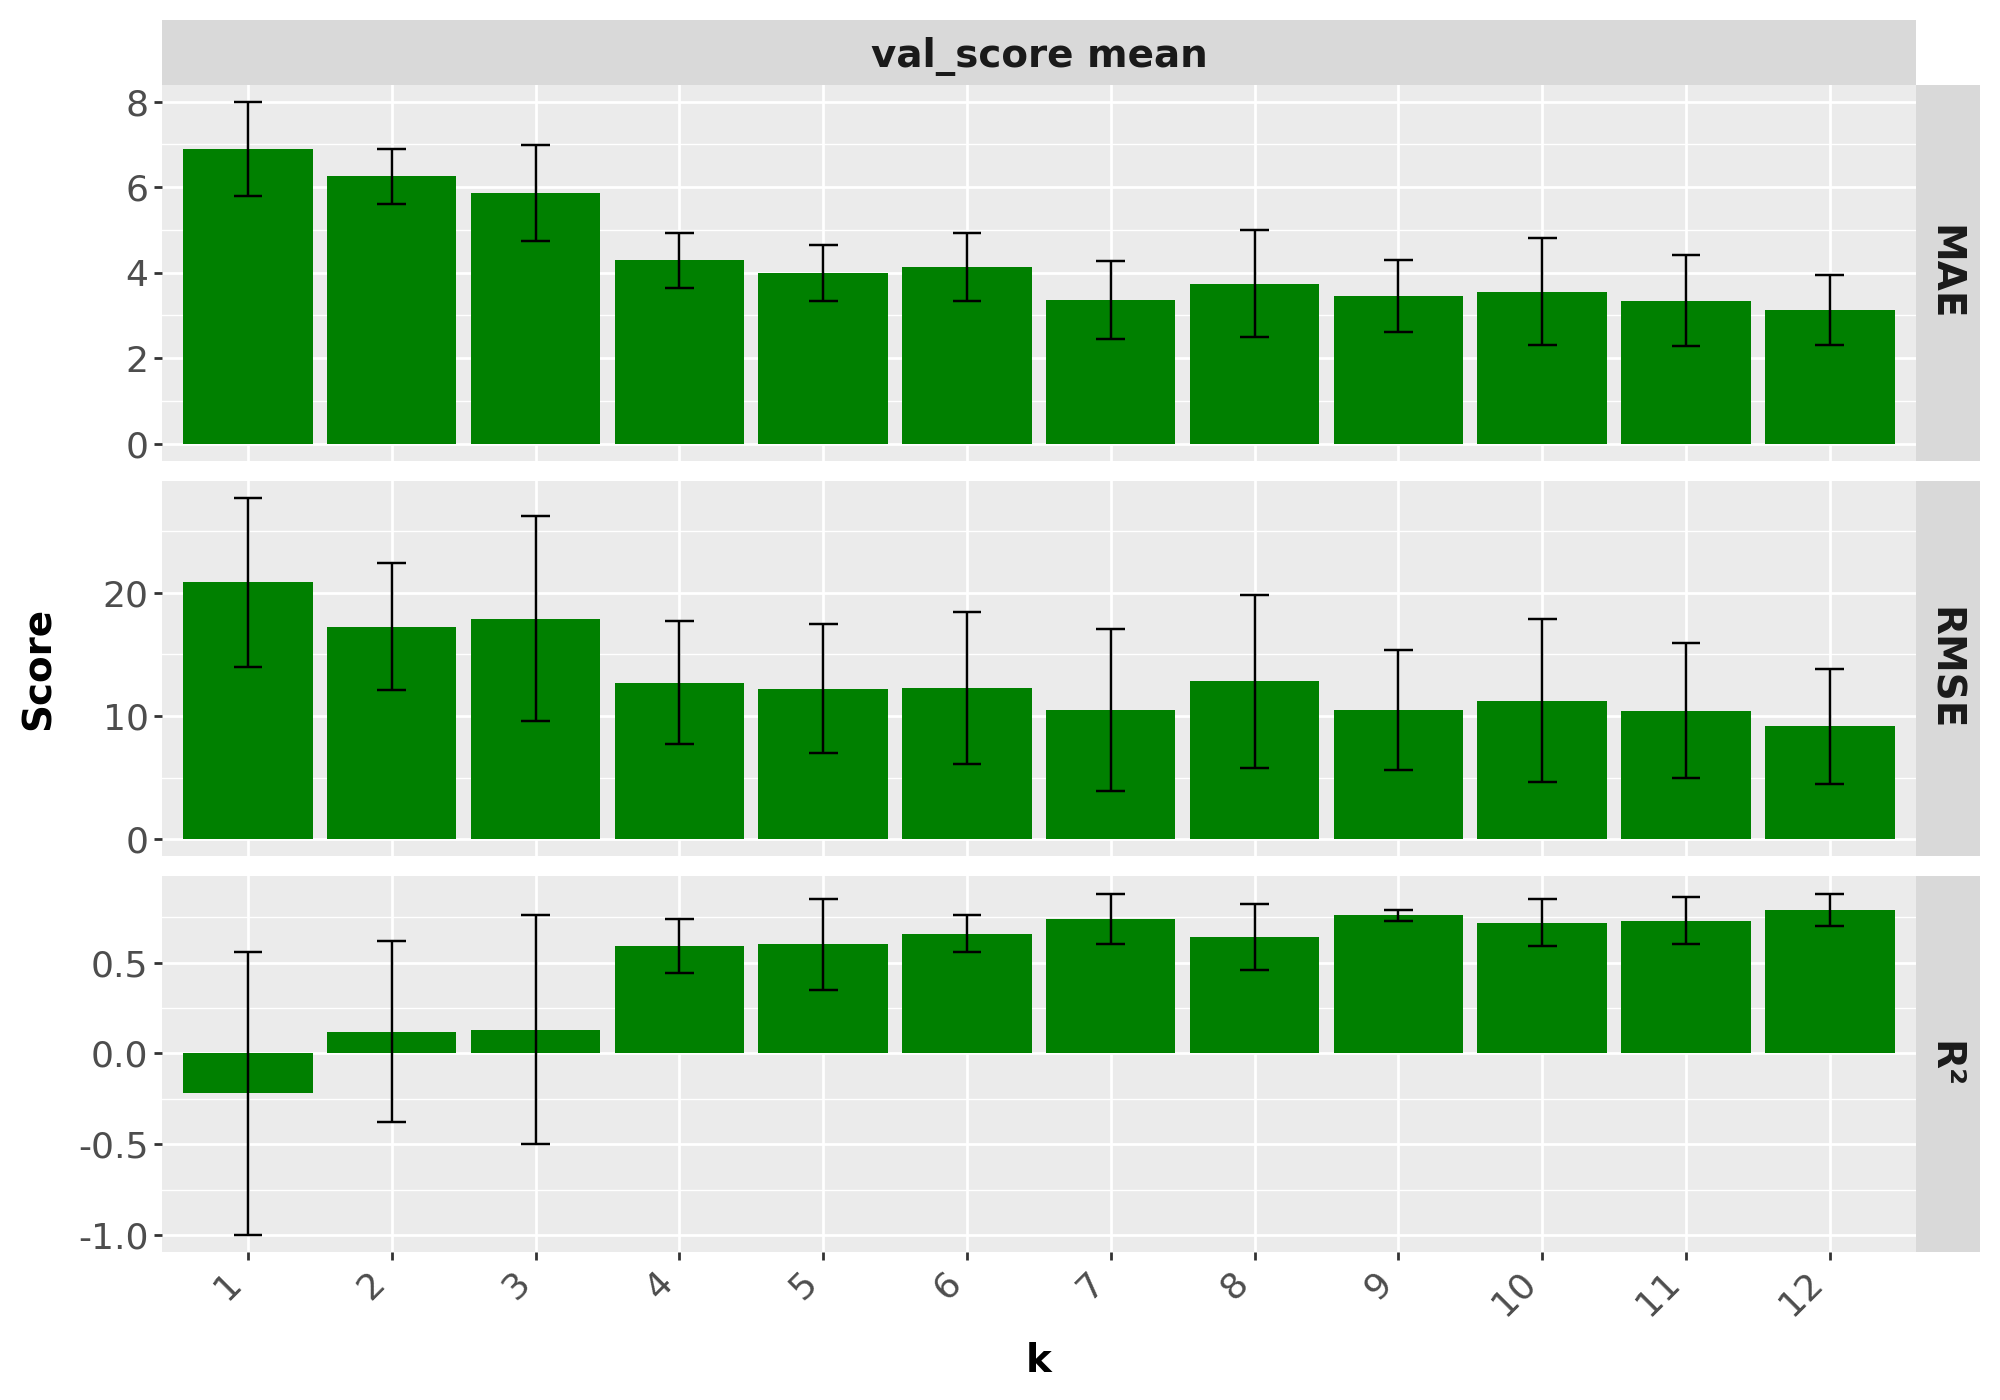

In [104]:
# Visualisation graphique des résultats
opt_graph(resultats_feat_ext, option='k')

Le test des différents k permet de conclure que le modèle a besoin de toutes les variables pour atteindre ses meilleures performances et cela s'oberve pour chacune des métriques d'évaluation. Le modèle final ne prendra donc pas en compte d'étape de selection de variable. 

Avant d'évaluer le modèle final de façon plus approfondie, l'impact de la variable ENERGYSTAR score va être étudié.

# Impact de ENERGYStar

**Avec EnergySTAR**

In [105]:
# Définition de la méthode de selection de variable
Feat_extr = 'passthrough'

In [106]:
# Evaluation de la MAE du modèle avec ENERGYSTAR
res_with_ESS_a = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE', feat_extr=Feat_extr, target_transformer=target_transformer,
                 affichage=None)

In [107]:
# Evaluation du R² du modèle avec ENERGYSTAR
res_with_ESS_b = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²', feat_extr=Feat_extr, target_transformer=target_transformer,
                 affichage=None)

In [108]:
# Evaluation de la RMSE du modèle avec ENERGYSTAR
res_with_ESS_c =  evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE', feat_extr=Feat_extr, target_transformer=target_transformer,
                 affichage=None)

In [109]:
# Ajout d'une variable indiquant la présence ou non de la variable ENERGYSTAR
res_with_ESS = []
for res in res_with_ESS_a + res_with_ESS_b + res_with_ESS_c:
        res['ESS'] = 'Yes'
        res_with_ESS.append(res)

# Création de la DataFrame 
res_with_ESS = pd.DataFrame(res_with_ESS)

**Sans ENERGYSTAR**

Pour analyser les performances du modèle sans la variable ENERGYSTAR score, il faut la retirer des variable selectionnée et de la liste de variable numériques définie pour l'étape de préprocessing. Il faudra de plus, reconstruire ces transformeurs pour pas que la variable retirée soit prise en compte. 

In [110]:
# Supression de la variable ENERGYSTARscore des différentes listes
Selected_features = [x for x in Selected_features if x != 'ENERGYSTARScore'] 
num_cols = [x for x in num_cols if x != 'ENERGYSTARScore'] 

In [111]:
# Création des différentes combinaisons de préprocessing adaptées aux modèles linéaires
Coltransfs_lin_named = combined_ct(num_cols, log_cols, cat_cols, 'first')
Coltransfs_lin = [x[1] for x in Coltransfs_lin_named]
Coltransfs_lin_named = dict(Coltransfs_lin_named)

# Création des différentes combinaisons de préprocessing adaptées aux modèles non linéaires
Coltransfs_no_lin_named = combined_ct(num_cols, log_cols, cat_cols, None)
Coltransfs_no_lin = [x[1] for x in Coltransfs_no_lin_named]
Coltransfs_no_lin_named = dict(Coltransfs_no_lin_named)

In [112]:
# Définition de la méthode de selection de variable
Feat_extr = 'passthrough'

# Définition de l'étape de préprocessing
Coltransf_imp = Coltransfs_no_lin[1]

In [113]:
# Evaluation de la MAE du modèle sans ENERGYSTAR
res_wo_ESS_a = evaluation_model(Coltransf_imp, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE', feat_extr=Feat_extr, target_transformer=target_transformer,
                 affichage=None)

In [114]:
# Evaluation du R² du modèle sans ENERGYSTAR
res_wo_ESS_b = evaluation_model(Coltransf_imp,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²', feat_extr=Feat_extr, target_transformer=target_transformer,
                 affichage=None)

In [115]:
# Evaluation de la RMSE du modèle sans ENERGYSTAR
res_wo_ESS_c =  evaluation_model(Coltransf_imp, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE', feat_extr=Feat_extr, target_transformer=target_transformer,
                 affichage=None)

In [116]:
# Ajout d'une variable indiquant la présence ou non de la variable ENERGYSTAR
res_wo_ESS = []
for res in res_wo_ESS_a + res_wo_ESS_b + res_wo_ESS_c:
        res['ESS'] = 'No'
        res_wo_ESS.append(res)

# Création de la DataFrame 
res_wo_ESS = pd.DataFrame(res_wo_ESS)

In [117]:
# Concaténation des deux tables de résultats
res_comparaison = pd.concat([res_with_ESS, res_wo_ESS])

# Affichage des résultats
res_comparaison

,model,scoring,train_score,val_score mean,val_score std,test_score,ESS
0,XGBRegressor,MAE,2.36,3.13,0.82,2.43,Yes
1,XGBRegressor,R²,0.85,0.79,0.09,0.80,Yes
2,XGBRegressor,RMSE,9.20,9.16,4.63,6.04,Yes
0,XGBRegressor,MAE,2.94,3.74,0.71,3.20,No
1,XGBRegressor,R²,0.73,0.70,0.11,0.73,No
2,XGBRegressor,RMSE,12.23,11.46,6.08,7.01,No


Les performances prédictives du modèle sont meilleures avec la variable ENERGYSTARscore. Toutefois, cette variable est construite à partir des données de consommations réelles. Son usage soulève donc une contradiction: si l'on dispose déjà de l'ENERGYSTARscore, c'est que l'on connait déjà la consommation énergétique rendant ainsi la prédiction inutile. Pour l'analyse finale du modèle cette variable ne sera donc pas prise en compte. 

In [118]:
# Stockage des transformations à effectuer pour le modèle sans ENERGYSTARscore
Coltransf = Coltransf_imp

# Evaluation détaillée du modèle final

En plus des fonctions d'évaluation de modèles précédemment définies, une autre fonction va être définie afin de visualiser l'importance de chacune des features estimée par le modèle.

## Fonction

In [119]:
def get_feature_names_from_column_transformer(coltransf, input_features):
    
    """
    Extrait la liste des noms de features produites par un `ColumnTransformer` après transformation,
    en tenant compte des différents types de transformateurs (Pipeline, passthrough, encodeurs, etc.).

    Paramètres
     - coltransf (sklearn.compose.ColumnTransformer): Le `ColumnTransformer` déjà ajusté (fit) contenant les transformations appliquées sur les colonnes.
     - input_features (list ou array-like): Liste des noms des features d'entrée avant transformation (peut être utilisée pour certaines méthodes).

    Sortie
     - list de str: Liste complète des noms des features issues du `ColumnTransformer`, dans l'ordre des colonnes transformées.

    """
        
    # Initialisation de la variable stockant les noms des features
    feature_names = []

    for name, transformer, columns in coltransf.transformers_:

        if transformer == 'passthrough':
            feature_names.extend(columns)
        elif isinstance(transformer, Pipeline):
            # Extraction du dernier step
            last_step = transformer.steps[-1][1]
            if hasattr(last_step, 'get_feature_names_out'):
                try:
                    names = last_step.get_feature_names_out(columns)
                except:
                    names = last_step.get_feature_names_out()
                feature_names.extend(names)
            else:
                feature_names.extend(columns)
        elif hasattr(transformer, 'get_feature_names_out'):
            try:
                names = transformer.get_feature_names_out(columns)
            except:
                names = transformer.get_feature_names_out()
            feature_names.extend(names)
        else:
            feature_names.extend(columns)

    return feature_names


In [120]:
def get_feature_importance_from_pipeline(Coltransf, model, Xtrain, Ytrain, 
                     feat_extr='passthrough', feature_eng=group_encoder, target_transformer=None, 
                     top_n=None):


    """
    Entraîne un pipeline complet incluant ingénierie des features, transformation, sélection de variables,
    et extraction de l'importance des variables du modèle final (compatible avec les modèles fournissant `feature_importances_`).

    Paramètres
     - Coltransf (sklearn.compose.ColumnTransformer): Transformateur des colonnes appliqué aux données.
     - model (estimator sklearn compatible): Modèle final disposant de l'attribut `feature_importances_` après entraînement (ex: XGBoost, RandomForest).
     - Xtrain (pd.DataFrame ou array-like): Données d'entraînement (features).
     - Ytrain (pd.Series ou array-like): Cible d'entraînement.
     - feat_extr (transformer ou 'passthrough', optionnel (par défaut='passthrough')): Transformateur de sélection de variables à appliquer après `Coltransf`.
     - feature_eng (transformer, optionnel (par défaut=group_encoder)): Transformations d'ingénierie des variables à appliquer en premier dans le pipeline.
     - target_transformer (transformer ou None, optionnel (par défaut=None)): Transformateur appliqué à la cible via `TransformedTargetRegressor`.
     - top_n (int ou None, optionnel (par défaut=None)): Nombre de variables les plus importantes à afficher. Si None, affiche toutes.

    Sortie
     - pd.DataFrame: DataFrame contenant les features et leur importance, triées par ordre décroissant d'importance.
    """

    # Application d'une transformation sur la variable cible avec TransformedTargetRegressor
    model_t = TransformedTargetRegressor(regressor=model, transformer=target_transformer)

    # Pipeline
    pipeline = Pipeline([
        ('feature_engineering', feature_eng),
        ('Coltransfs', Coltransf),
        ('feature_selection', feat_extr),
        ('model', model_t)
    ])
    
    # Entrainement du pipeline
    pipeline.fit(Xtrain, Ytrain)

    # Accès au modèle final
    model_feat = pipeline.named_steps['model'].regressor_

    # Exctraction des noms de variables transformées
    coltransf = pipeline.named_steps['Coltransfs']
    feature_names = get_feature_names_from_column_transformer(Coltransf, Xtrain)

    # Application éventuelle de la sélection de variables
    feat_selector = pipeline.named_steps.get('feature_selection', None)
    if feat_selector is not None and hasattr(feat_selector, 'get_support'):
        feature_names = np.array(feature_names)
        mask = feat_selector.get_support()
        feature_names = feature_names[mask]
        
    # Extraction de la feature importance
    importances = model_feat.feature_importances_

    # Construction du DataFrame des importances
    df_importance = pd.DataFrame({
        'feature': feature_names,
        'importance': importances
    }).sort_values(by='importance', ascending=False)

    # Filtre de la table si un top_n est spécifié en argument
    if top_n:
        df_importance = df_importance.head(top_n)

    # Nom du modèle
    model_name = model.__class__.__name__

    # Affichage du graphique
    plt.figure(figsize=(10, 0.4 * len(df_importance)))
    plt.barh(df_importance['feature'], df_importance['importance'])
    plt.gca().invert_yaxis()
    plt.title("Top Feature Importances (XGBoost)")
    plt.tight_layout()
    plt.savefig(f'../Output/Modélisation/Explicativité/Consommations/Feature_importance {model_name}.png', format='png')
    plt.show()
    
    return df_importance


## Evaluation de la feature importance

Afin de mieux comprendre comment le modèle à prédit les différentes valeurs, on peut analyser l'importance des différentes features accordées par le modèle.

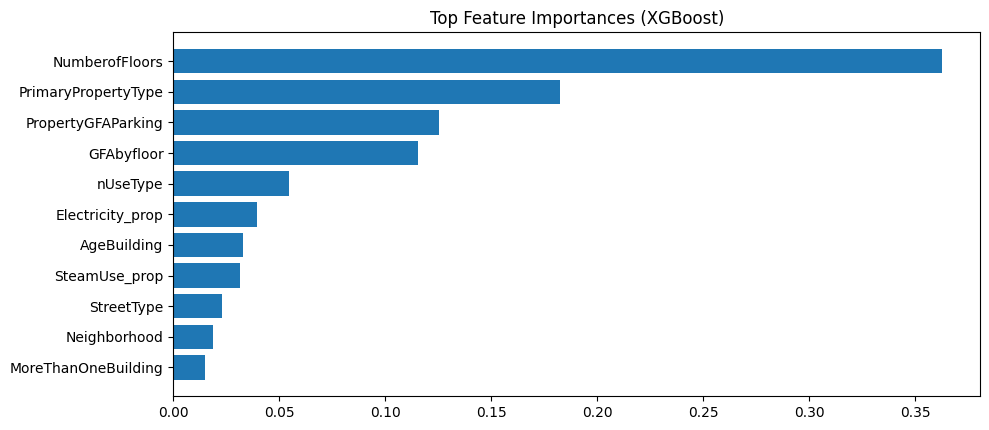

,feature,importance
0,NumberofFloors,0.362463
7,PrimaryPropertyType,0.182278
5,PropertyGFAParking,0.125254
6,GFAbyfloor,0.115551
4,nUseType,0.054582
1,Electricity_prop,0.039183
3,AgeBuilding,0.032814
2,SteamUse_prop,0.031231
9,StreetType,0.022995
8,Neighborhood,0.018576


In [121]:
# Appel de la fonction
get_feature_importance_from_pipeline(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], feat_extr=Feat_extr, target_transformer=target_transformer, top_n=11)

Les features nombre d'étage, surface des parking ainsi que le type de la propriété sont les features les plus importantes du modèle de prédiction de la consommation énergétique. Le nombre d'étage représente à lui seul 29% de l'importance totale ce qui suggère un fort impact de cette variable. A l'inverse la variable indiquant si une propriété a un ou plusieurs bâtiments a eu un très faible impact sur les prédictions. Elle avait toutefois suffisament d'importance pour être conservée comme l'a démontré l'étape de selection de feature qui a montré que les meilleurs performances étaient atteintes lorsque toutes les features étaient conservées.

## Evaluation des erreurs

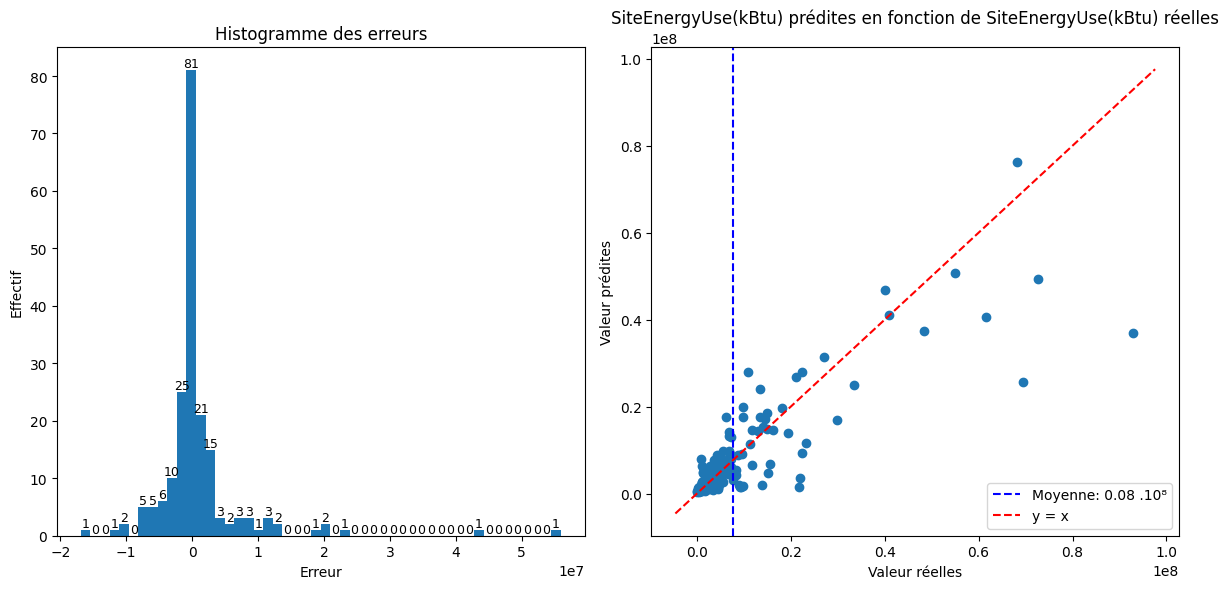

In [122]:
# Affichage des graphiques représentant les erreurs de prédiction
graph_erreur(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
             testset[Selected_features], testset[Variable_cible], feat_extr=Feat_extr, 
             target_transformer=target_transformer, Optimisation="Optimisé")

On observe que la majorité des points se situent à proximité de la droite x=y ce qui indique une bonne capacité du modèle à prédire les valeurs de consommation énergétique pour la plupart des propriétés. Les écarts les plus marqués par rapport à cette droite correspondent aux propriétés dont la consommation énergétique est particulièrement extrême par rapport au reste des propriétés. 

Les plus grosses erreurs faites par le modèle correspondent à des sous-estimations. Ces cas sont problématiques puisque l'objectif est de réduire les émissions de carbone de la ville. Le fait de sous estimer fortement la consommation énergétique de certaines propriétés pourrait en effet conduire à des décisions inadéquates et à l'encontre de l'objectif de la ville de Seattle. Il est donc important d'identifier ces cas problématiques afin que les prédictions de ces cas soient considérées avec précaution. 

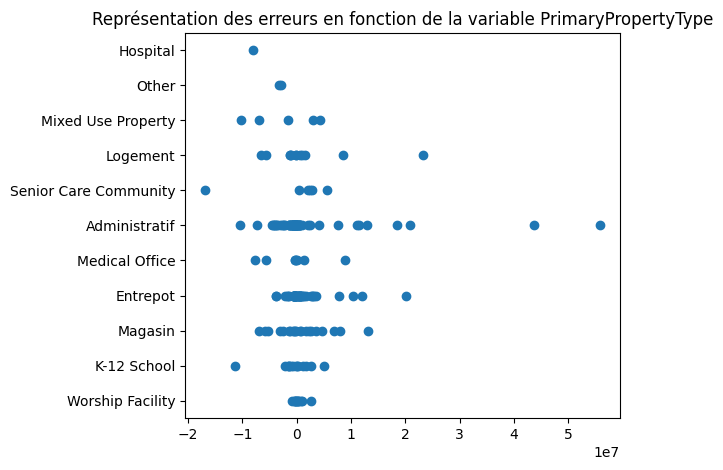

In [123]:
# Affichage du graphique représentant les erreurs de prédiction en fonction d'une variable utilisée par le modèle
graph_erreur_var(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible], 'PrimaryPropertyType', feat_extr=Feat_extr, target_transformer=target_transformer)

Les erreurs de prédiction les plus fortes sont obtenues pour des bâtiments administratifs. On va récupérer les index de ces bâtiments pour les explorer de façon plus approfondie. Cela pourra être fait en étudiant les valeurs shap qui permettent d'interpréter localement chaque prédiction du modèle. Les valeurs shap décomposent la prédiction de chaque observation en une somme de contribution de chaque variable, ce qui permet d'identifier les facteurs ayant le plus influencé les prédictions dans chaque cas. 

In [124]:
# Application d'une transformation sur la variable cible avec TransformedTargetRegressor
model_t = TransformedTargetRegressor(regressor=model, transformer=target_transformer)

# Pipeline
pipeline = Pipeline([
        ('feature_engineering', group_encoder),
        ('Coltransf', Coltransf), 
       ('feature_selection', Feat_extr),
        ('model', model_t) 
    ])
    
# Entraînement du modèle sur l'ensemble complet d'entraînement 
pipeline.fit(trainset[Selected_features], trainset[Variable_cible])
        

# Prédiction des résultats sur le jeu de test
test_predictions = pipeline.predict( testset[Selected_features])

# Calcul de l'erreur
testset['err_hist'] = testset[Variable_cible]- test_predictions
testset['err_hist_abs'] = abs(testset[Variable_cible]- test_predictions)
testset['pred'] = test_predictions


# Affichage de la dataframe
testset.sort_values('err_hist')

,PrimaryPropertyType,Neighborhood,NumberofFloors,PropertyGFAParking,ENERGYSTARScore,SiteEnergyUse(kBtu),StreetType,Electricity_prop,SteamUse_prop,GFAbyfloor,MoreThanOneBuilding,AgeBuilding,nUseType,Target_cat,err_hist,err_hist_abs,pred
787,Senior Care Community,North,6,0,100.0,11019641.0,Street,0.575211,0.000000,40750.000000,False,7,1,Quantile9,-1.686824e+07,1.686824e+07,2.788788e+07
51,K-12 School,East,6,0,100.0,6219841.5,Avenue,0.303528,0.000000,32350.666667,False,108,1,Quantile7,-1.141625e+07,1.141625e+07,1.763609e+07
380,Administratif,Downtown,8,124788,96.0,13568148.0,other,1.000000,0.000000,40184.125000,False,18,2,Quantile9,-1.043032e+07,1.043032e+07,2.399846e+07
131,Mixed Use Property,Downtown,11,195621,94.0,9765777.0,Street,0.990379,0.000000,16887.272727,False,16,3,Quantile9,-1.016751e+07,1.016751e+07,1.993329e+07
57,Hospital,Ballard,5,0,14.0,68090728.0,Avenue,0.517504,0.000000,57066.600000,True,62,2,Quantile10,-8.074488e+06,8.074488e+06,7.616522e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,Entrepot,Greater duwamish,1,0,1.0,21795830.0,Avenue,0.999239,0.000000,101101.000000,False,67,1,Quantile10,2.017236e+07,2.017236e+07,1.623467e+06
120,Administratif,Downtown,63,159600,89.0,61576184.0,Avenue,1.000000,0.000000,18974.396825,False,26,2,Quantile10,2.085528e+07,2.085528e+07,4.072090e+07
2,Logement,Downtown,41,196718,43.0,72587024.0,Avenue,0.682307,0.297113,18521.756098,False,47,1,Quantile10,2.319914e+07,2.319914e+07,4.938789e+07
118,Administratif,Downtown,42,171500,28.0,69519808.0,Avenue,0.987299,0.012701,10623.428571,False,43,4,Quantile10,4.375595e+07,4.375595e+07,2.576386e+07


In [125]:
# Stackage des index correspondant aux propriétés dont l'erreur de prédiction des consommation est la plus sous estimée
index_high_error = testset[testset['err_hist']>10000000].index

Une approche complémentaire pour analyser les erreurs de prédiction consiste à les représenter en fonction des valeurs réelles de la variable cible. Cette représentation permet notamment d’identifier d’éventuels biais systématiques (ex: des zones où le modèle aura tendance à plus sous estimer ou sur estimer les prédictions). Une autre option consiste à examiner la distribution des erreurs à l’aide de boxplots segmentés selon les quantiles de la variable cible. Ces représentations facilitent la détection de valeurs aberrantes, de zones d’instabilité du modèle ou de performances différenciées selon les profils observés.

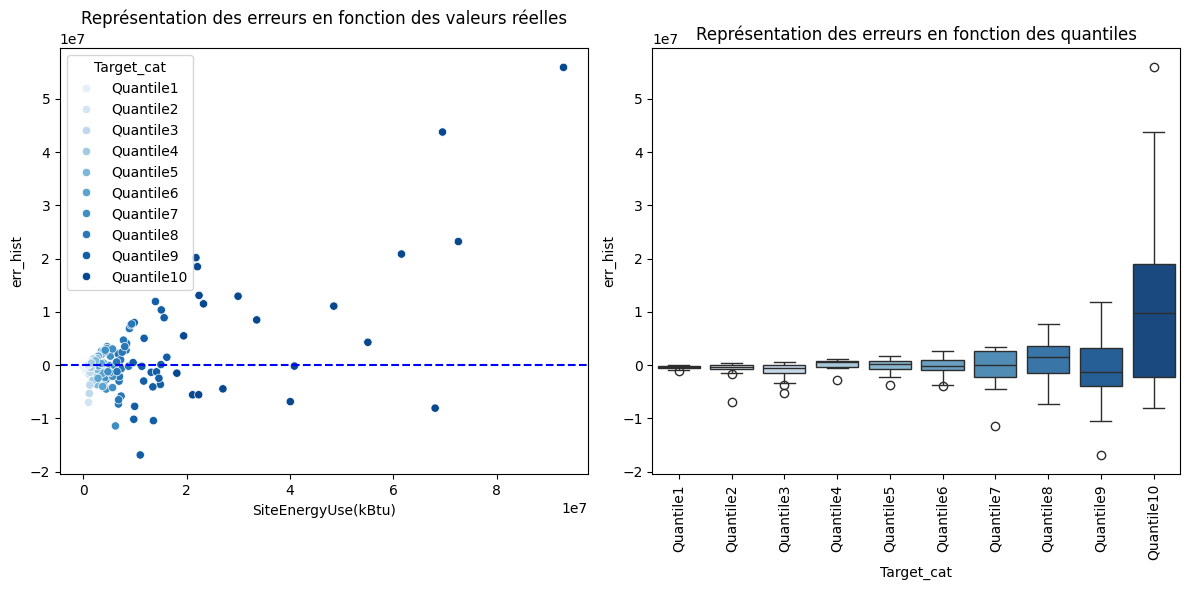

In [126]:
# Construction de la figure 
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Palette pour seaborn
palette = sns.color_palette("Blues", n_colors=testset['Target_cat'].nunique())

# Construction d'un graphique représentant la distribution des erreurs en fonction des différentes classes de quantiles de consommations
sns.boxplot(data=testset, x='Target_cat', y='err_hist', hue='Target_cat', palette=palette, ax=ax[1])
ax[1].tick_params(axis='x', rotation=90)
ax[1].set_title("Représentation des erreurs en fonction des quantiles")

# Construction d'un graphique représentant les erreurs en fonction des valeurs réelles
sns.scatterplot(data= testset, x=Variable_cible, y='err_hist', hue= 'Target_cat', palette='Blues', ax=ax[0])
ax[0].set_title("Représentation des erreurs en fonction des valeurs réelles")
ax[0].axhline(0, color='blue', linestyle='--')

# Affichage final de la figure
plt.tight_layout()
plt.show()

Ces deux représentations graphiques confirment les observations précédentes et mettent en évidence que plus les valeurs de consommations réelles sont élevées plus l'écart entre les valeurs prédites et les valeurs réelles sont importantes.

## Analyse shap

### Fonction

In [127]:
def get_shap_values(Coltransf, model, Xtrain, Ytrain, Xtest, Ytest, feat_extr='passthrough', feature_eng = group_encoder, target_transformer=FunctionTransformer()):

    """
    Calcule les valeurs SHAP pour un modèle entraîné dans un pipeline comprenant ingénierie de features,
    transformations, sélection de variables, et un `TransformedTargetRegressor` appliqué sur la cible.

    Paramètres
     - Coltransf (sklearn.compose.ColumnTransformer): Transformations appliquées aux colonnes (ex: normalisation, encodage).
     - model (estimator sklearn compatible): Modèle final à expliquer (doit avoir une méthode `predict`).
     - Xtrain (pd.DataFrame): Jeu d'entraînement (features brutes).
     - Ytrain (pd.Series ou array-like): Cible d'entraînement.
     - Xtest (pd.DataFrame): Jeu de test (features brutes).
     - Ytest (pd.Series ou array-like): Cible de test (non utilisé dans la fonction mais présent pour cohérence).
     - feat_extr (transformer ou 'passthrough', optionnel (par défaut='passthrough')): Sélection de variables appliquée après transformation des colonnes.
     - feature_eng (transformer, optionnel (par défaut=group_encoder)): Transformation d'ingénierie des variables appliquée en premier.
     - target_transformer (transformer, optionnel (par défaut=FunctionTransformer())): Transformateur appliqué à la cible via `TransformedTargetRegressor`.

    Sortie
     - shap_values_train (shap._explanation.Explanation): Valeurs SHAP calculées sur le jeu d'entraînement.
     - shap_values_test (shap._explanation.Explanation): Valeurs SHAP calculées sur le jeu de test.
     - train_transformed_df (pd.DataFrame): Données d'entraînement transformées et sélectionnées (features finales).
     - test_transformed_df (pd.DataFrame): Données de test transformées et sélectionnées (features finales).
     - explainer (shap.Explainer): Explainer SHAP utilisé pour le calcul.
    """
        
    # Application des premières étapes de la pipeline : feature engineering
    train_engineering = group_encoder.fit_transform(Xtrain)
    test_engineering = group_encoder.transform(Xtest)

    # Application des premières étapes de la pipeline : preprocessing
    train_transformed = Coltransf.fit_transform(train_engineering, Ytrain)
    test_transformed = Coltransf.transform(test_engineering)
    
    # Extraction des index des jeux de données d'entrainement et de test
    index_train = Xtrain.index
    index_test = Xtest.index
        
    #train_transformed = train_transformed.toarray()
    #test_transformed = test_transformed.toarray()
    
    # Application des premières étapes de la pipeline : selection de feature + Extraction des noms des variables
    if feat_extr != 'passthrough':
        train_selection = Feat_extr.fit_transform(train_transformed, Ytrain)
        test_selection = Feat_extr.transform(test_transformed)
        all_feature_names = get_feature_names_from_column_transformer(Coltransf, train_engineering.columns)
        mask = Feat_extr.get_support()  
        selected_columns = [name for name, keep in zip(all_feature_names, Feat_extr.get_support()) if keep]
    else :
        train_selection = train_transformed
        test_selection = test_transformed
        selected_columns = get_feature_names_from_column_transformer(Coltransf, train_engineering.columns)
        

    # Conversion en DataFrame 
    train_transformed_df = pd.DataFrame(train_selection, columns=selected_columns, index=index_train)
    test_transformed_df = pd.DataFrame(test_selection, columns=selected_columns, index=index_test)

    # Entraînement du modèle 
    model_t = TransformedTargetRegressor(regressor=model, transformer=target_transformer)
    model_t.fit(train_transformed_df, Ytrain)

    # Calcul des valeurs SHAP
    explainer = shap.Explainer(model_t.regressor_.predict, train_transformed_df)
    shap_values_train = explainer(train_transformed_df)
    shap_values_test = explainer(test_transformed_df)

 
    return shap_values_train, shap_values_test,  train_transformed_df, test_transformed_df, explainer


In [128]:
def graph_shap_plot_personnalized(shap_val_test, shap_val_train, feature_names, val_prop, shap_prop, prop_leg):

    """
    Génère un graphique personnalisé représentant la relation entre les valeurs d'une variable 
    spécifique et ses valeurs SHAP dans les jeux de données de test et d'entraînement.

    La fonction extrait les valeurs SHAP et les valeurs réelles de la variable ciblée 
    à partir des objets SHAP fournis, crée un DataFrame combiné pour les deux jeux de données, 
    puis affiche un scatter plot différenciant test et train. Une annotation sous forme de flèche 
    est ajoutée pour mettre en évidence un point particulier d'intérêt.

    Paramètres
     - shap_val_test (shap._explanation.Explanation): Objet SHAP pour le jeu de test contenant valeurs SHAP et données d'entrée.
     - shap_val_train (shap._explanation.Explanation): Objet SHAP pour le jeu d'entraînement contenant valeurs SHAP et données d'entrée.
     - feature_names (str): Nom de la variable/features dont on souhaite visualiser la relation SHAP.
     - val_prop (float): Valeur spécifique de la variable `feature_names` pour positionner l'annotation sur l'axe x.
     - shap_prop (float): Valeur SHAP correspondante à `val_prop` pour positionner l'annotation sur l'axe y.
     - prop_leg (str): Texte de légende affiché dans l'annotation (flèche) sur le graphique.
    """
        
    # Extraction des valeurs SHAP et des valeurs de la variable
    feature_indices = shap_val_test.feature_names.index(feature_names)
    feature_vals_test = np.array(shap_val_test.data)[:, feature_indices]
    shap_vals_test = np.array(shap_val_test.values)[:, feature_indices]
    feature_vals_train = np.array(shap_val_train.data)[:, feature_indices]
    shap_vals_train = np.array(shap_val_train.values)[:, feature_indices]

    # Création des dataframes
    df_test = pd.DataFrame({
     f"SHAP_{feature_names}": shap_vals_test,
     f"{feature_names}": feature_vals_test
        })

    df_train = pd.DataFrame({
     f"SHAP_{feature_names}": shap_vals_train,
    f"{feature_names}": feature_vals_train
        })

    # Ajout d'une variable dans les deux jeux de données indiquant si la propriété fait partie du jeu de test ou d'entrainement
    df_test['set']='test'
    df_train['set']='train'

    # Concaténation des deux jeux de données
    data = pd.concat([df_test, df_train])
    
    # Construction du graphique
    fig, axes = plt.subplots(1, 1, figsize=(5, 6))
    axes = [axes]
    sns.scatterplot(data=data, x=feature_names, y= f"SHAP_{feature_names}", hue='set', ax=axes[0]) 
    axes[0].set_title(f"{feature_names}", fontsize=16)
    axes[0].set_ylabel(f"SHAP values {feature_names}", fontsize=14)

    # Extraction des limites de l’axe pour ajuster la taille de la flèche
    x_min0, x_max0 = axes[0].get_xlim()
    y_min0, y_max0 = axes[0].get_ylim()

    # Définition de la taille proportionnelle de la flèche par rapport à l'image
    dx0 = (x_max0 - x_min0) * 0.05 
    dy0 = (y_max0 - y_min0) * 0.05

    # Ajout d'une flèche pointant vers la propriété étudiée
    axes[0].annotate(prop_leg,
                 xy=(val_prop, shap_prop),
                 xytext=(val_prop + dx0, shap_prop + dy0),
                 arrowprops=dict(arrowstyle="->", lw=1.5),
                 fontsize=12,
                 bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", lw=1))

    # Affichage des graphiques
    plt.tight_layout()
    plt.show()


###  Analyse

In [129]:
# Appel de la fonction et stockage des résultats
shap_val_train, shap_val_test, train_transf, test_transf, expl = get_shap_values(
                 Coltransf, model,
                 trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 feat_extr=Feat_extr, feature_eng=group_encoder)


PermutationExplainer explainer: 779it [01:23,  8.73it/s]                                                               
PermutationExplainer explainer: 196it [00:20,  4.40it/s]                                                               


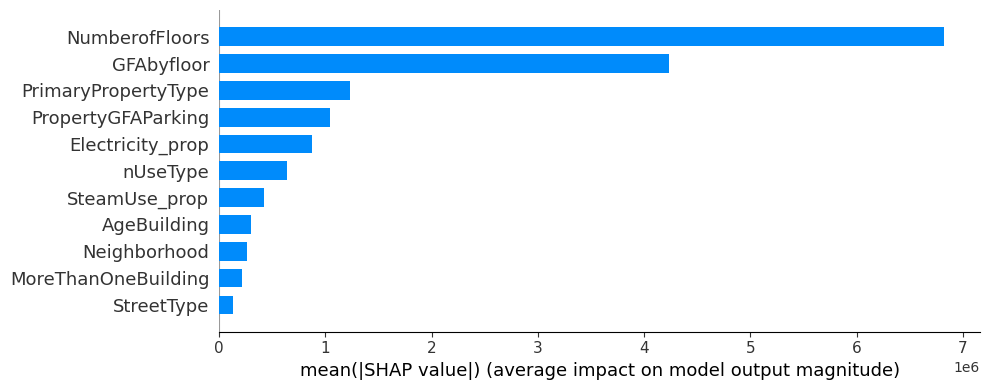

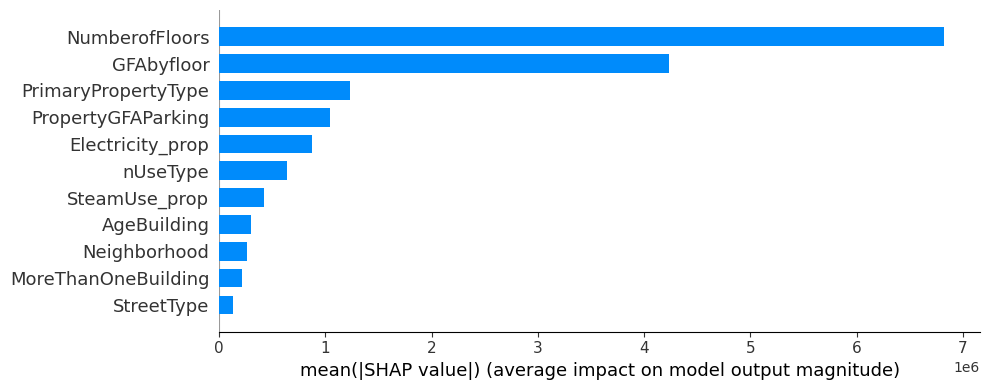

In [130]:
# Désactivation des warnings de type Futur pour plus de lisibilité
warnings.simplefilter(action='ignore', category=FutureWarning)

# Visualisation des résultats de la contribution globale des features
shap.summary_plot(shap_val_test, test_transf, plot_type="bar", plot_size=(10, 4))
shap.summary_plot(shap_val_test, train_transf, plot_type="bar",  plot_size=(10, 4))

Les summary plot générés par SHAP représentent la contribution moyenne des différentes feature dans la prédiction des valeurs de la consommation énergétique. On retrouve un ordre global similaire à celui obtenu par l'anlyse de la feature importance classique implanté dans sickit learn. Le nombre d'étage reste la variable qui contribue le plus à la prédiction.Quelques variations dans le classement apparaissent mais celles ci sont minimes. Pour aller plus loin dans l'analyse de la contribution des features on peut également regarder dans quelle direction les différentes features ont impacté sur les valeurs prédites. 

In [131]:
# Désactivation des warnings de type Futur pour plus de lisibilité
warnings.simplefilter(action='ignore', category=FutureWarning)

# Extraction du nom du modèle
model_name = model.__class__.__name__

# Visualisation et sauvegarde du plot SHAP global test
shap.summary_plot(shap_val_test, test_transf, plot_type="bar", plot_size=(10, 4), show=False)
plt.tight_layout()
plt.savefig(f"../Output/Modélisation/Explicativité/Consommations/shap_summary_test - {model_name}.png", dpi=300, bbox_inches='tight')
plt.close() 

# Visualisation et sauvegarde du plot SHAP global train
shap.summary_plot(shap_val_test, train_transf, plot_type="bar", plot_size=(10, 4), show=False)
plt.tight_layout()
plt.savefig(f"../Output/Modélisation/Explicativité/Consommations/shap_summary_train - {model_name}.png", dpi=300, bbox_inches='tight')
plt.close()

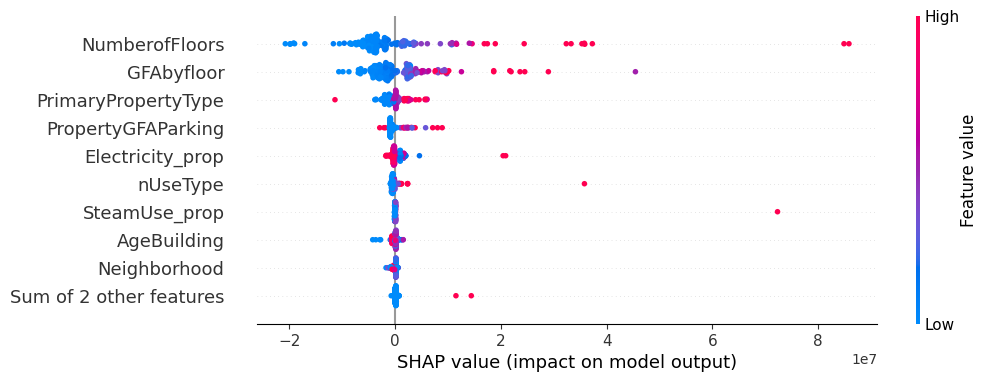

In [132]:
# importance et impact directionnel des variables
shap.plots.beeswarm(shap_val_test, plot_size=(10, 4))

On remarque alors que  les propriétés avec un nombre d'étage élevé ont tendance à avoir des valeurs SHAP positive et élevées ce qui signifie qu'elles contribuent à augmenter la valeur de consommation énergétique pédite par le modèle. Autrement dit plus une propriété a un nombre d'étage élevé plus la valeur prédite est également élevée. Les même observations peuvent être faites pour la surface par étage. Afin de mieux comprendre les fortes erreurs de prédictions on peut utiliser les valeurs SHAP pour regarder localement pour une propriété donnée la contribution de chacune des features dans la prédiction. On va regarder quelques exemples de propriétés dont la consommation énergétique été prédite avec une forte sous estimation.

In [133]:
# Création d'une nouvelle figure
plt.figure(figsize=(10, 4))

# Affichage du plot SHAP beeswarm
shap.plots.beeswarm(shap_val_test, show=False)

# Sauvegarde
plt.savefig(f"../Output/Modélisation/Explicativité/Consommations/shap_beeswarm_test -  {model_name}.png", dpi=300, bbox_inches='tight')

# Fermeture de la figure la figure
plt.close()

In [134]:
# Affichage des index correspondant aux propriété dont la consommation a été fortement sous estimée
index_high_error

Index([198, 118, 324, 140, 120, 145, 411, 137, 393, 360, 2, 247], dtype='int64')

PrimaryPropertyType    Administratif
Neighborhood                Downtown
NumberofFloors                    42
PropertyGFAParking            171500
ENERGYSTARScore                 28.0
SiteEnergyUse(kBtu)       69519808.0
StreetType                    Avenue
Electricity_prop            0.987299
SteamUse_prop               0.012701
GFAbyfloor              10623.428571
MoreThanOneBuilding            False
AgeBuilding                       43
nUseType                           4
Target_cat                Quantile10
err_hist                  43755948.0
err_hist_abs              43755948.0
pred                      25763860.0
Name: 118, dtype: object


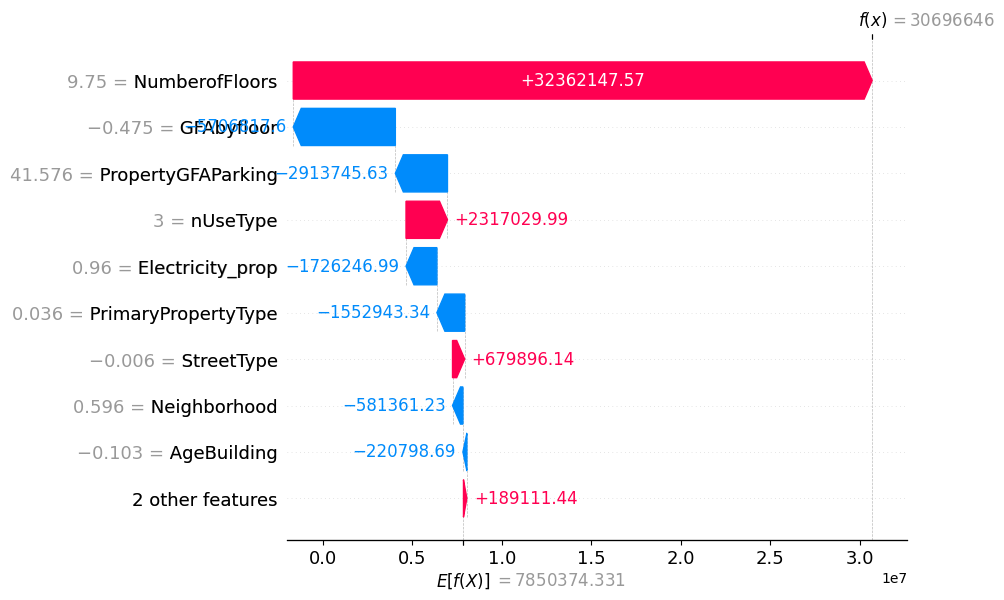

In [135]:
# Exctration de la position dans le jeu de données et affichage de ses caractéristiques
position = testset.index.get_loc(118)
print(testset.loc[118])

# Visualisation des contributions locales des variables utilisées dans le modèle
shap.plots.waterfall(shap_val_test[position])

Ici on peut voir que les variables qui ont le plus contribué à la sous estimation de la consommation énergétique de cette propriété sont les variables de surface par étage, de surface de parking, de proportion d'élétricité utilisée et le type de d'usage associé. On peut regarder comment se situe cette propriété par rapport à l'ensemble du jeu de données sur ces variables. 

In [136]:
# Création d'une nouvelle figure
plt.figure(figsize=(10,4))           

# Visualisation des contributions locales des variables utilisées dans le modèle
shap.plots.waterfall(shap_val_test[position], show=False)

# Sauvegarde
plt.savefig(f"../Output/Modélisation/Explicativité/Consommations/shap_waterfall_118 - {model_name}.png", dpi=300, bbox_inches="tight")

# Fermeture de la figure
plt.close()

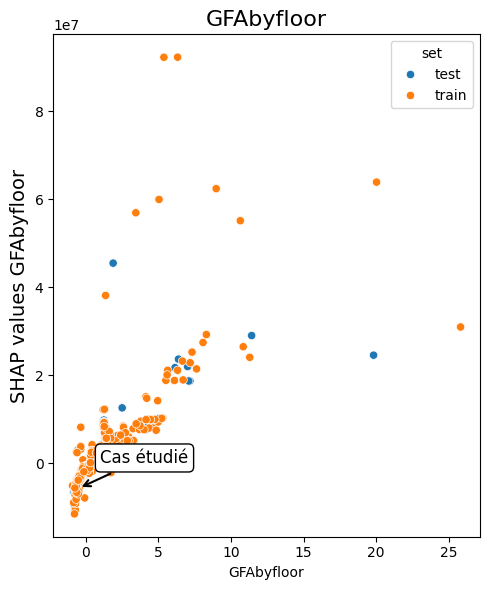

In [137]:
# Représentation des valeurs shap en fonction des valeurs des features
graph_shap_plot_personnalized(shap_val_test, shap_val_train, 
                              feature_names='GFAbyfloor', 
                              val_prop=-0.475, 
                              shap_prop=-5706817,
                               prop_leg = "Cas étudié")

On constate en effet que la surface par étage de cette propriété est située dans les valeurs les plus basses du jeu de données ce qui a conduit le modèle a tirer les prédictions des consommations énergétique vers le bas. Cette observation confirme la forte infuluence de la variable surface par étage dans la décision du modèle et les prédictions faites par le modèle semblent donc cohérentes avec la façon dont les features contribuent dans la modélisation.

Il est donc très probable que d'autres facteurs non présents dans le jeu de données et donc non pris en compte dans le modèle comme l'isolation des bâtiments aient pu jouer dans ces erreurs de prédictions. Il pourrait être intéressant de revenir sur les cas où les valeurs ont été fortement sous estimés afin de déterminer s'ils correspondent à des bâtiments particulièrement mal isolés ou présentants d'autres caractéristiques spécifiques non intégrées dans le modèle. D'autres facteurs exogènes comme les comportements humains peuvent également impacter les consommations énergétiques. Enfin  il n'est pas exclu que certaines valeurs obersées soient éronnées ou mal renseignée ce qui pourrait fausser la prédiction des valeurs de ces bâtiments.

# Conclusions

Ce projet avait pour objectif de modéliser la consommation énergétique et les émissions en gaz a effet de serre des bâtiments non résidentiels de la ville de Seattle dans le cadre de la transition écologique engagé par la ville. Il s'agissait également d'évaluer l'impact de score ENERGYSTAR sur les performances des modèles mis en place. 

Concernant la modélisation des consommations énergétiques présentée ici, plusieurs approches ont été testées allant de modèles linéaires simples à des modèles plus complexes comme le SVR et le XGBregressor. Une phase d'optmisation par recherche en grille a permis d'ajuster à la fois les hyperparamètres des différents modèles testés et les stratégies de prétraitement des données (normalisation, encodages des variables catégorielles...). 

Le modèle final retenu est un XGBregressor. Ce modèle a montré de bonne capacité de généralisation avec des performances satisfaisantes sur le jeu de test malgrés certaines erreurs importantes sur des cas spécifiques. L'analyse des erreurs et des contributions de variable a permis d'identifier ces cas spécifiques pour lesquels certaines caractéristiques sont peut être manquantes. Enfin, bien que le score ENERGYSTAR ait permis une amélioration des performances, son inclusion dans le modèle final a été écarté en raison de son lien direct avec les consommation réelles.